In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 232,833
Discriminator parameters: 138,689
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.325236	G_loss: 1.056893
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.269120	G_loss: 0.945393
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.246491	G_loss: 0.982184
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.386197	G_loss: 0.896948
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.267527	G_loss: 0.842944
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.242867	G_loss: 0.844822
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.302809	G_loss: 0.577668
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.124822	G_loss: 0.887767
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.245798	G_loss: 1.077876
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.228289	G_loss: 0.998925
====> Epoch: 1 Train D_loss: 1.2440, Train G_loss: 0.9543
====> Epoch: 1 Val D_loss: 1.3000, Val G_loss: 0.8261
📈 Epoch 1 Summary:
   Train D Loss: 1.2440, Val D Loss: 1.3000
   Train G Loss: 0.9543, Val G Loss: 0.8261

📊 Epoch 2/100
------------------------

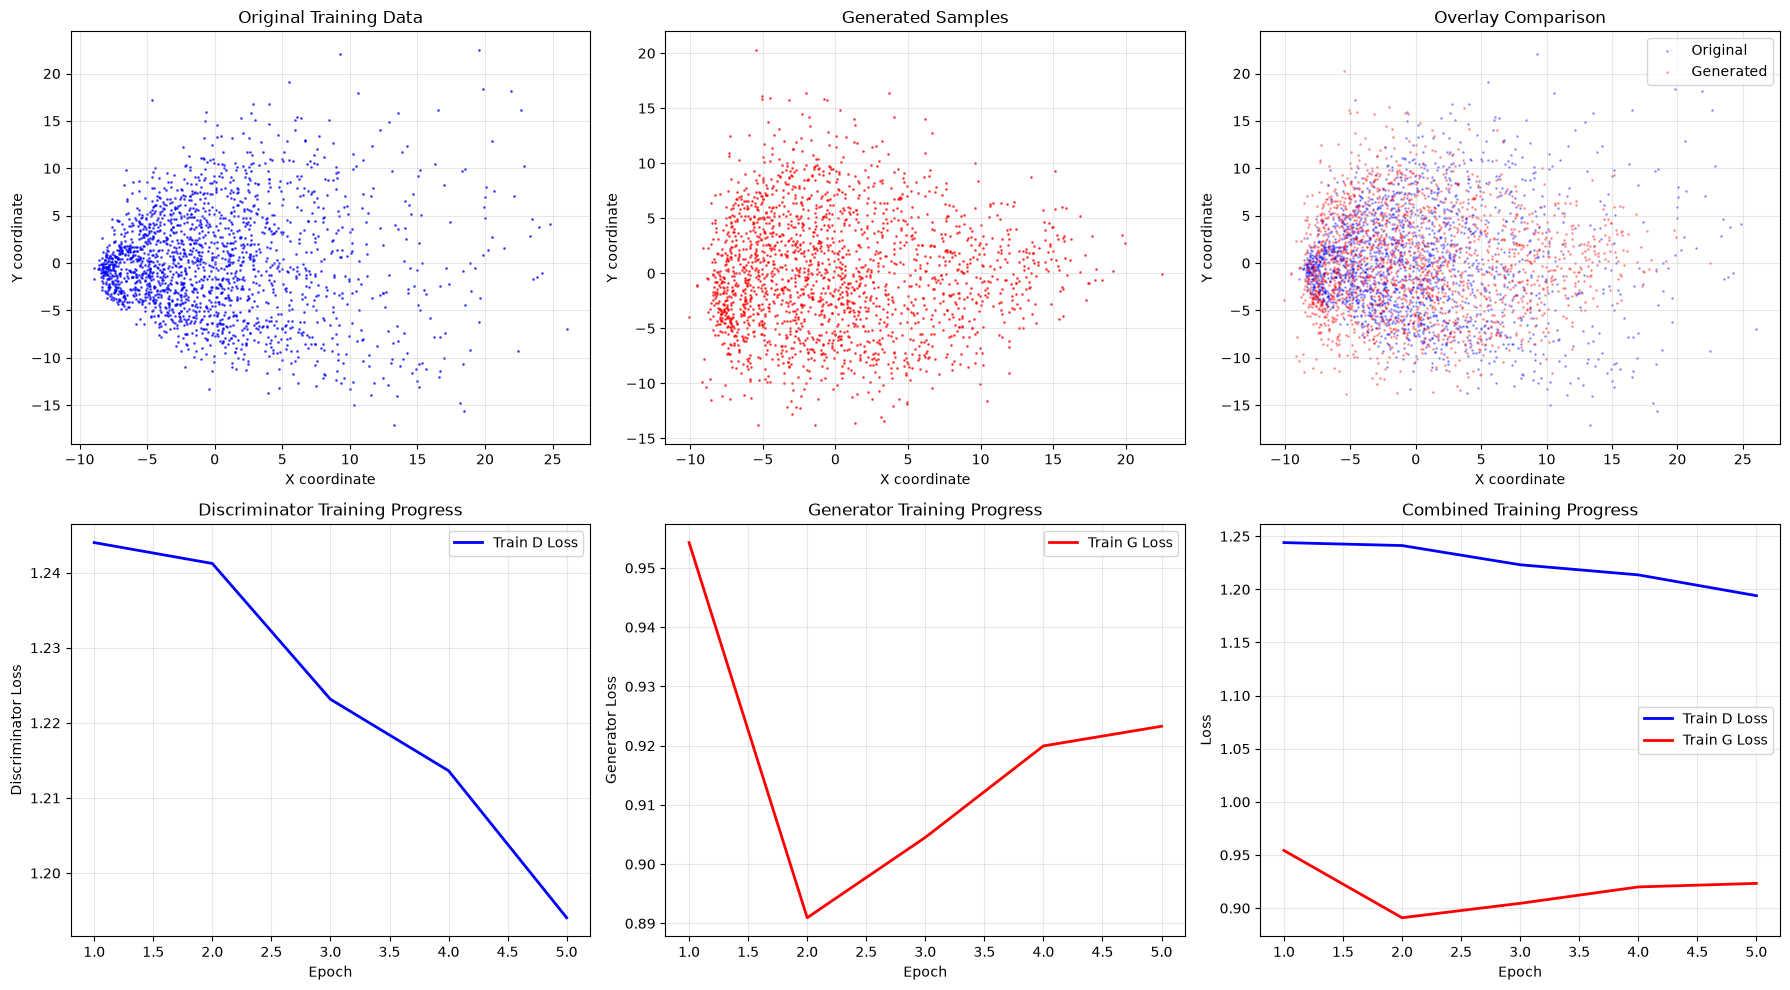

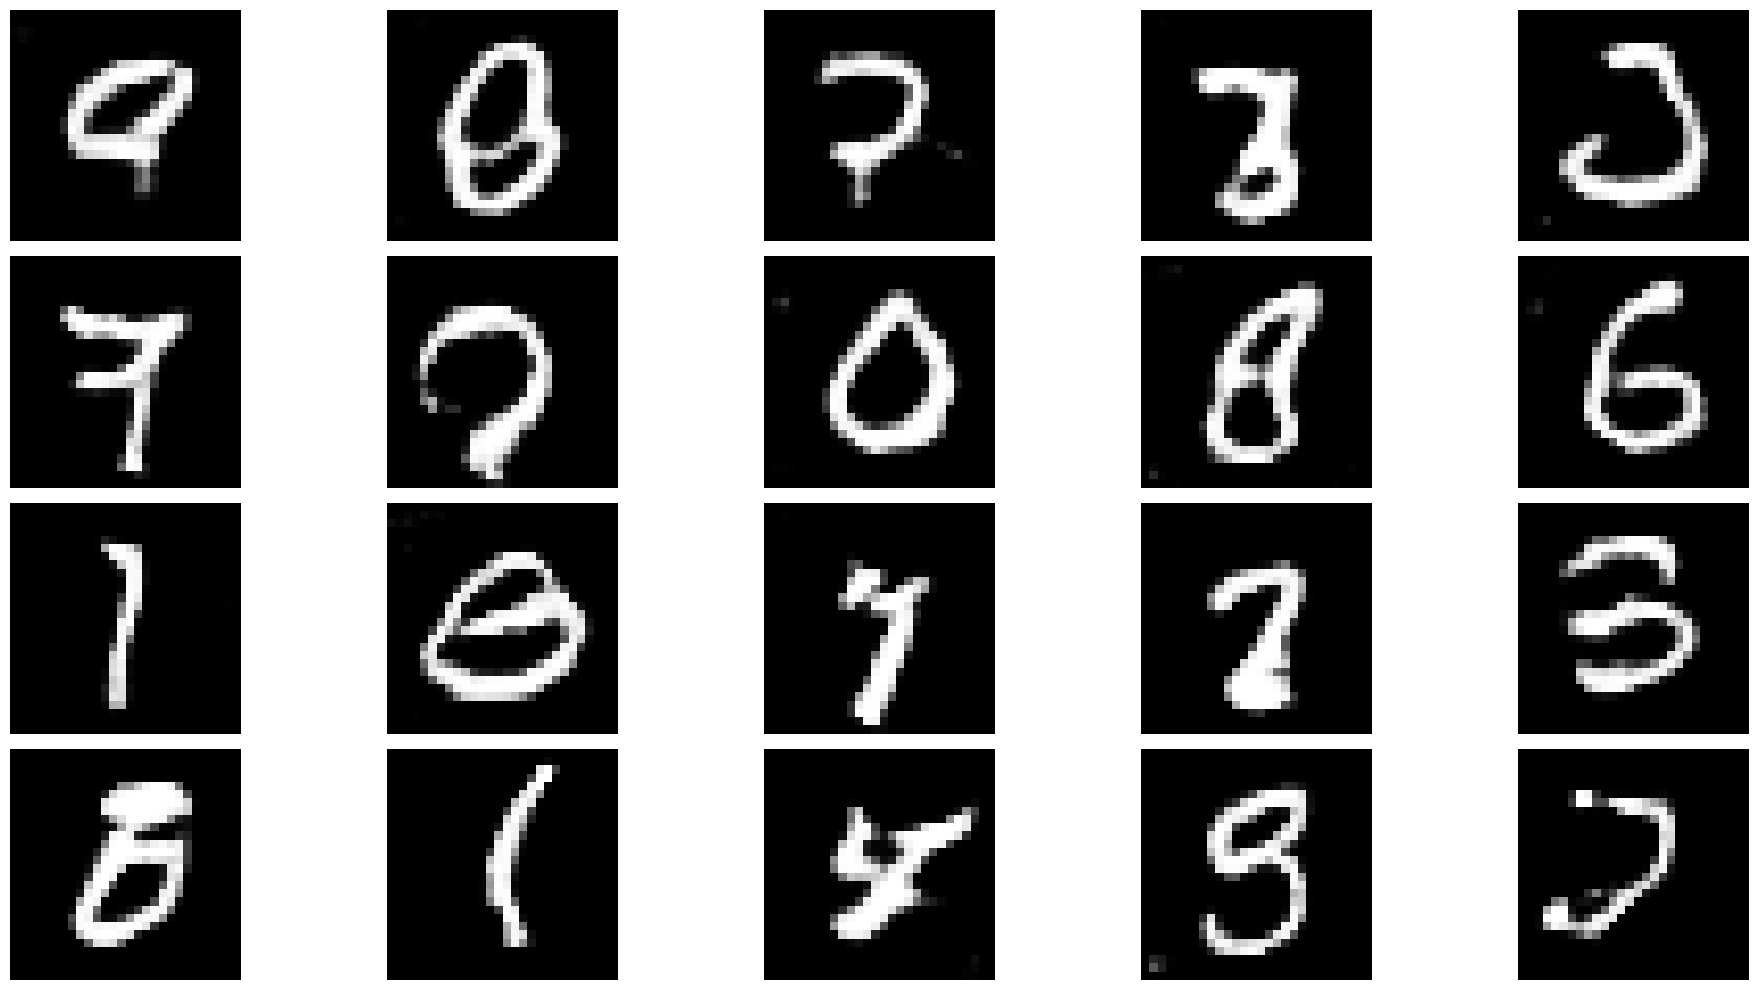

📈 Epoch 5 Summary:
   Train D Loss: 1.1941, Val D Loss: 1.2736
   Train G Loss: 0.9233, Val G Loss: 0.6900

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.216805	G_loss: 0.917362
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.296233	G_loss: 0.882109
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.427679	G_loss: 0.368170
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.204326	G_loss: 0.866783
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.311984	G_loss: 0.529339
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.328013	G_loss: 1.315175
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.208707	G_loss: 0.782196
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.106030	G_loss: 0.910974
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.266587	G_loss: 0.894445
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.194266	G_loss: 0.887775
====> Epoch: 6 Train D_loss: 1.1867, Train G_loss: 0.9487
====> Epoch: 6 Val D_loss: 1.2869, Val G_loss: 0.9293
📈 Epoch 6 Summary:
   Train D Loss: 1.1867, Val D Loss: 1.2869
   Train G Loss: 0.9487, Val G Loss: 0

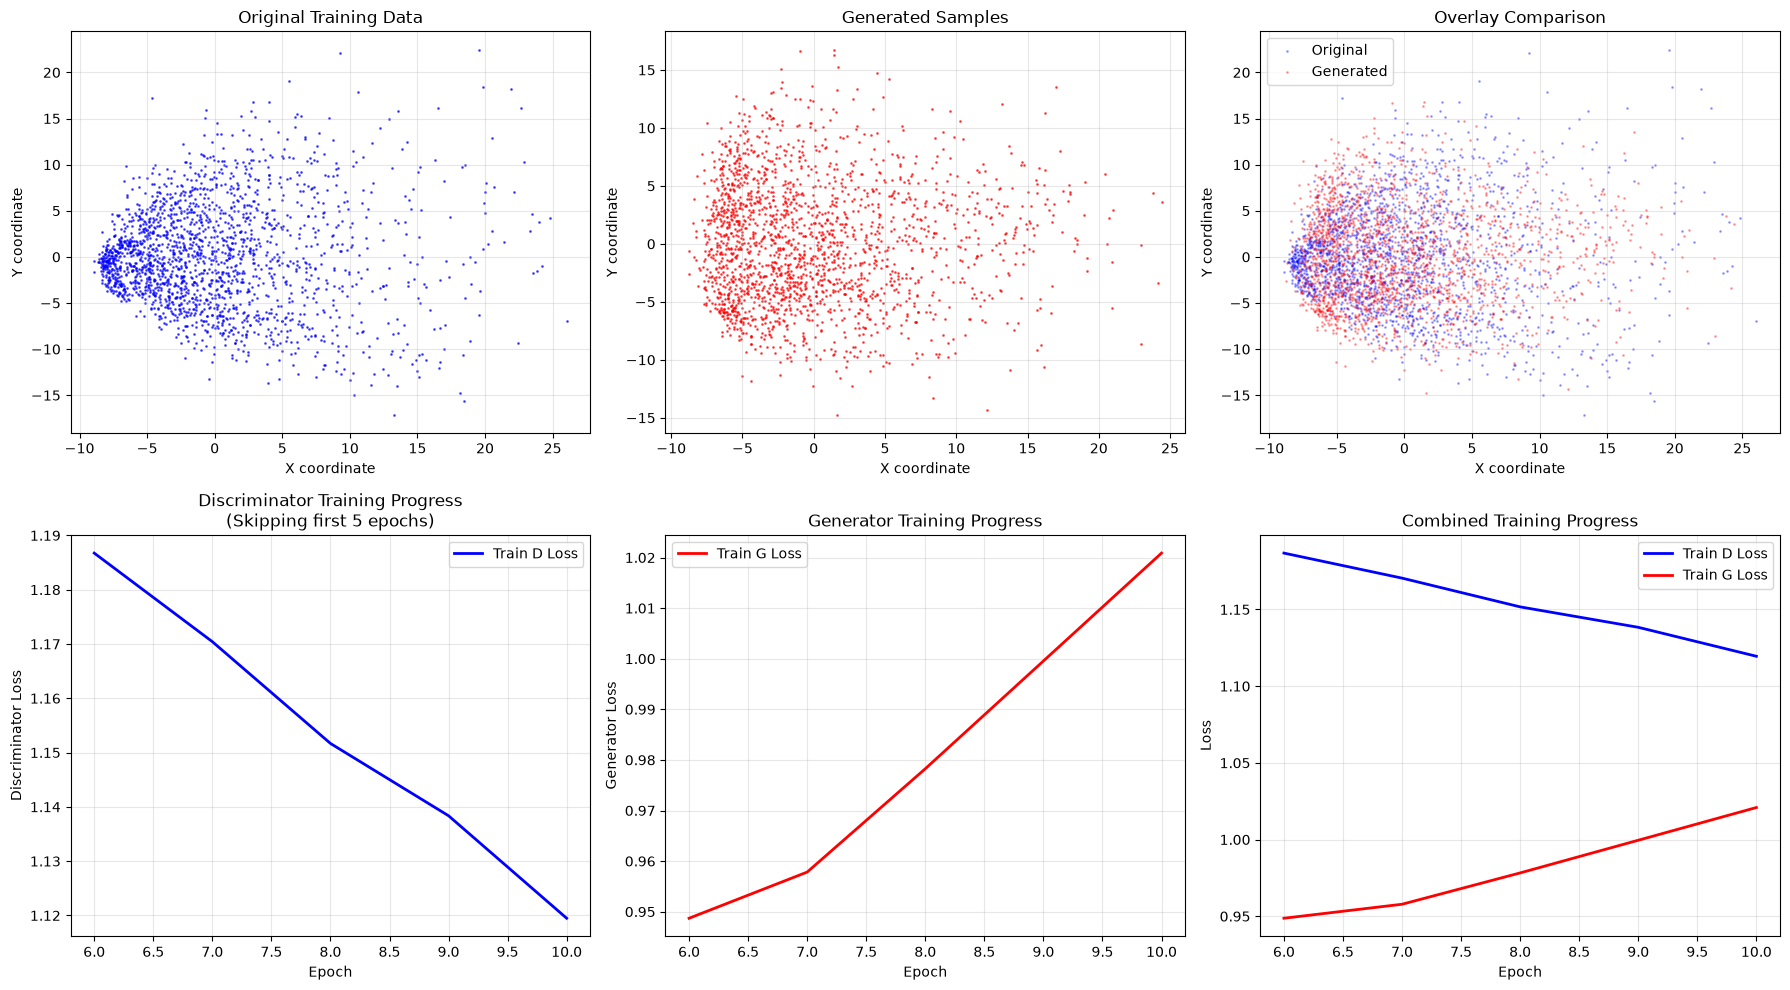

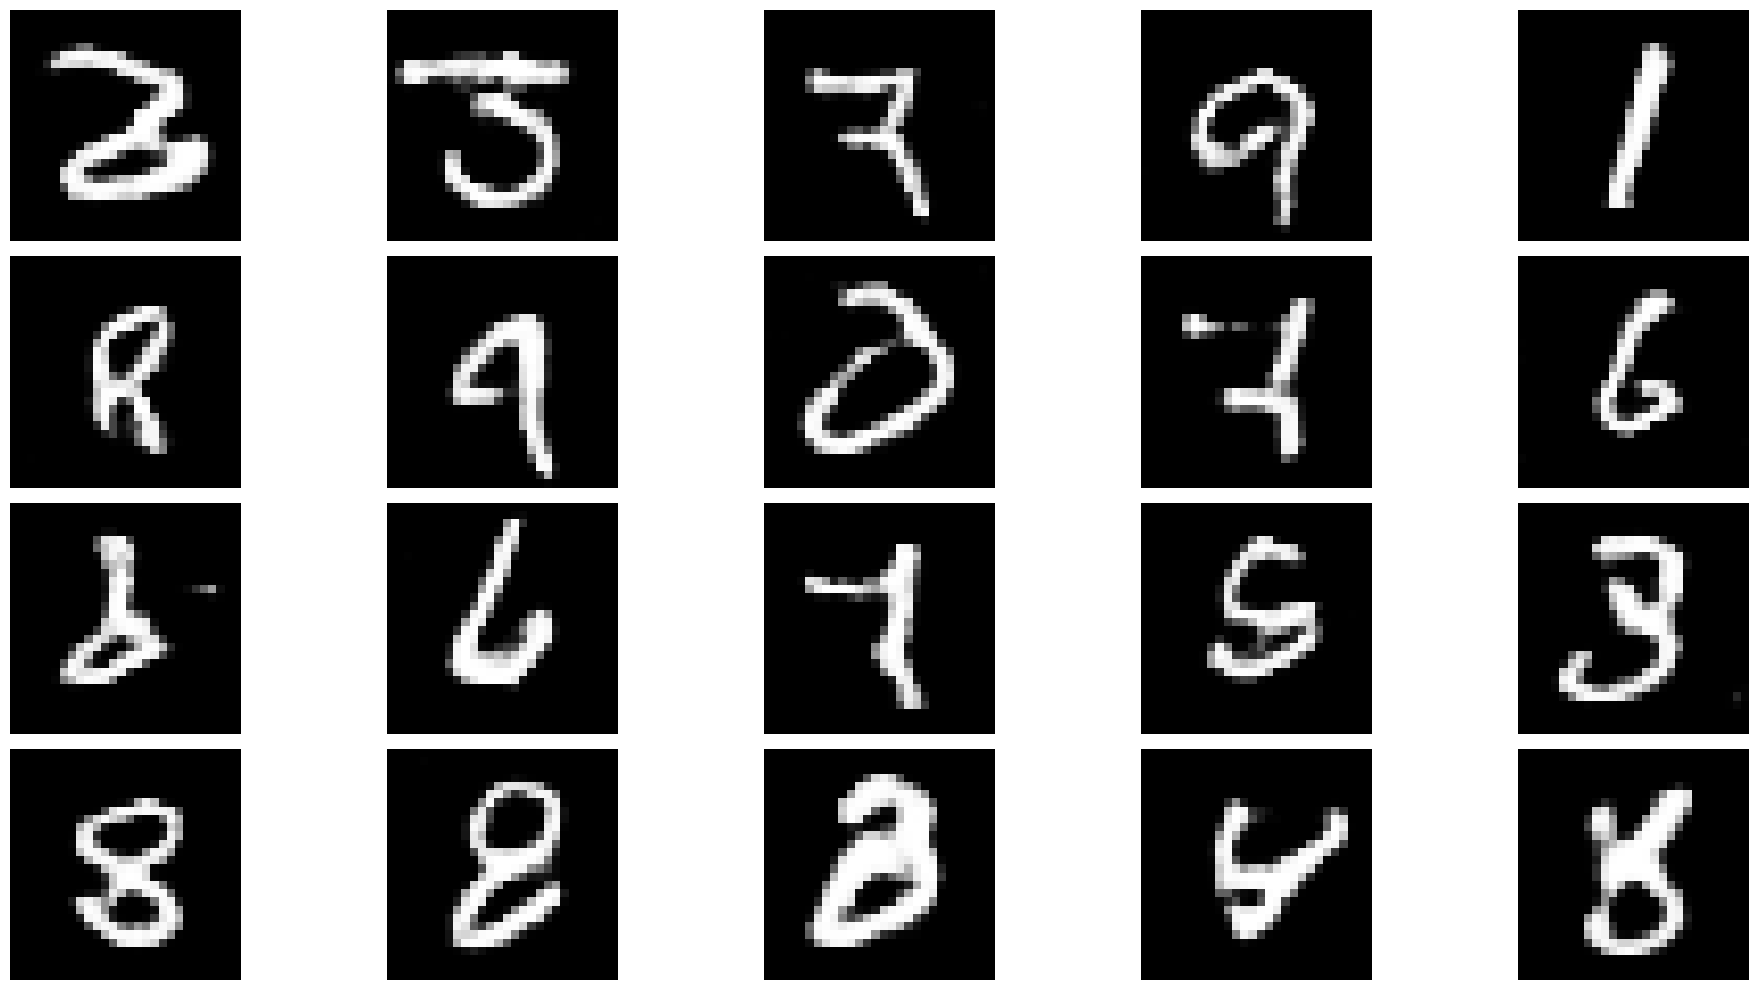

📈 Epoch 10 Summary:
   Train D Loss: 1.1195, Val D Loss: 1.2507
   Train G Loss: 1.0209, Val G Loss: 0.6567

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.055132	G_loss: 0.991449
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.036621	G_loss: 0.831188
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.070402	G_loss: 1.096541
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.108987	G_loss: 1.019215
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.097619	G_loss: 1.467775
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.053657	G_loss: 0.757311
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.066088	G_loss: 0.960999
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.163131	G_loss: 0.837617
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.114002	G_loss: 1.067995
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.970564	G_loss: 0.905012
====> Epoch: 11 Train D_loss: 1.0978, Train G_loss: 1.0345
====> Epoch: 11 Val D_loss: 1.2103, Val G_loss: 1.0571
📈 Epoch 11 Summary:
   Train D Loss: 1.0978, Val D Loss: 1.2103
   Train G Loss: 1.0345

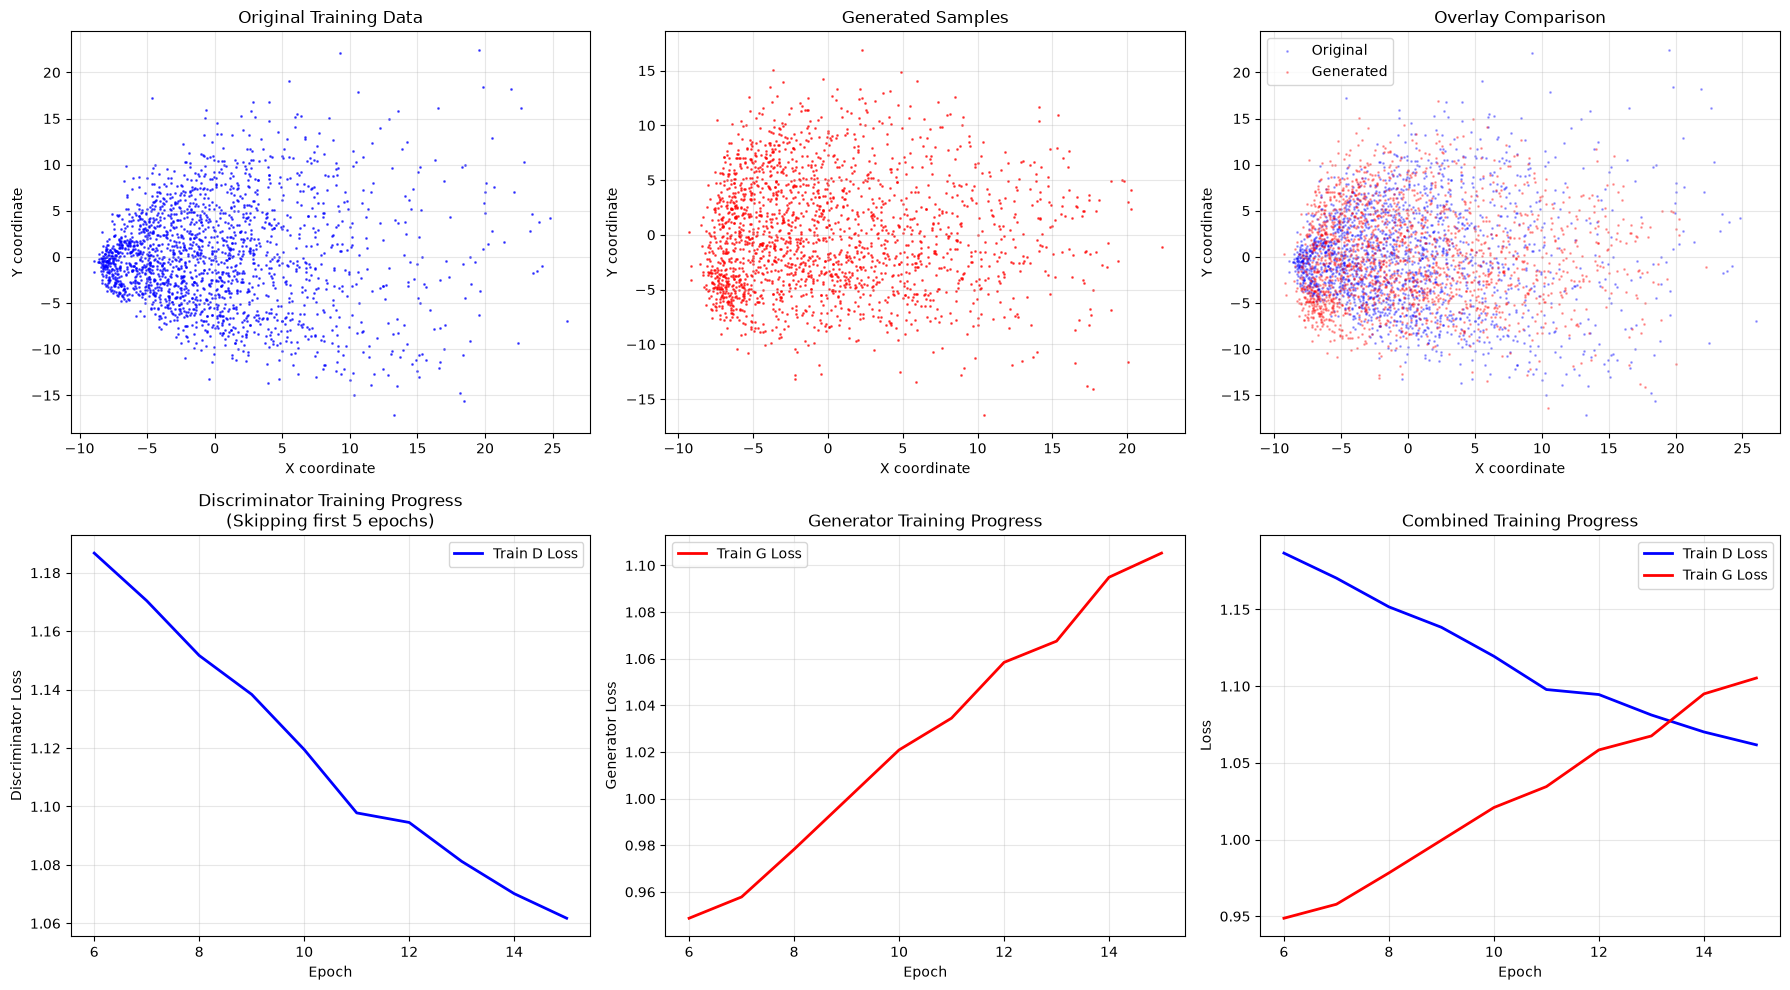

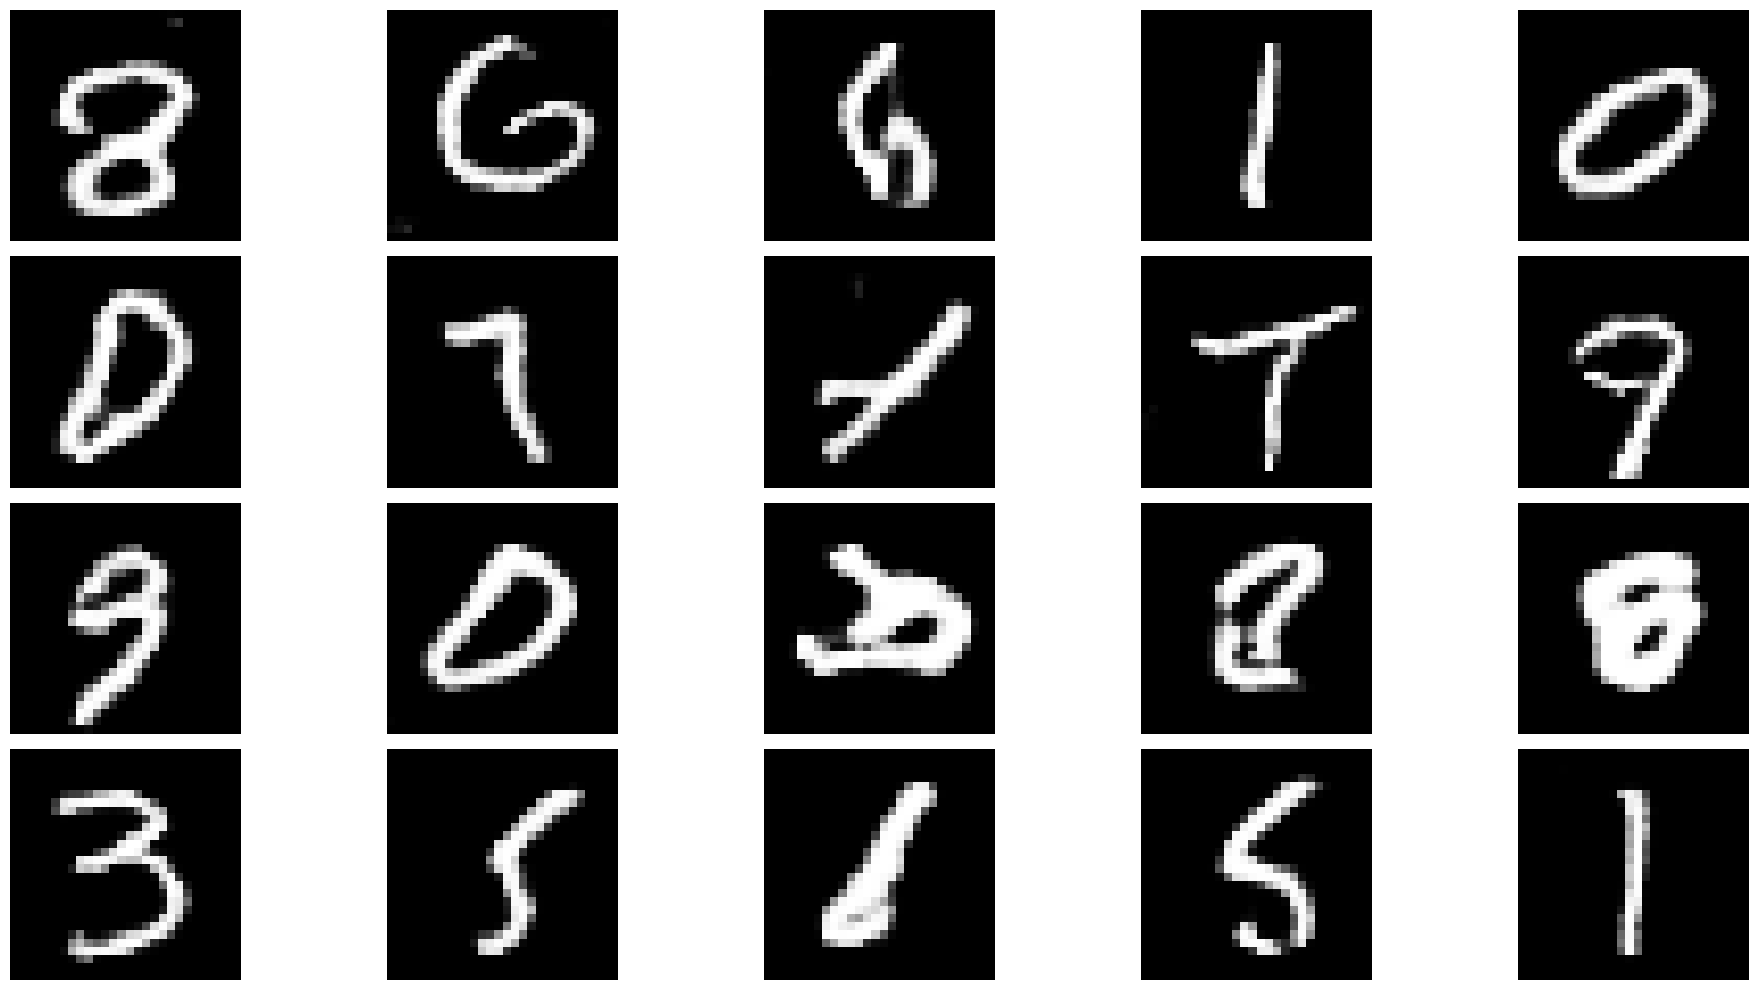

📈 Epoch 15 Summary:
   Train D Loss: 1.0617, Val D Loss: 1.1752
   Train G Loss: 1.1053, Val G Loss: 0.8713

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.092093	G_loss: 1.173628
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.982864	G_loss: 1.451697
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.939585	G_loss: 1.253239
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.189554	G_loss: 1.083549
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.288247	G_loss: 1.690378
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.965222	G_loss: 1.521989
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.013404	G_loss: 1.202592
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.081646	G_loss: 0.880251
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.062469	G_loss: 0.989763
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.051863	G_loss: 1.193443
====> Epoch: 16 Train D_loss: 1.0522, Train G_loss: 1.1191
====> Epoch: 16 Val D_loss: 1.8413, Val G_loss: 0.2386
📈 Epoch 16 Summary:
   Train D Loss: 1.0522, Val D Loss: 1.8413
   Train G Loss: 1.1191

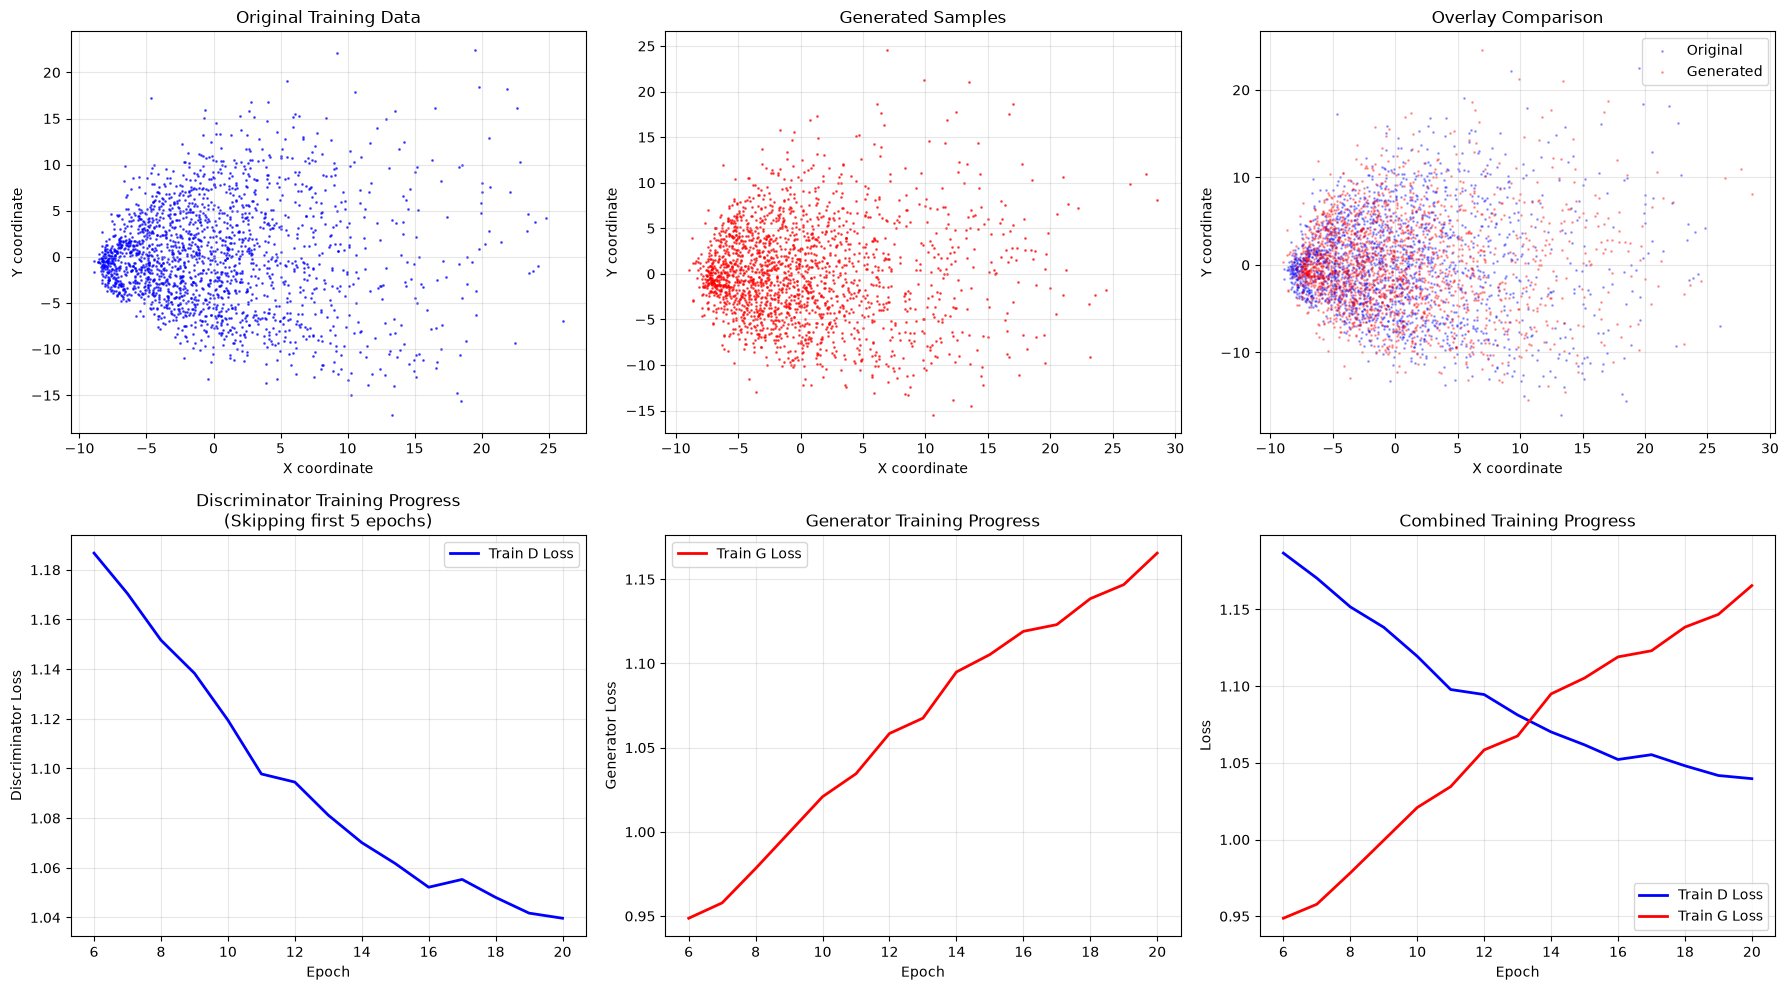

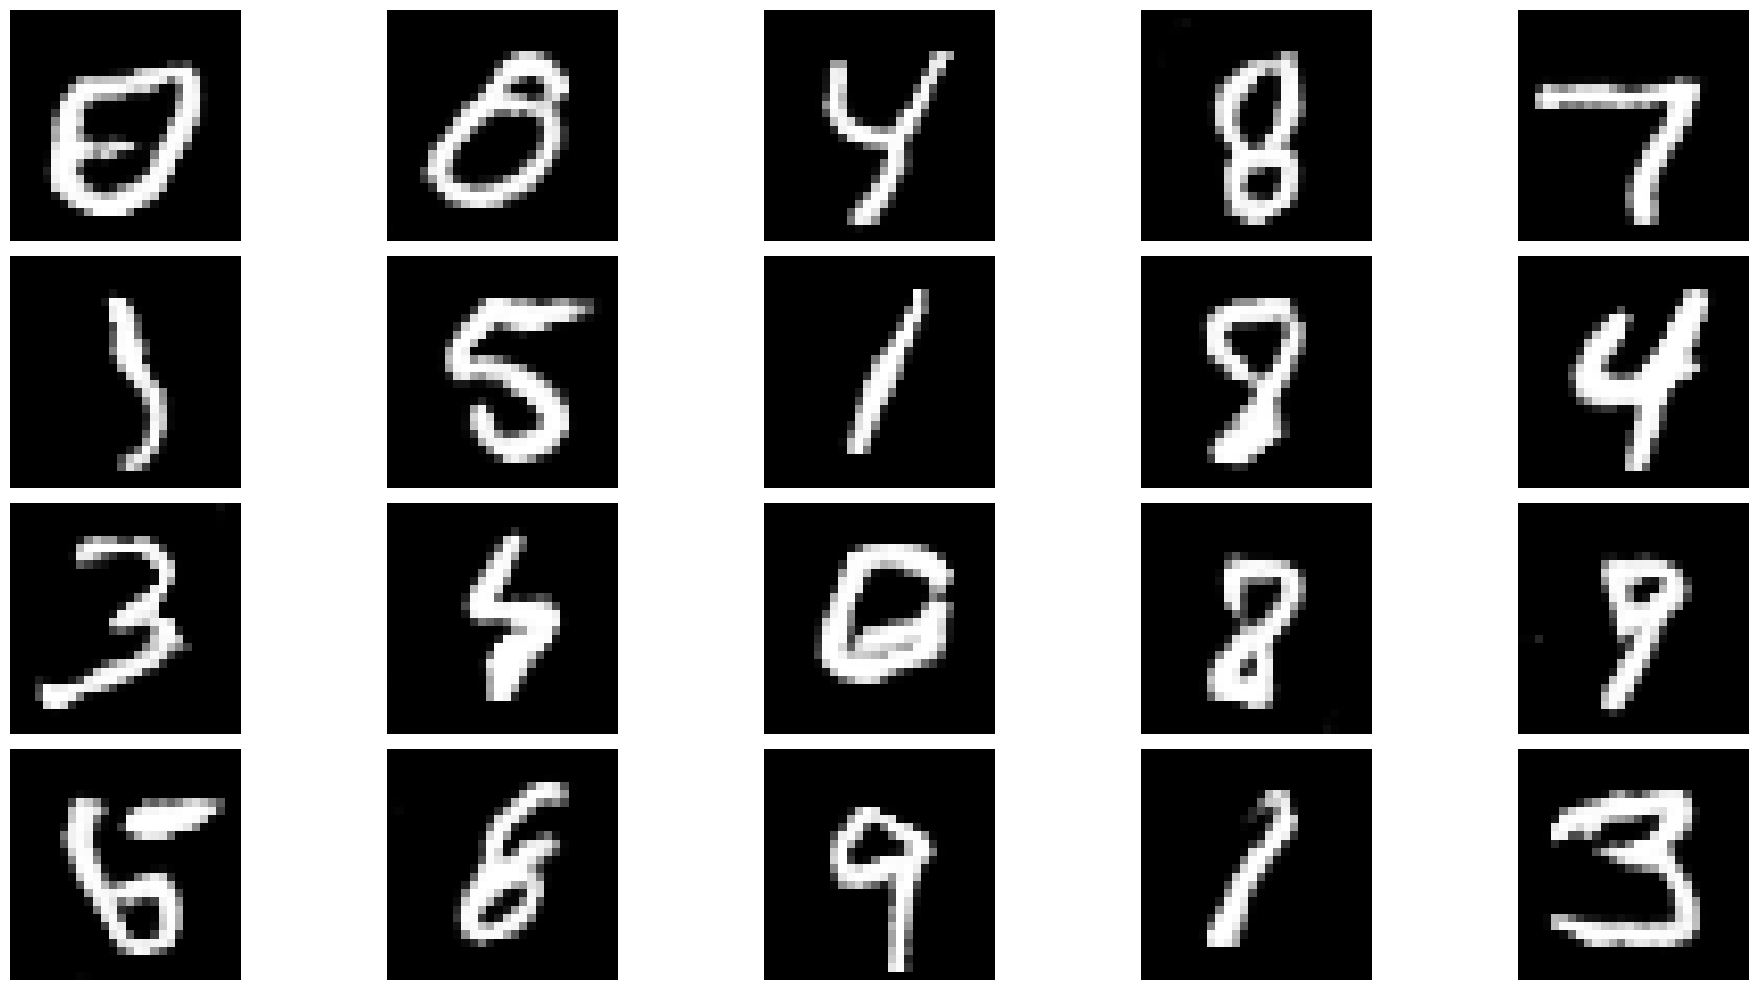

📈 Epoch 20 Summary:
   Train D Loss: 1.0397, Val D Loss: 1.2452
   Train G Loss: 1.1655, Val G Loss: 0.6782

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.070509	G_loss: 1.311519
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.075752	G_loss: 1.154905
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.064700	G_loss: 1.855546
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.112190	G_loss: 1.686059
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.006360	G_loss: 1.022443
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.003390	G_loss: 1.184282
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.049367	G_loss: 1.508658
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.033522	G_loss: 1.557103
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.043978	G_loss: 1.203539
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.895136	G_loss: 1.720686
====> Epoch: 21 Train D_loss: 1.0319, Train G_loss: 1.1663
====> Epoch: 21 Val D_loss: 1.2046, Val G_loss: 0.7801
📈 Epoch 21 Summary:
   Train D Loss: 1.0319, Val D Loss: 1.2046
   Train G Loss: 1.1663

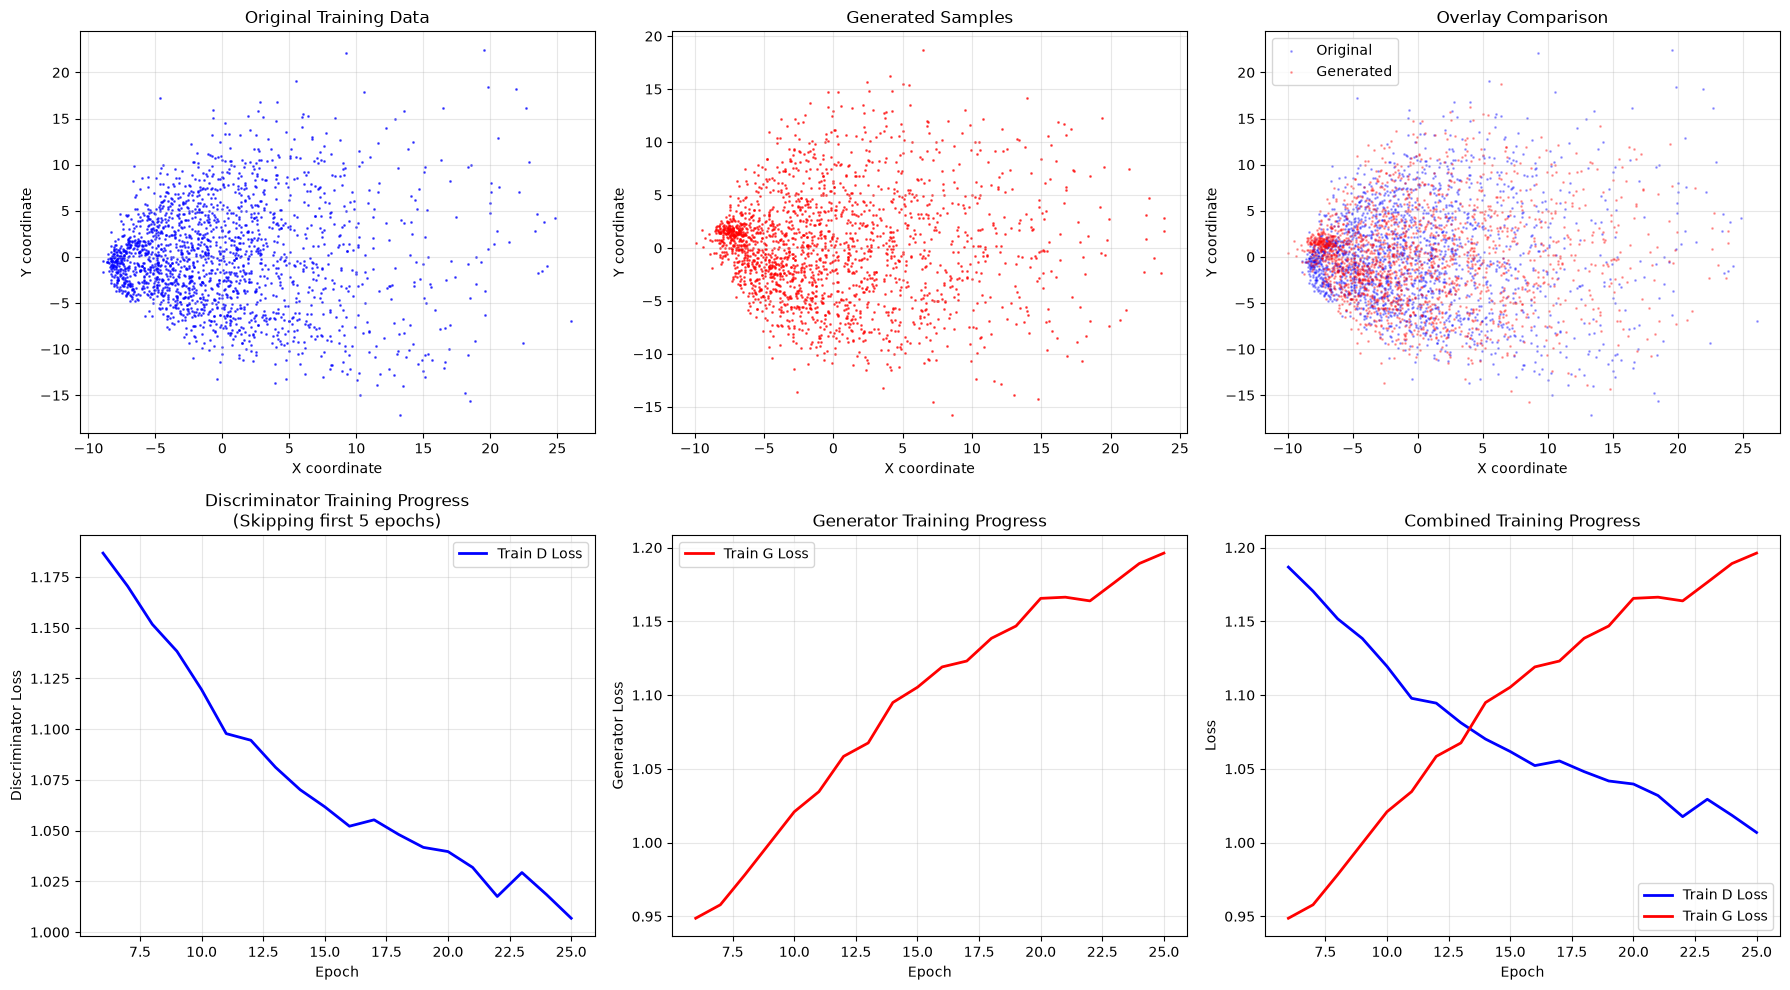

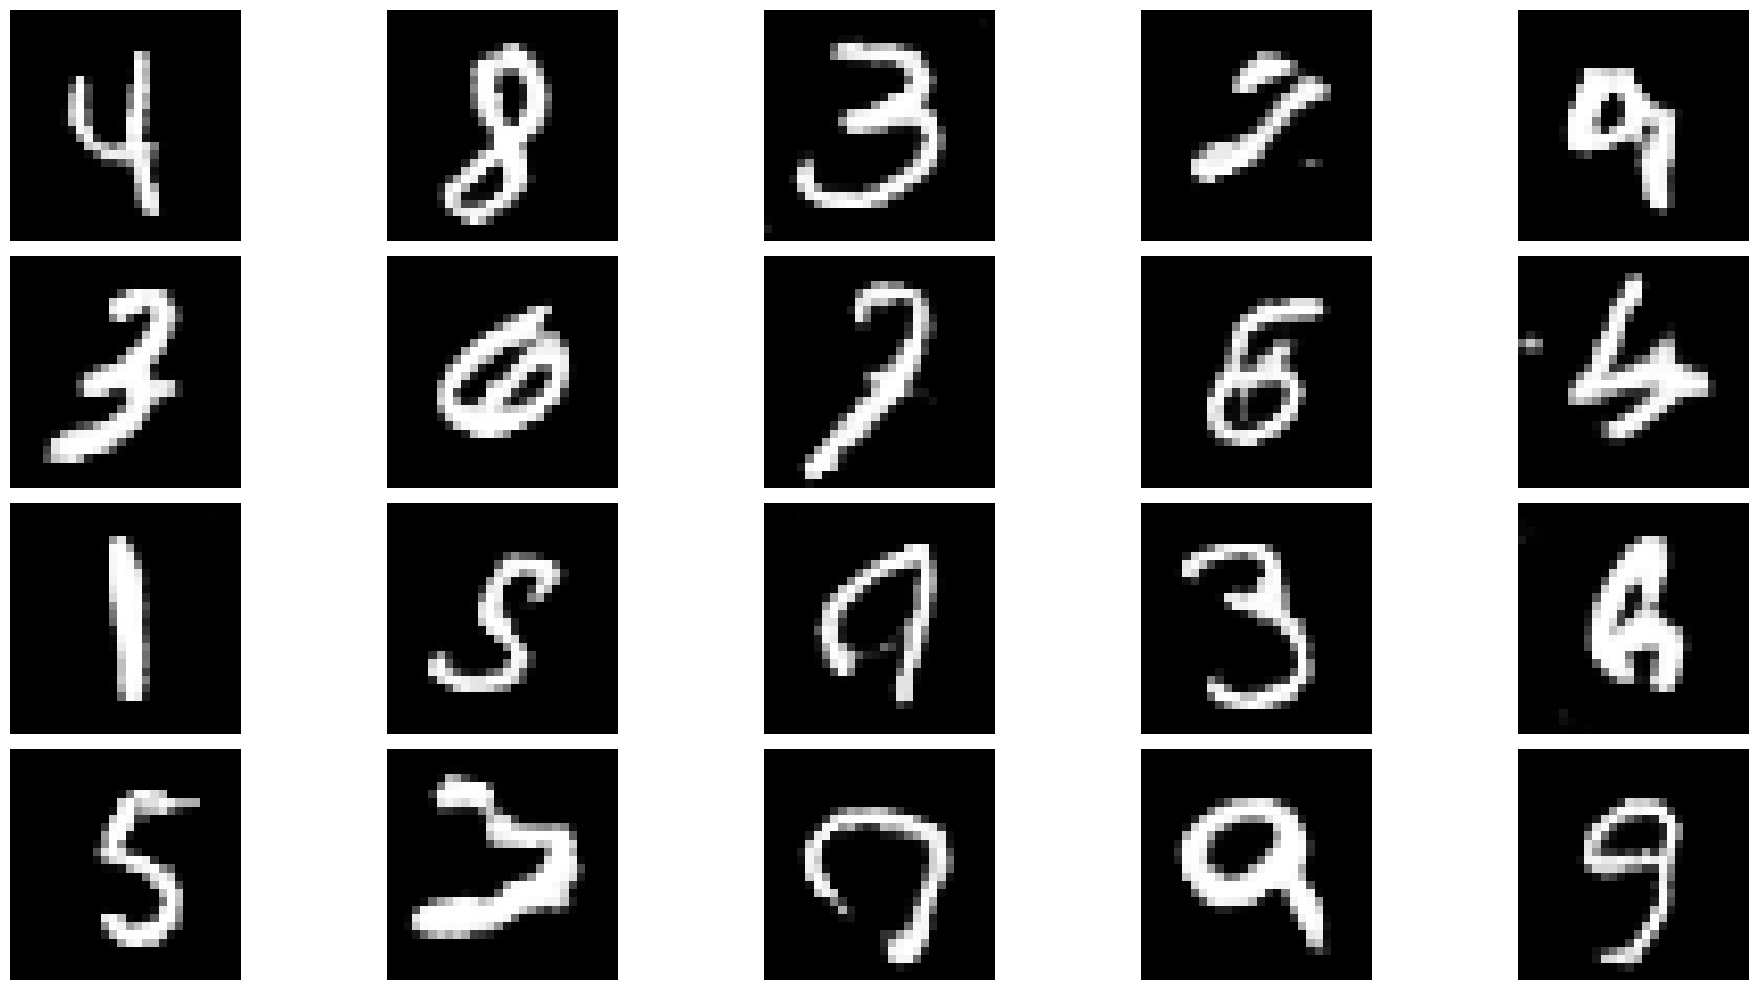

📈 Epoch 25 Summary:
   Train D Loss: 1.0068, Val D Loss: 1.1767
   Train G Loss: 1.1962, Val G Loss: 1.2674

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.903807	G_loss: 1.240536
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.006395	G_loss: 0.945904
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.937596	G_loss: 1.230443
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.029035	G_loss: 1.676217
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.872434	G_loss: 1.396286
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.970400	G_loss: 1.440720
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.977884	G_loss: 1.146201
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.059516	G_loss: 0.746875
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.891973	G_loss: 1.433385
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.938420	G_loss: 1.410228
====> Epoch: 26 Train D_loss: 1.0142, Train G_loss: 1.2050
====> Epoch: 26 Val D_loss: 1.1774, Val G_loss: 0.8107
📈 Epoch 26 Summary:
   Train D Loss: 1.0142, Val D Loss: 1.1774
   Train G Loss: 1.2050

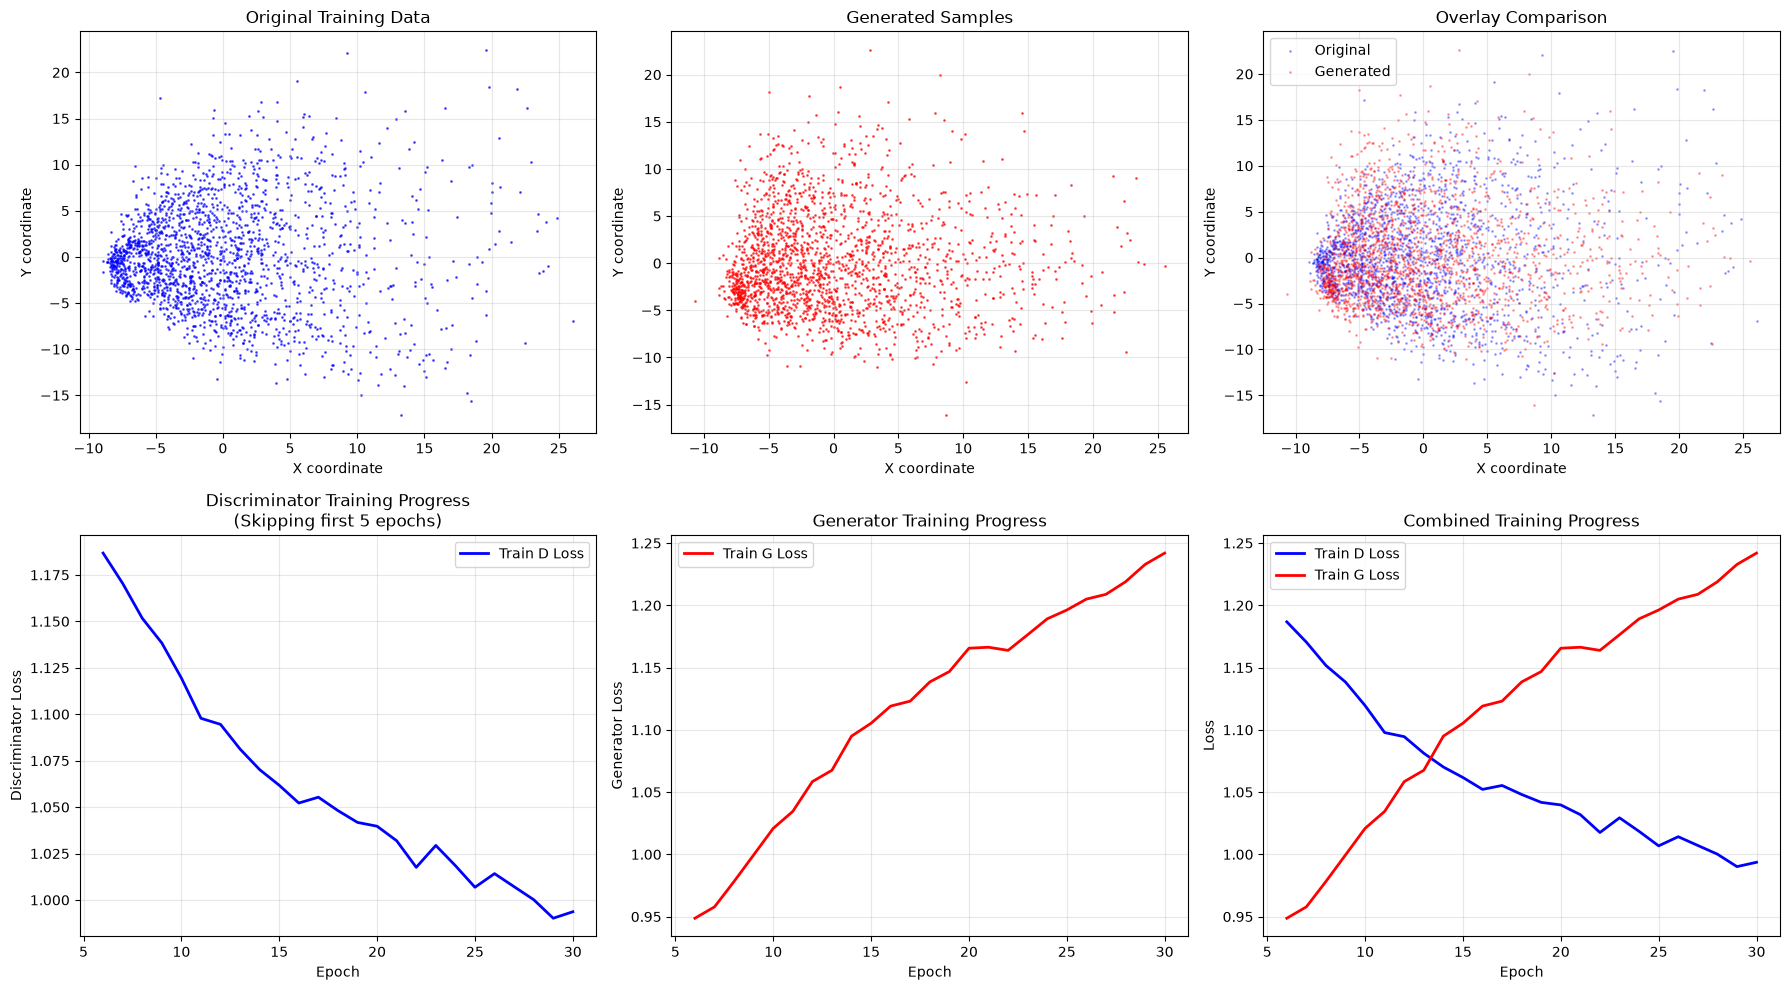

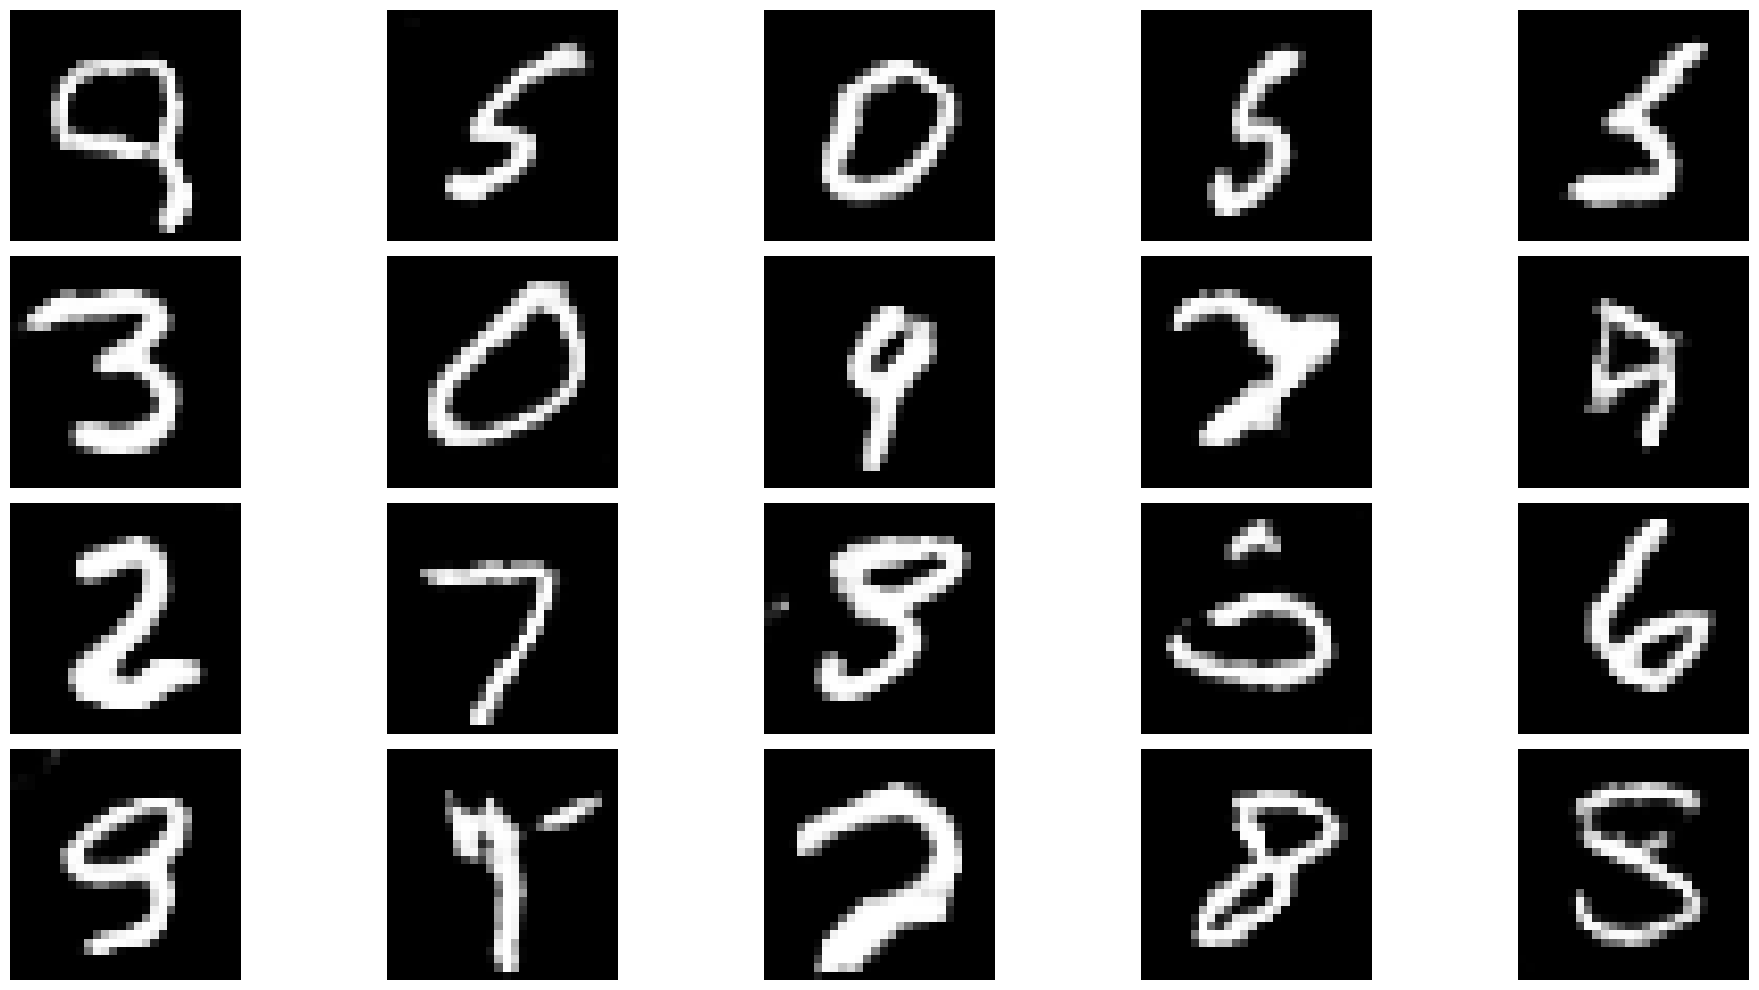

📈 Epoch 30 Summary:
   Train D Loss: 0.9937, Val D Loss: 1.1631
   Train G Loss: 1.2419, Val G Loss: 0.9339

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.859803	G_loss: 0.954576
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.063282	G_loss: 1.110516
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.911174	G_loss: 1.707162
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.972519	G_loss: 0.834189
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.904066	G_loss: 1.311414
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.955997	G_loss: 0.906359
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.056163	G_loss: 1.808508
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.910145	G_loss: 1.237252
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.191520	G_loss: 2.193591
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.910912	G_loss: 1.148357
====> Epoch: 31 Train D_loss: 0.9916, Train G_loss: 1.2496
====> Epoch: 31 Val D_loss: 1.3514, Val G_loss: 1.6874
📈 Epoch 31 Summary:
   Train D Loss: 0.9916, Val D Loss: 1.3514
   Train G Loss: 1.2496

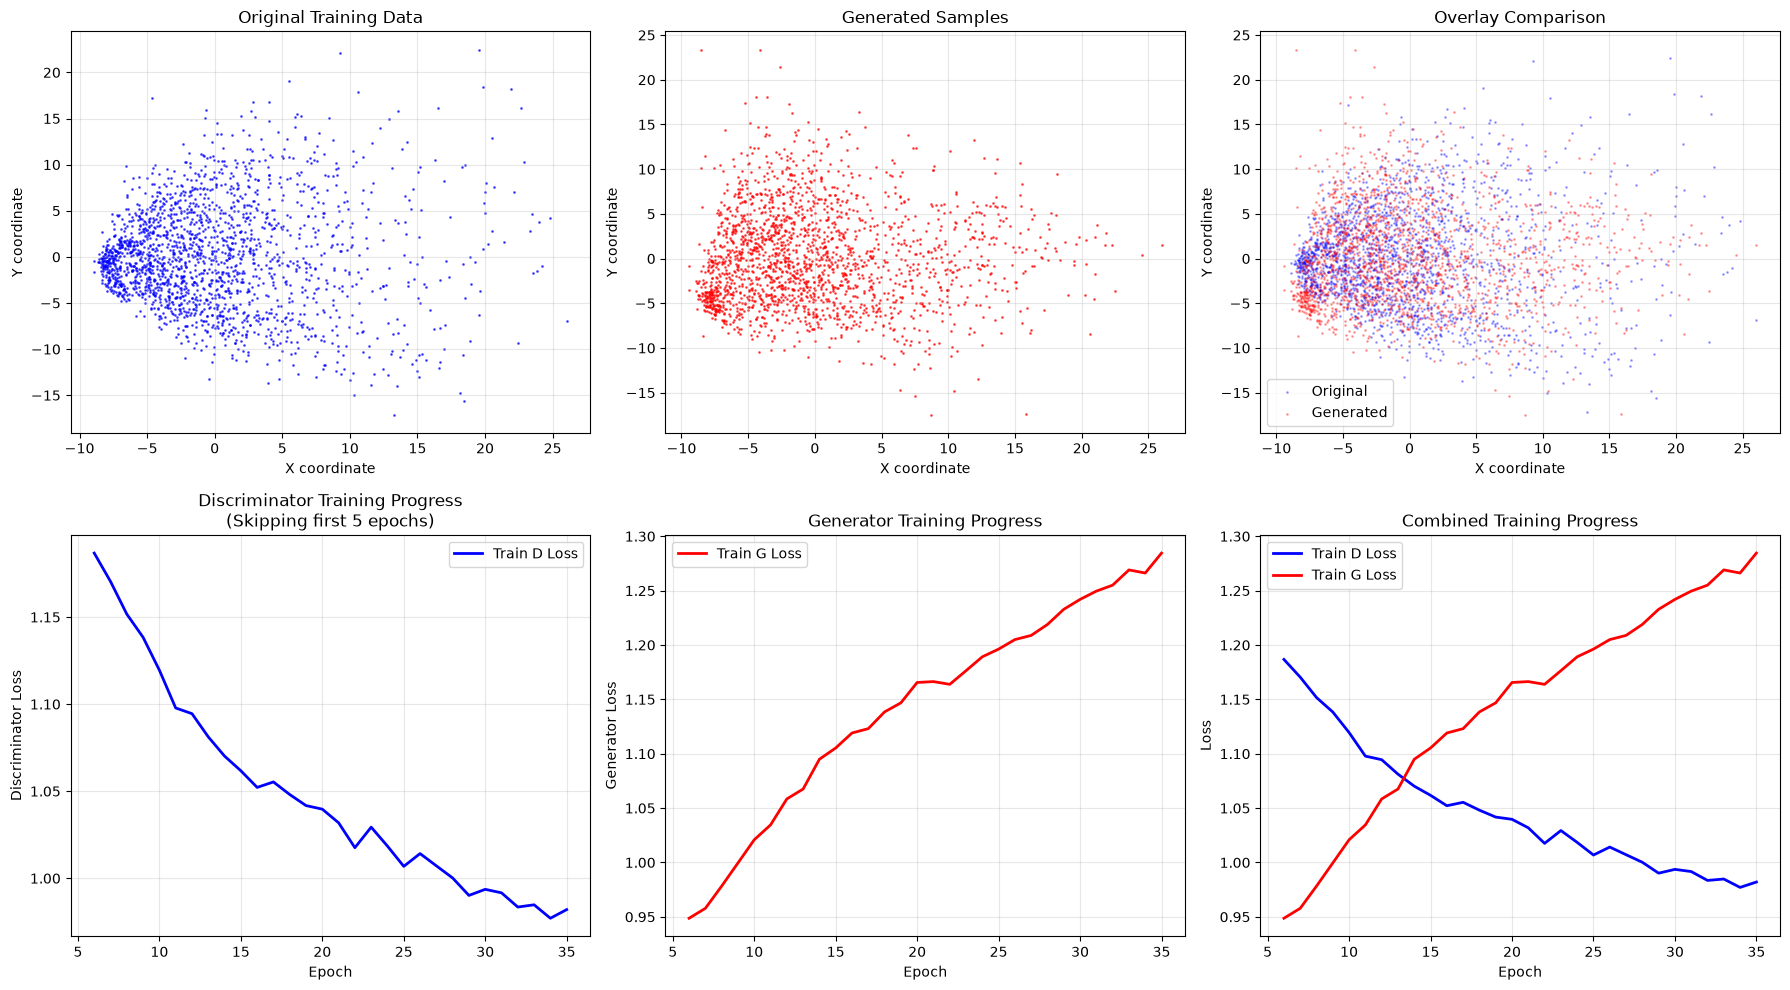

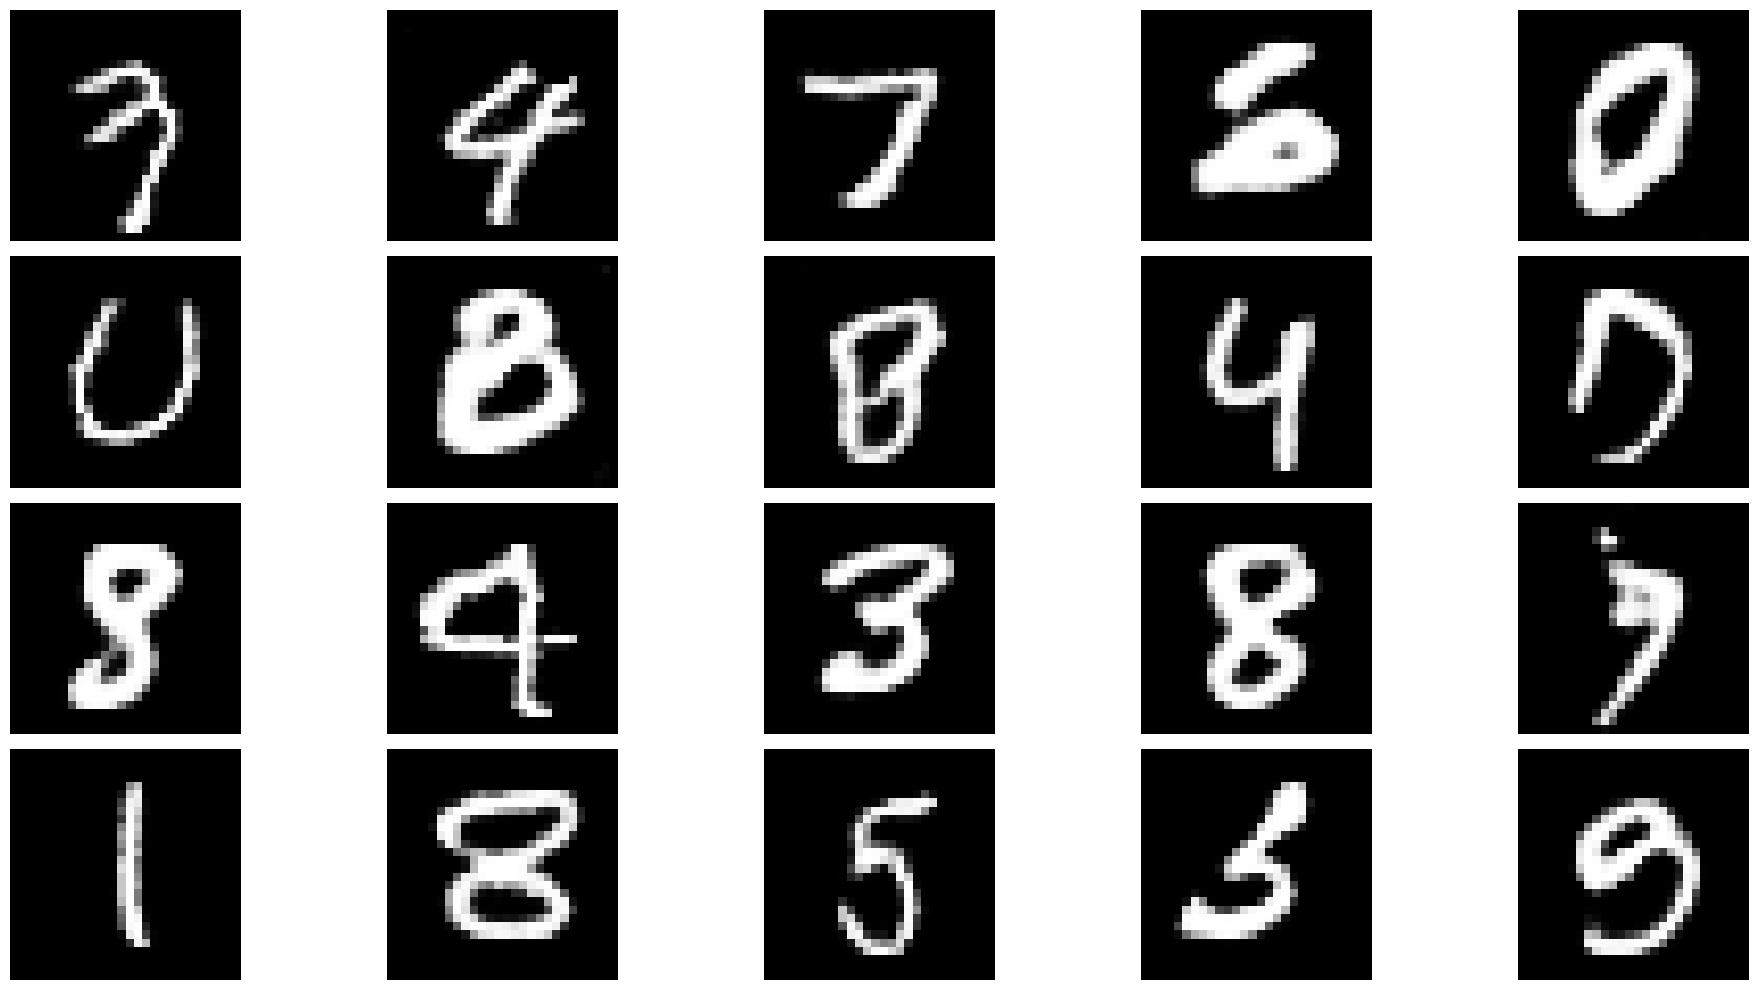

📈 Epoch 35 Summary:
   Train D Loss: 0.9820, Val D Loss: 1.1636
   Train G Loss: 1.2845, Val G Loss: 0.9619

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 1.012163	G_loss: 0.936168
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.932797	G_loss: 1.096763
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.002847	G_loss: 0.915330
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.896984	G_loss: 0.943221
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.860454	G_loss: 1.403336
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.780236	G_loss: 1.634119
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.948617	G_loss: 1.110563
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.964936	G_loss: 1.307828
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.979004	G_loss: 1.325185
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.842252	G_loss: 1.384287
====> Epoch: 36 Train D_loss: 0.9685, Train G_loss: 1.2774
====> Epoch: 36 Val D_loss: 1.4292, Val G_loss: 0.4652
📈 Epoch 36 Summary:
   Train D Loss: 0.9685, Val D Loss: 1.4292
   Train G Loss: 1.2774

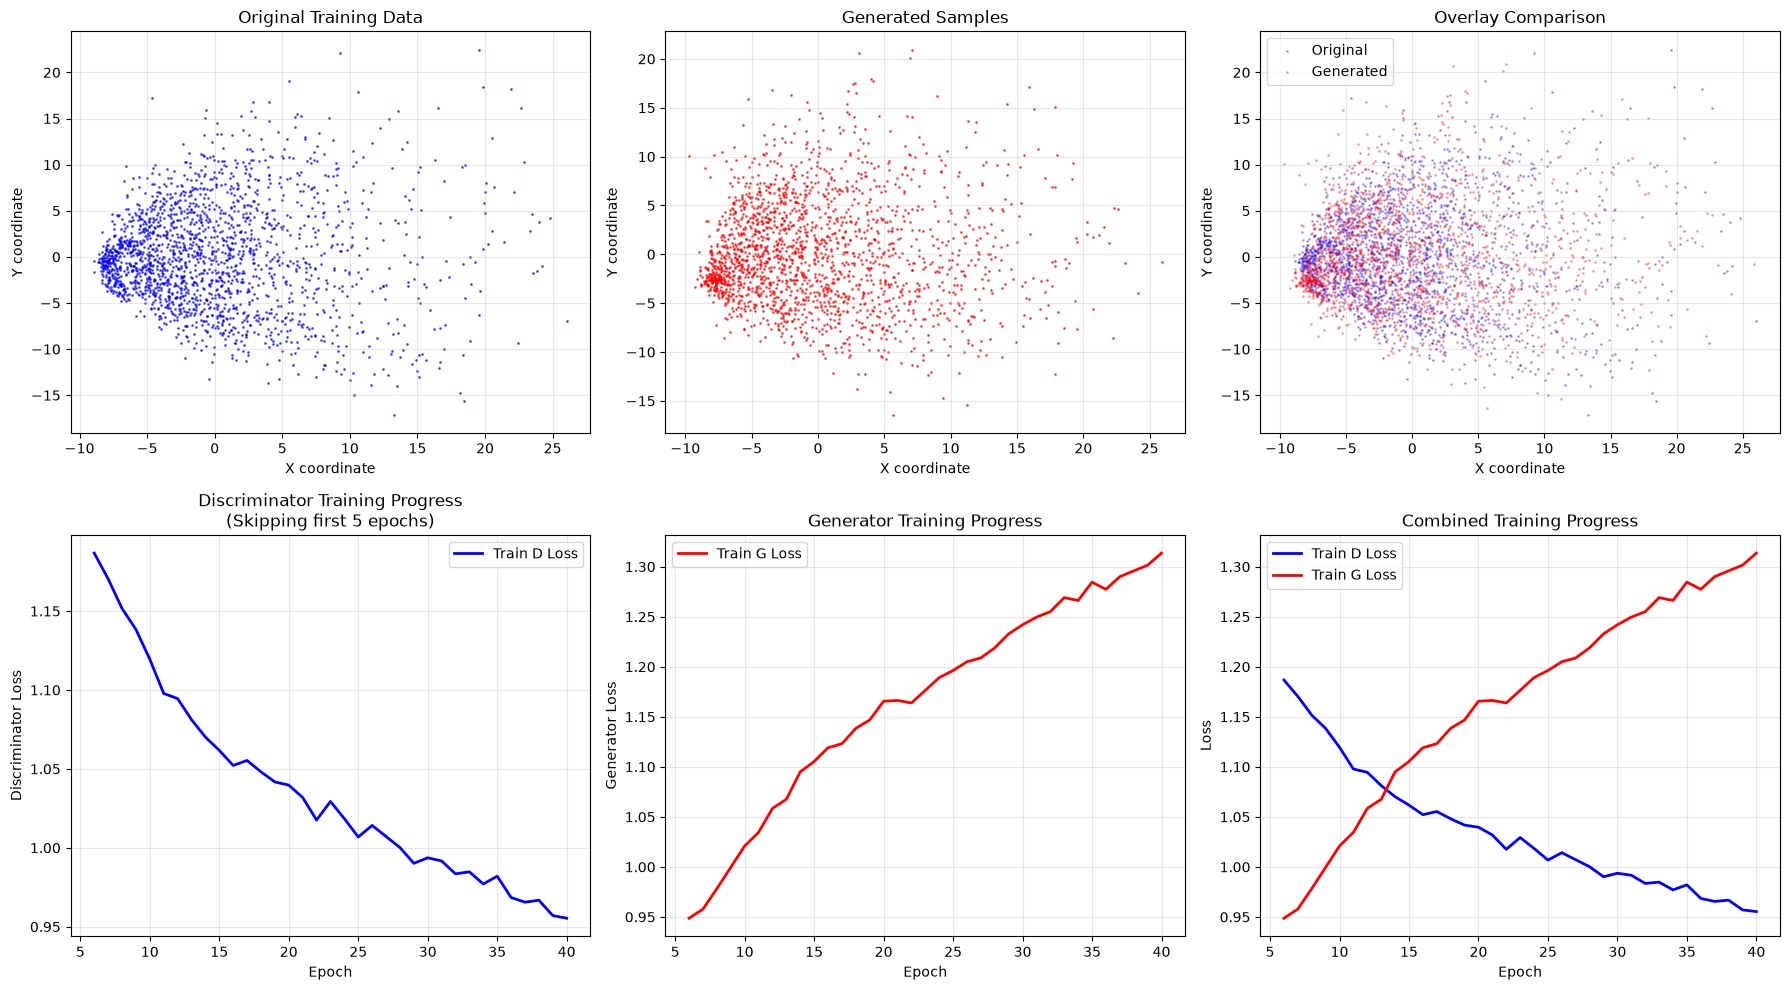

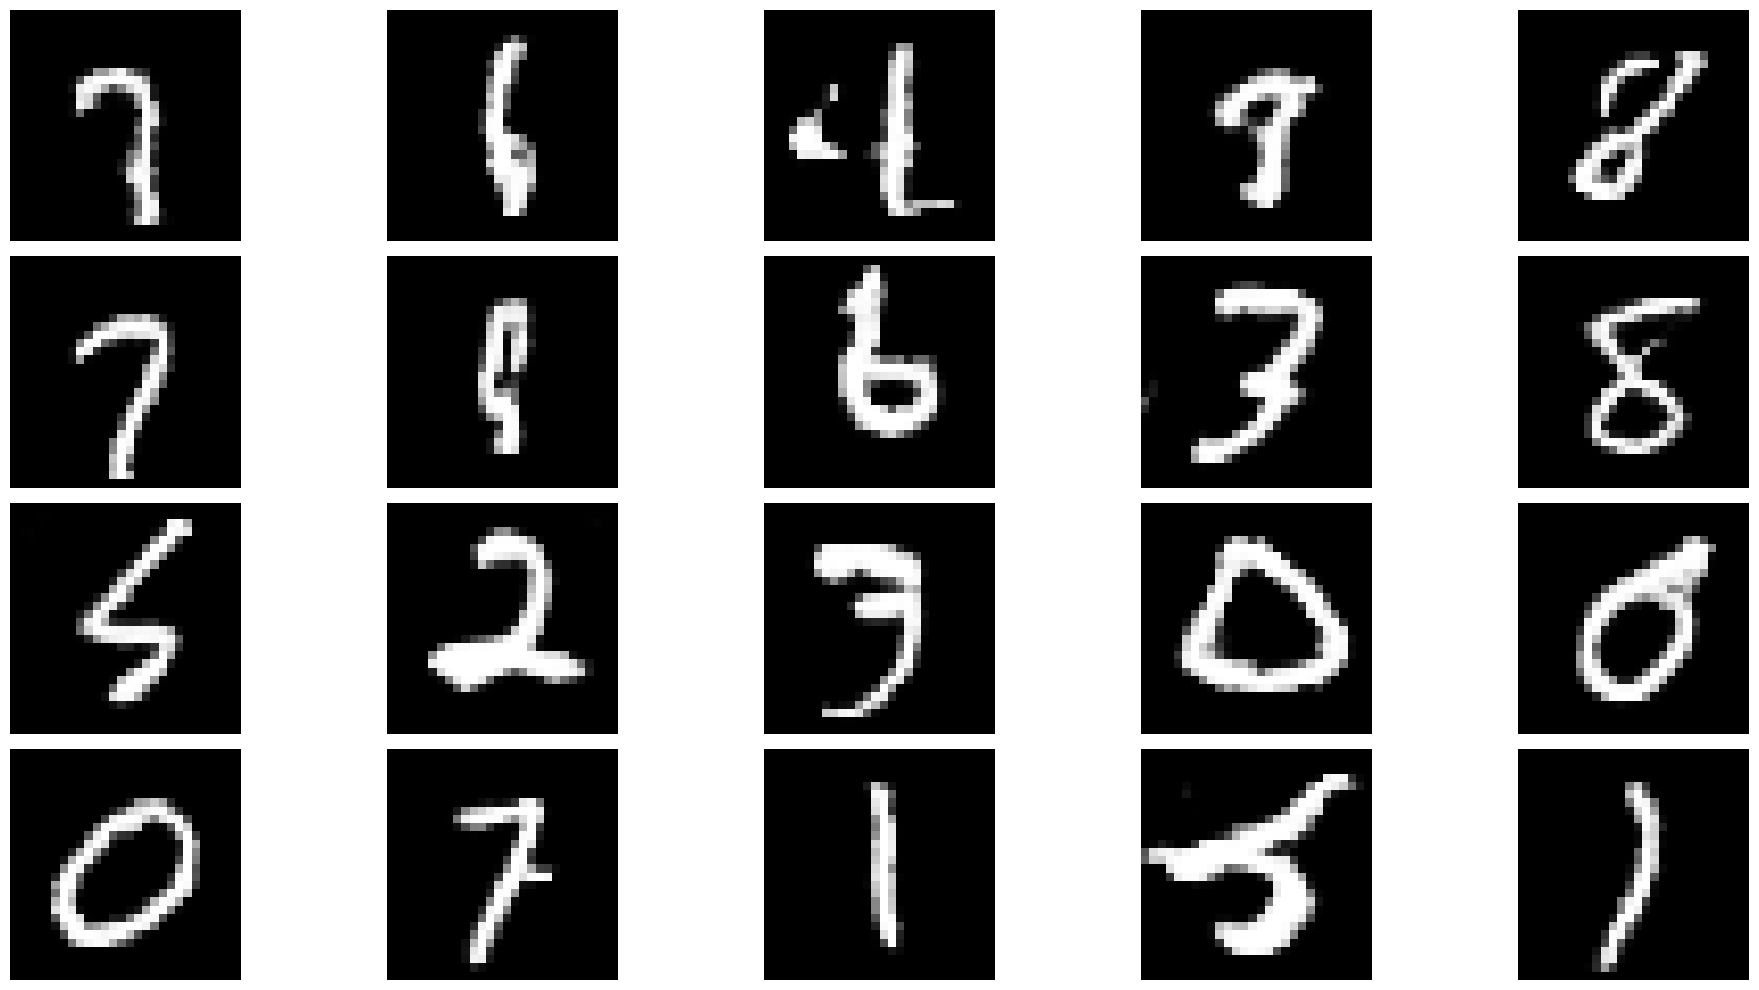

📈 Epoch 40 Summary:
   Train D Loss: 0.9554, Val D Loss: 1.2652
   Train G Loss: 1.3136, Val G Loss: 0.6382

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.998382	G_loss: 1.963359
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.863282	G_loss: 1.360456
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.987802	G_loss: 1.168789
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.987931	G_loss: 0.787286
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.984671	G_loss: 0.997236
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.822889	G_loss: 1.135889
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.977840	G_loss: 0.958548
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.842984	G_loss: 1.439162
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.897543	G_loss: 1.439770
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.887906	G_loss: 1.056293
====> Epoch: 41 Train D_loss: 0.9601, Train G_loss: 1.3208
====> Epoch: 41 Val D_loss: 1.1971, Val G_loss: 1.3443
📈 Epoch 41 Summary:
   Train D Loss: 0.9601, Val D Loss: 1.1971
   Train G Loss: 1.3208

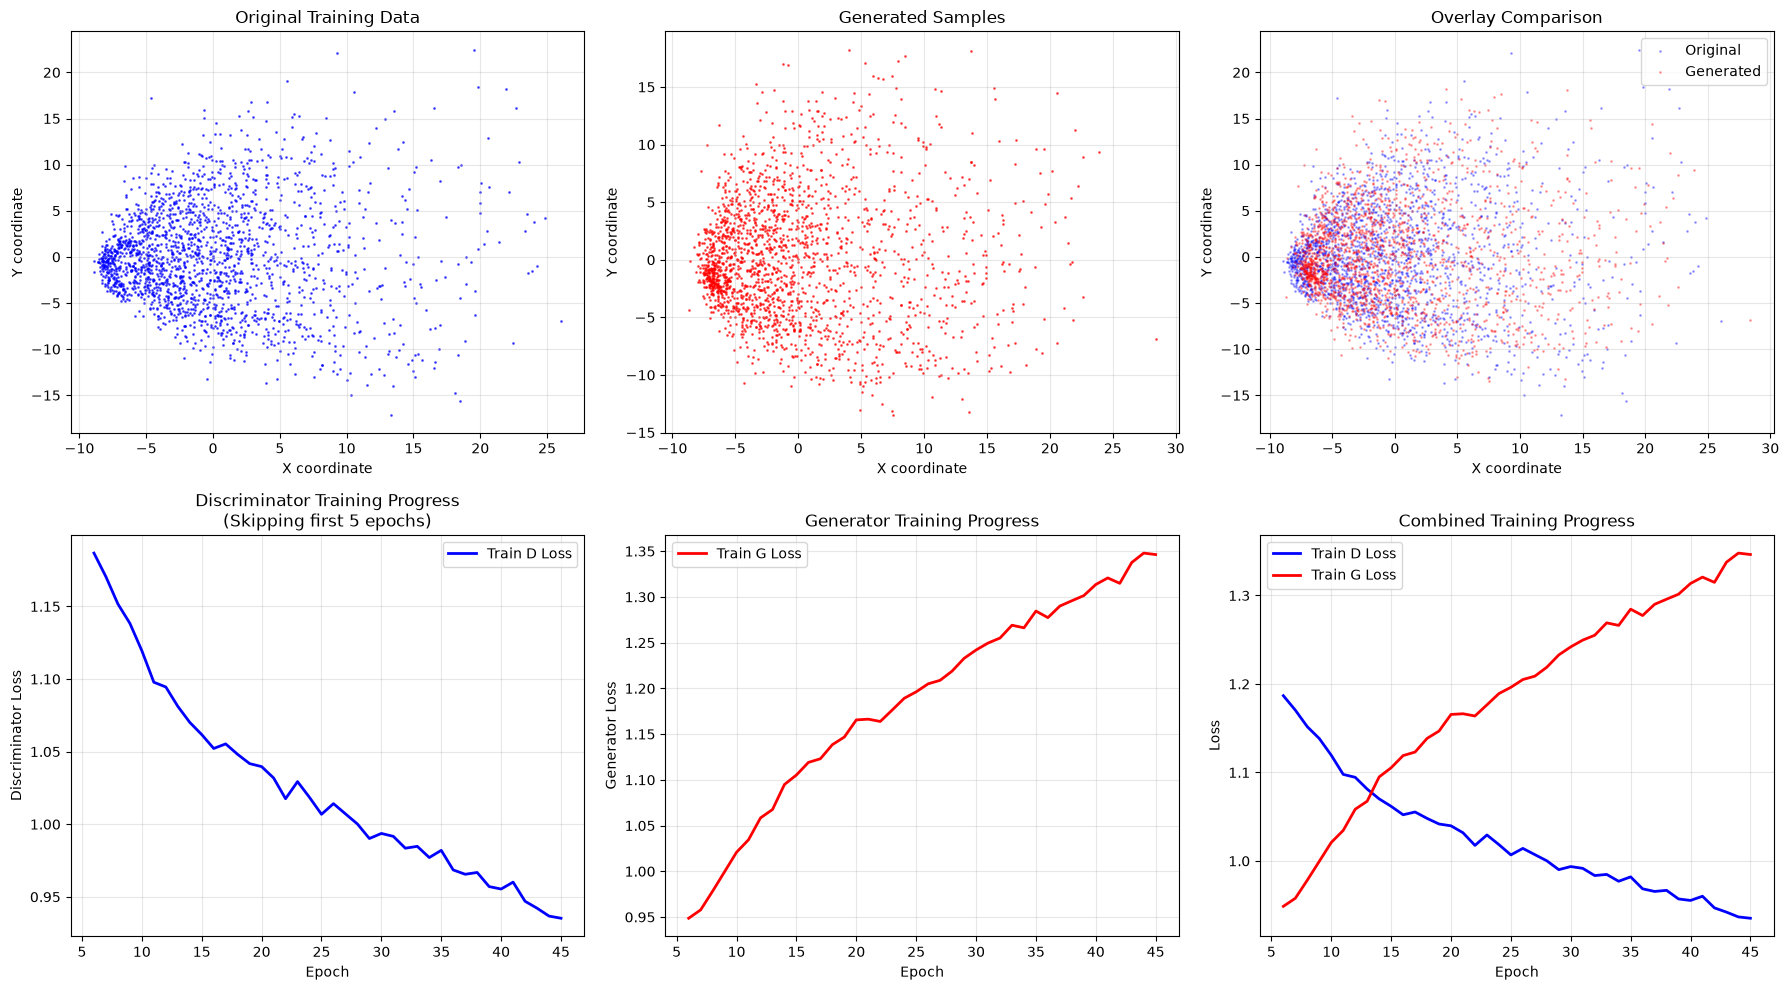

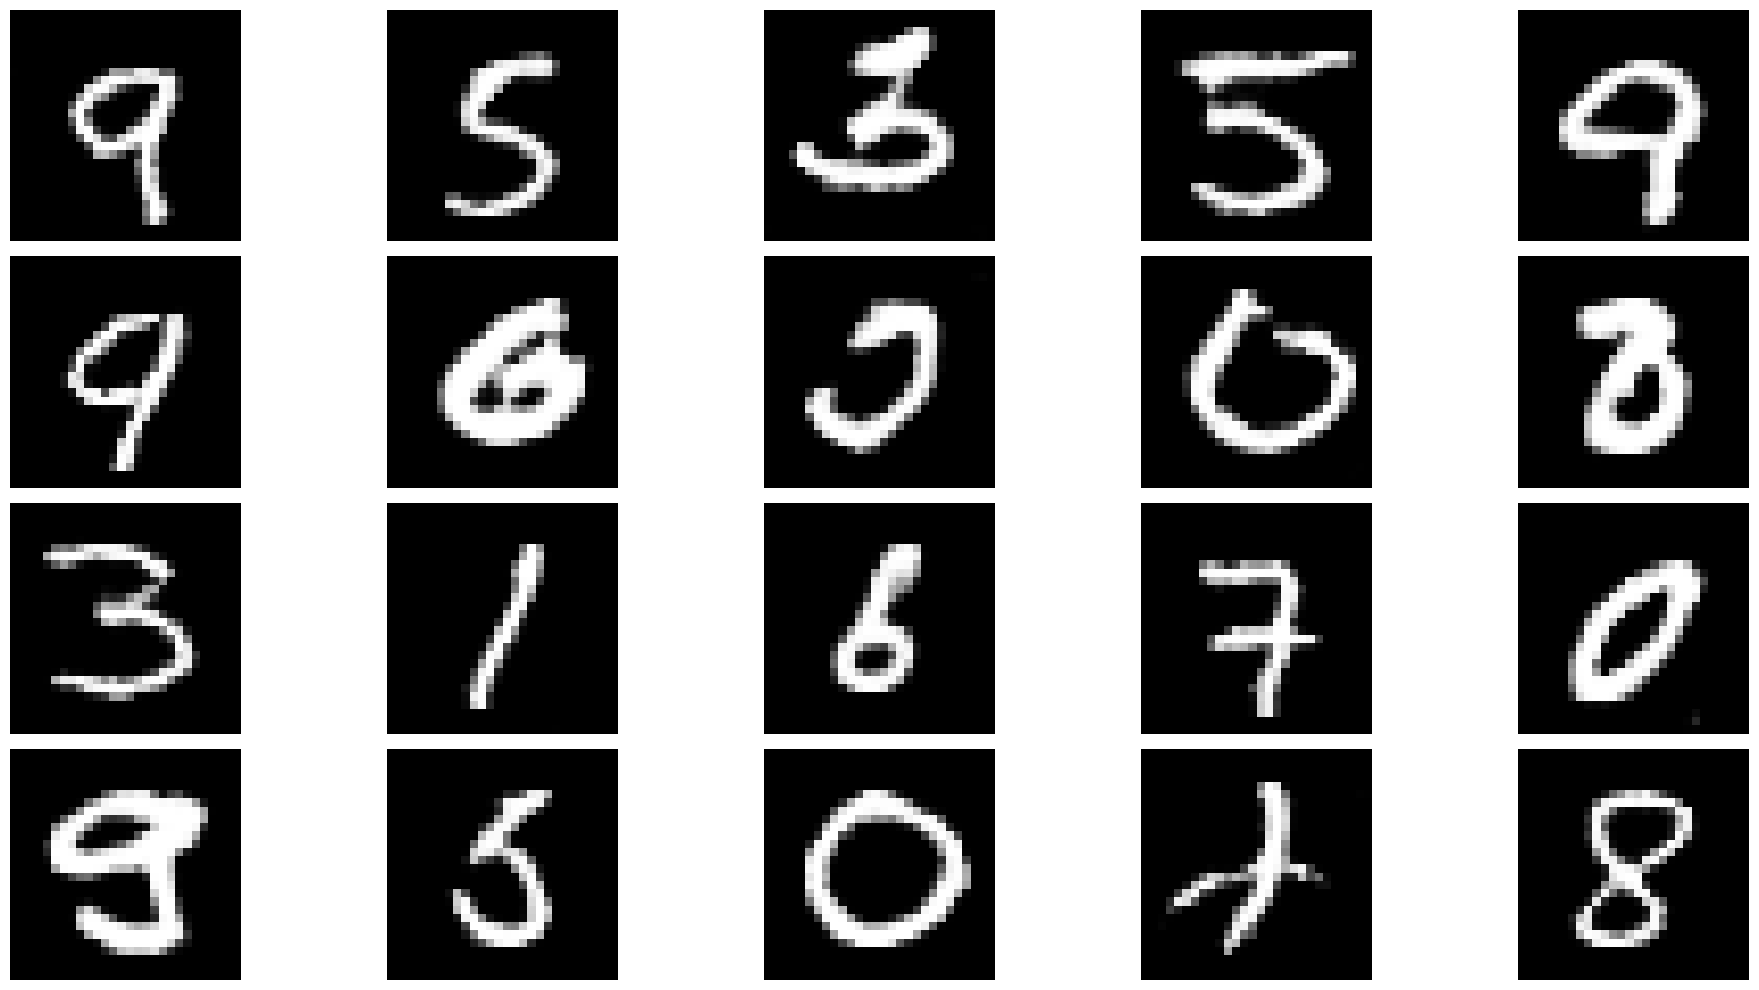

📈 Epoch 45 Summary:
   Train D Loss: 0.9353, Val D Loss: 1.1664
   Train G Loss: 1.3463, Val G Loss: 0.8378

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.029673	G_loss: 1.298068
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.941915	G_loss: 2.221979
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.895053	G_loss: 1.004100
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.997201	G_loss: 1.916323
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.858963	G_loss: 1.089510
Epoch: 46 [32000/60000 (53%)]	D_loss: 1.082598	G_loss: 0.918131
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.229196	G_loss: 1.980784
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.986047	G_loss: 1.228012
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.964424	G_loss: 2.026486
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.060361	G_loss: 2.172613
====> Epoch: 46 Train D_loss: 0.9344, Train G_loss: 1.3639
====> Epoch: 46 Val D_loss: 1.3686, Val G_loss: 1.7910
📈 Epoch 46 Summary:
   Train D Loss: 0.9344, Val D Loss: 1.3686
   Train G Loss: 1.3639

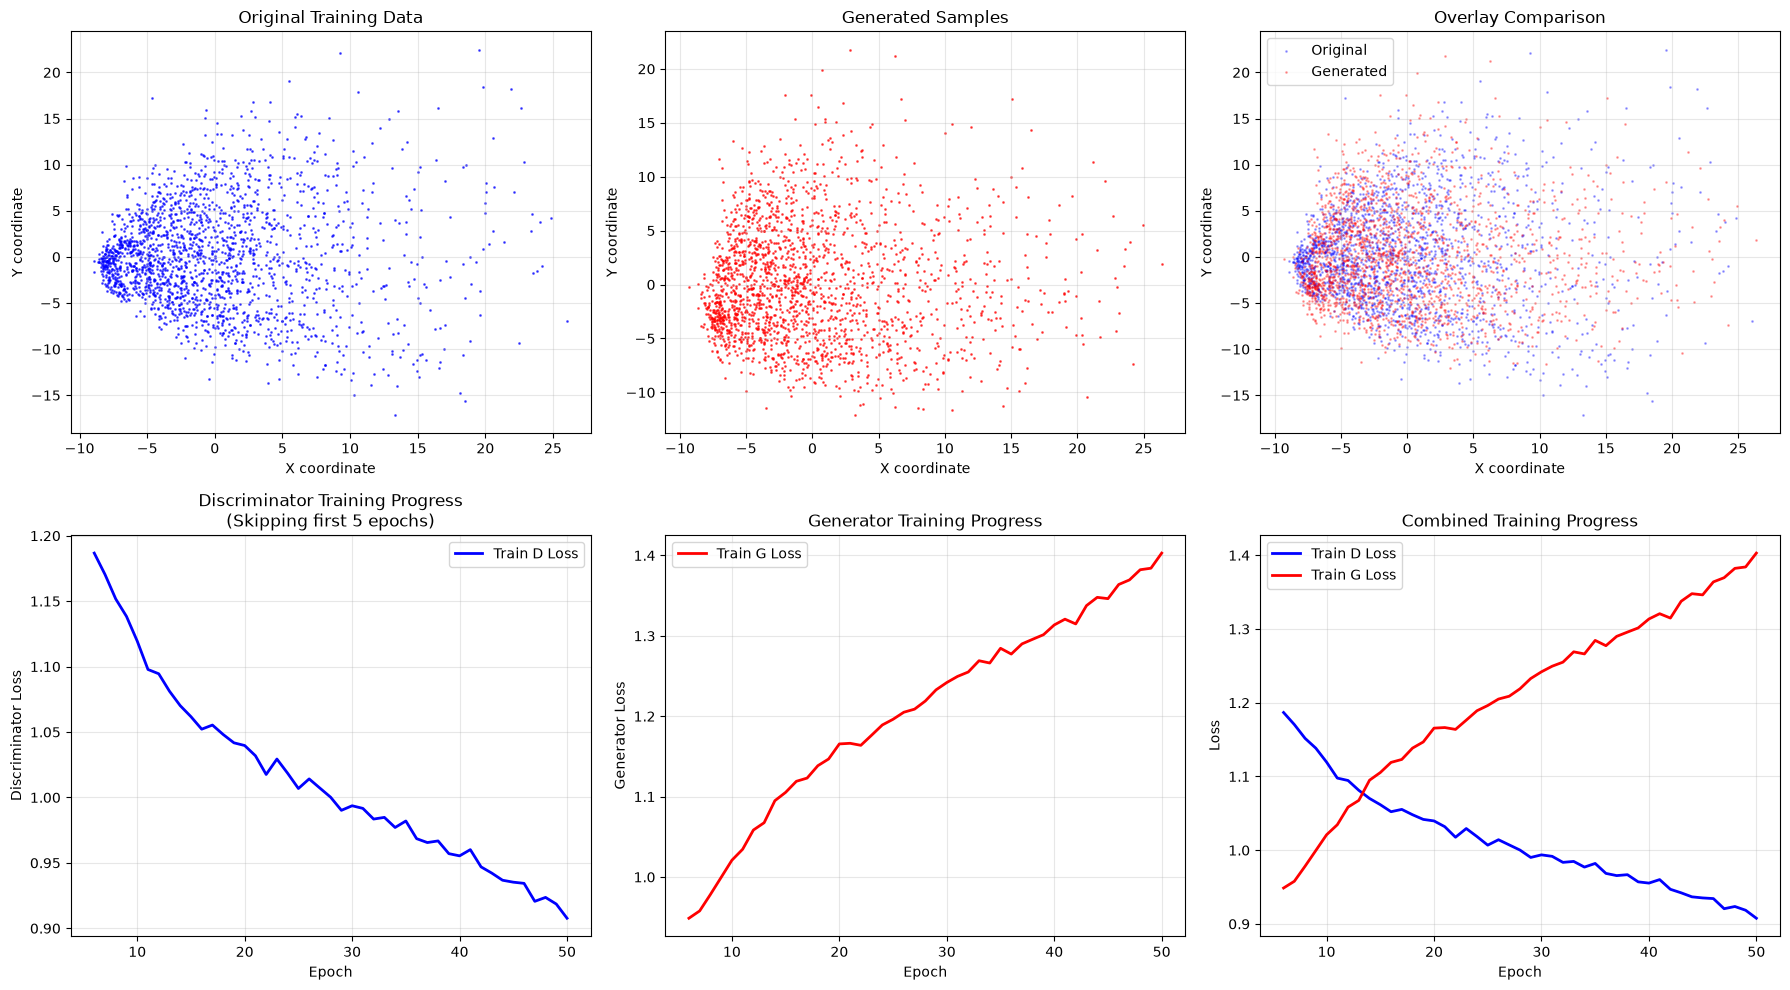

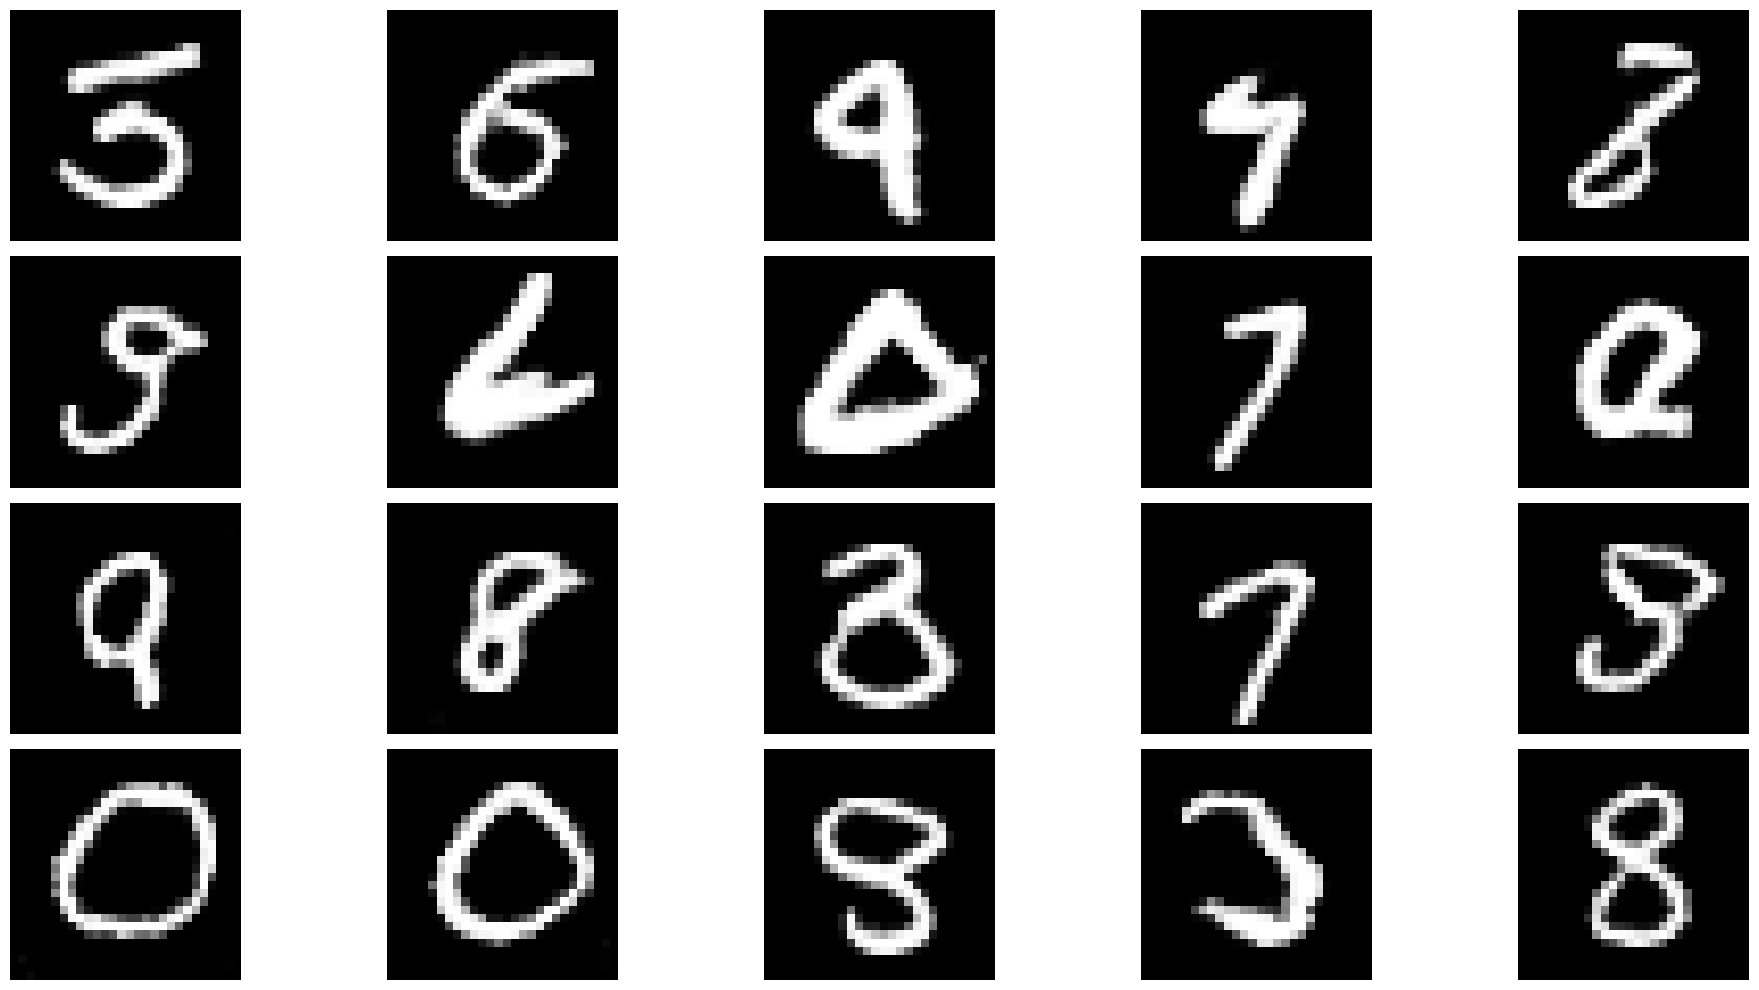

📈 Epoch 50 Summary:
   Train D Loss: 0.9077, Val D Loss: 1.2158
   Train G Loss: 1.4030, Val G Loss: 0.7380

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.859163	G_loss: 1.460557
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.837006	G_loss: 1.223043
Epoch: 51 [12800/60000 (21%)]	D_loss: 1.037681	G_loss: 2.019007
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.909960	G_loss: 1.480349
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.873433	G_loss: 0.989319
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.827005	G_loss: 1.565129
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.007064	G_loss: 1.064442
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.199643	G_loss: 0.416675
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.824904	G_loss: 1.315347
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.731385	G_loss: 1.161194
====> Epoch: 51 Train D_loss: 0.9062, Train G_loss: 1.4069
====> Epoch: 51 Val D_loss: 1.1377, Val G_loss: 1.0639
📈 Epoch 51 Summary:
   Train D Loss: 0.9062, Val D Loss: 1.1377
   Train G Loss: 1.4069

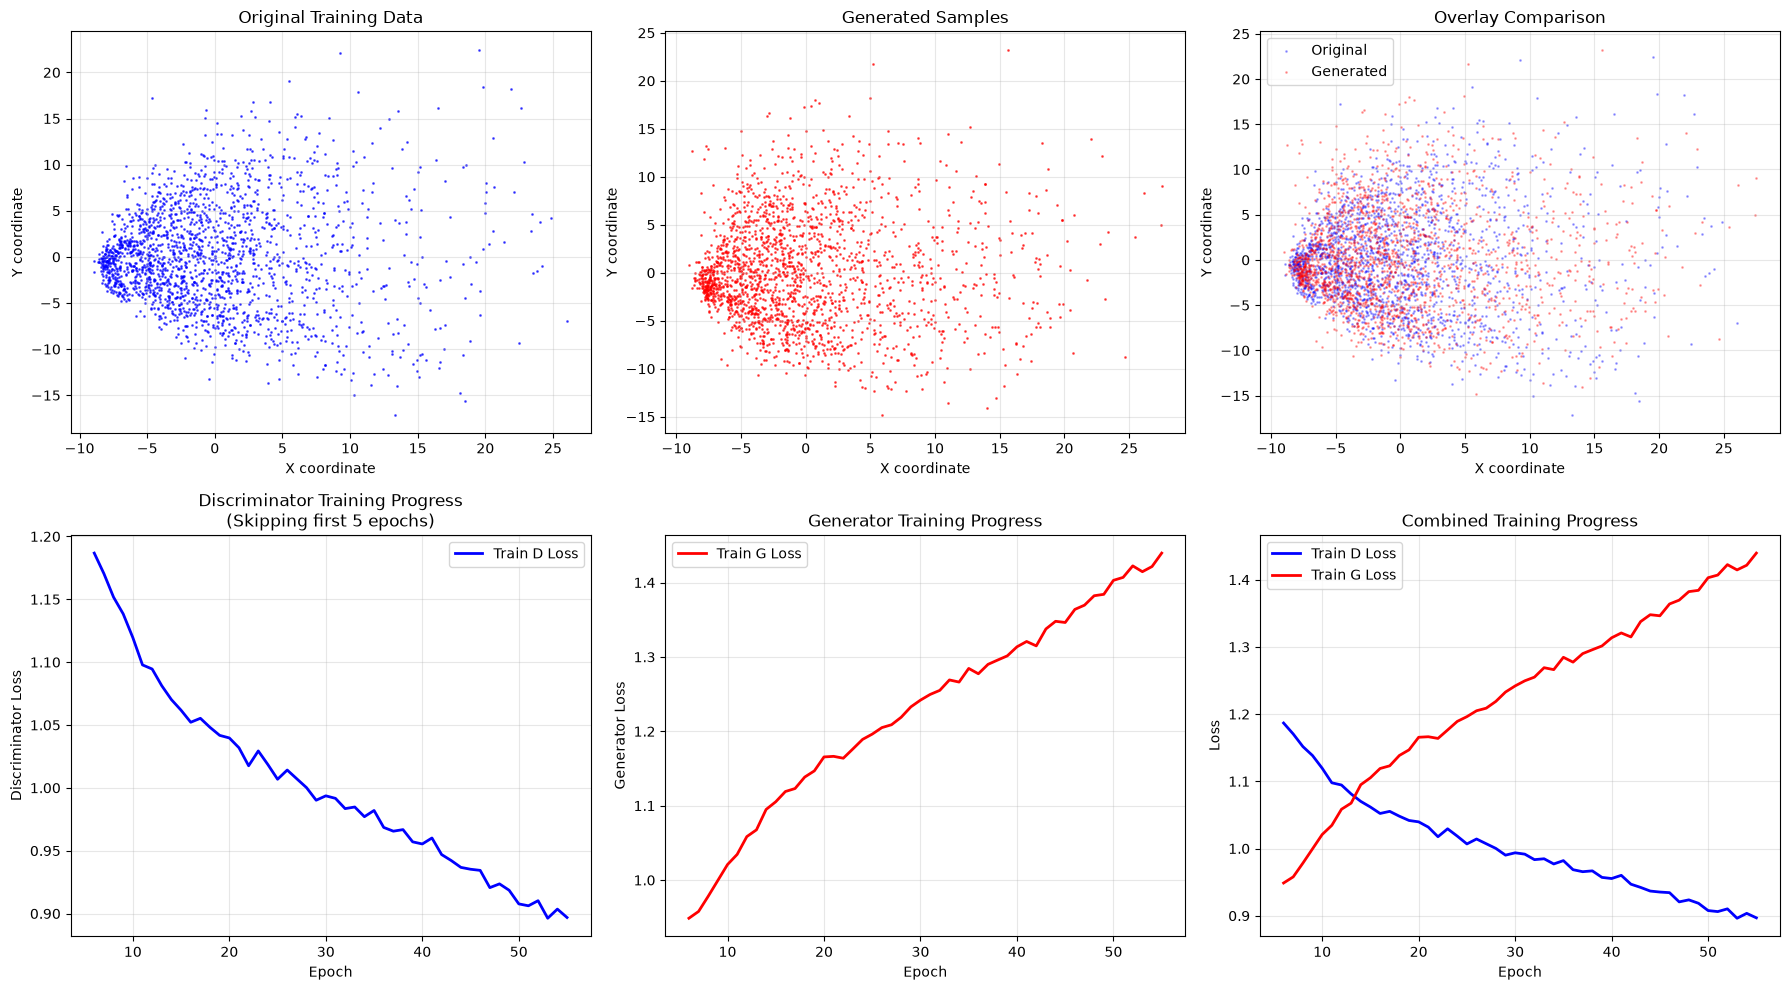

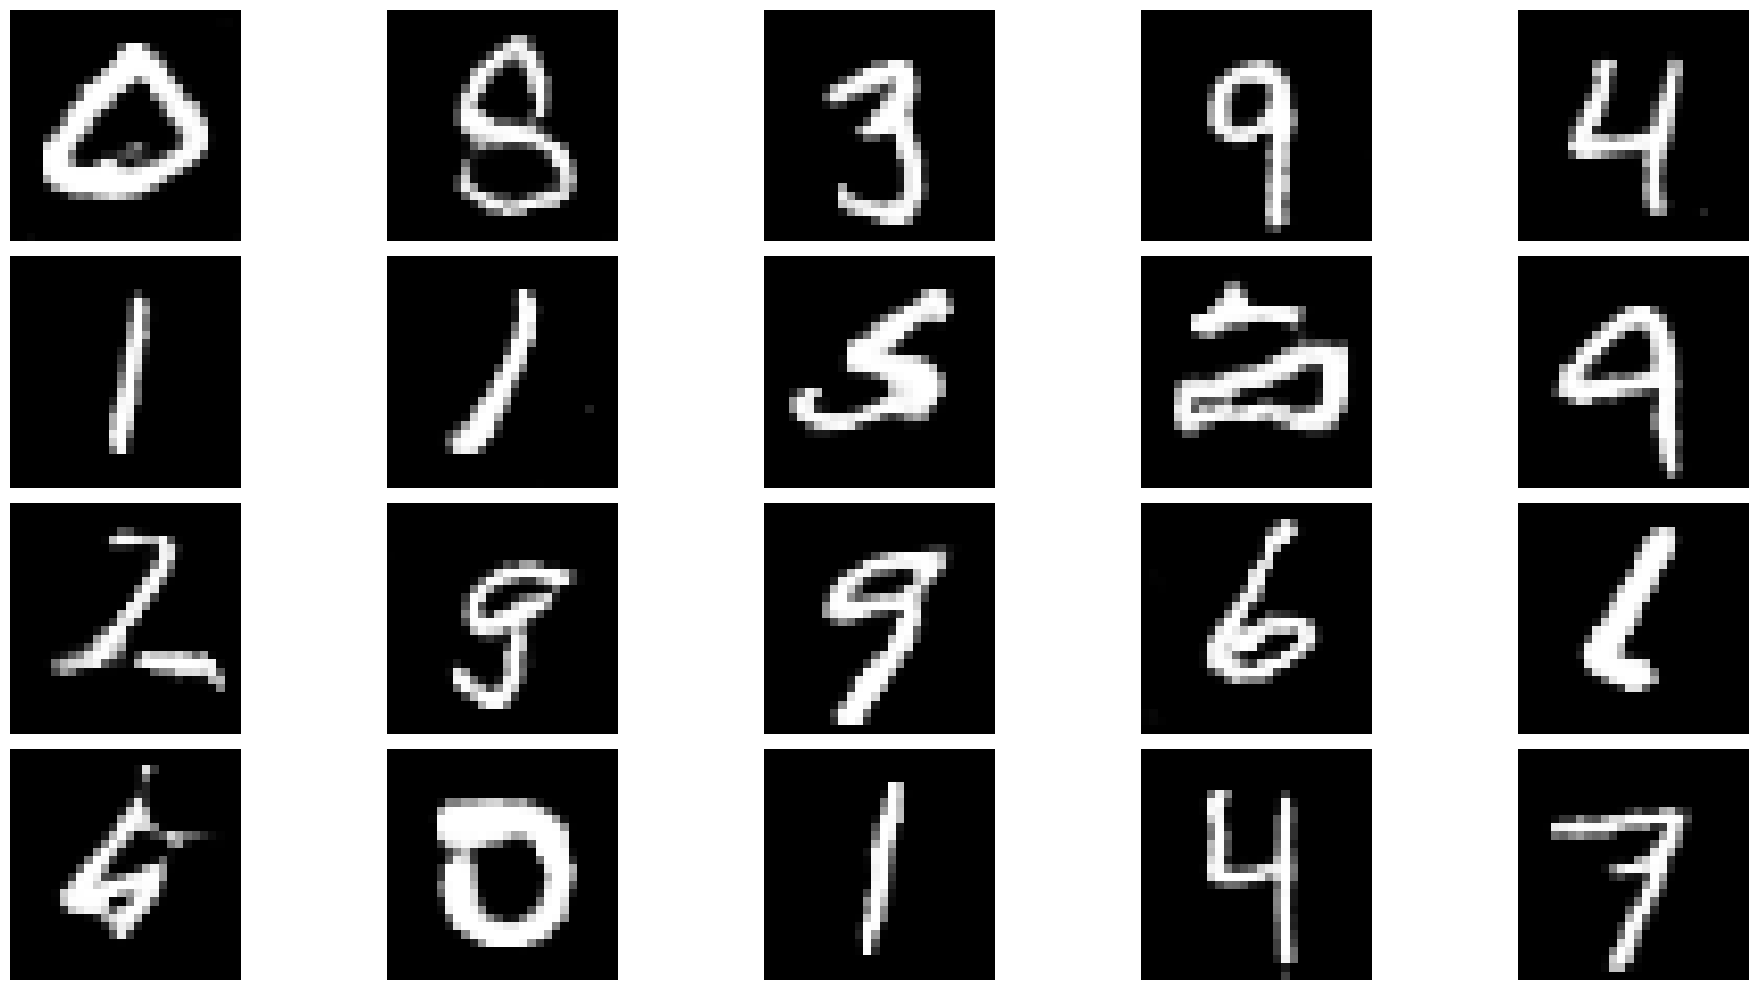

📈 Epoch 55 Summary:
   Train D Loss: 0.8969, Val D Loss: 1.1424
   Train G Loss: 1.4396, Val G Loss: 0.9242

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.748350	G_loss: 1.200066
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.783197	G_loss: 1.283610
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.865822	G_loss: 2.176393
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.863497	G_loss: 2.248908
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.862691	G_loss: 1.079687
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.858797	G_loss: 1.221517
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.728308	G_loss: 1.341913
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.810553	G_loss: 1.142806
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.999839	G_loss: 1.078726
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.907416	G_loss: 1.700875
====> Epoch: 56 Train D_loss: 0.8918, Train G_loss: 1.4384
====> Epoch: 56 Val D_loss: 1.4482, Val G_loss: 2.0412
📈 Epoch 56 Summary:
   Train D Loss: 0.8918, Val D Loss: 1.4482
   Train G Loss: 1.4384

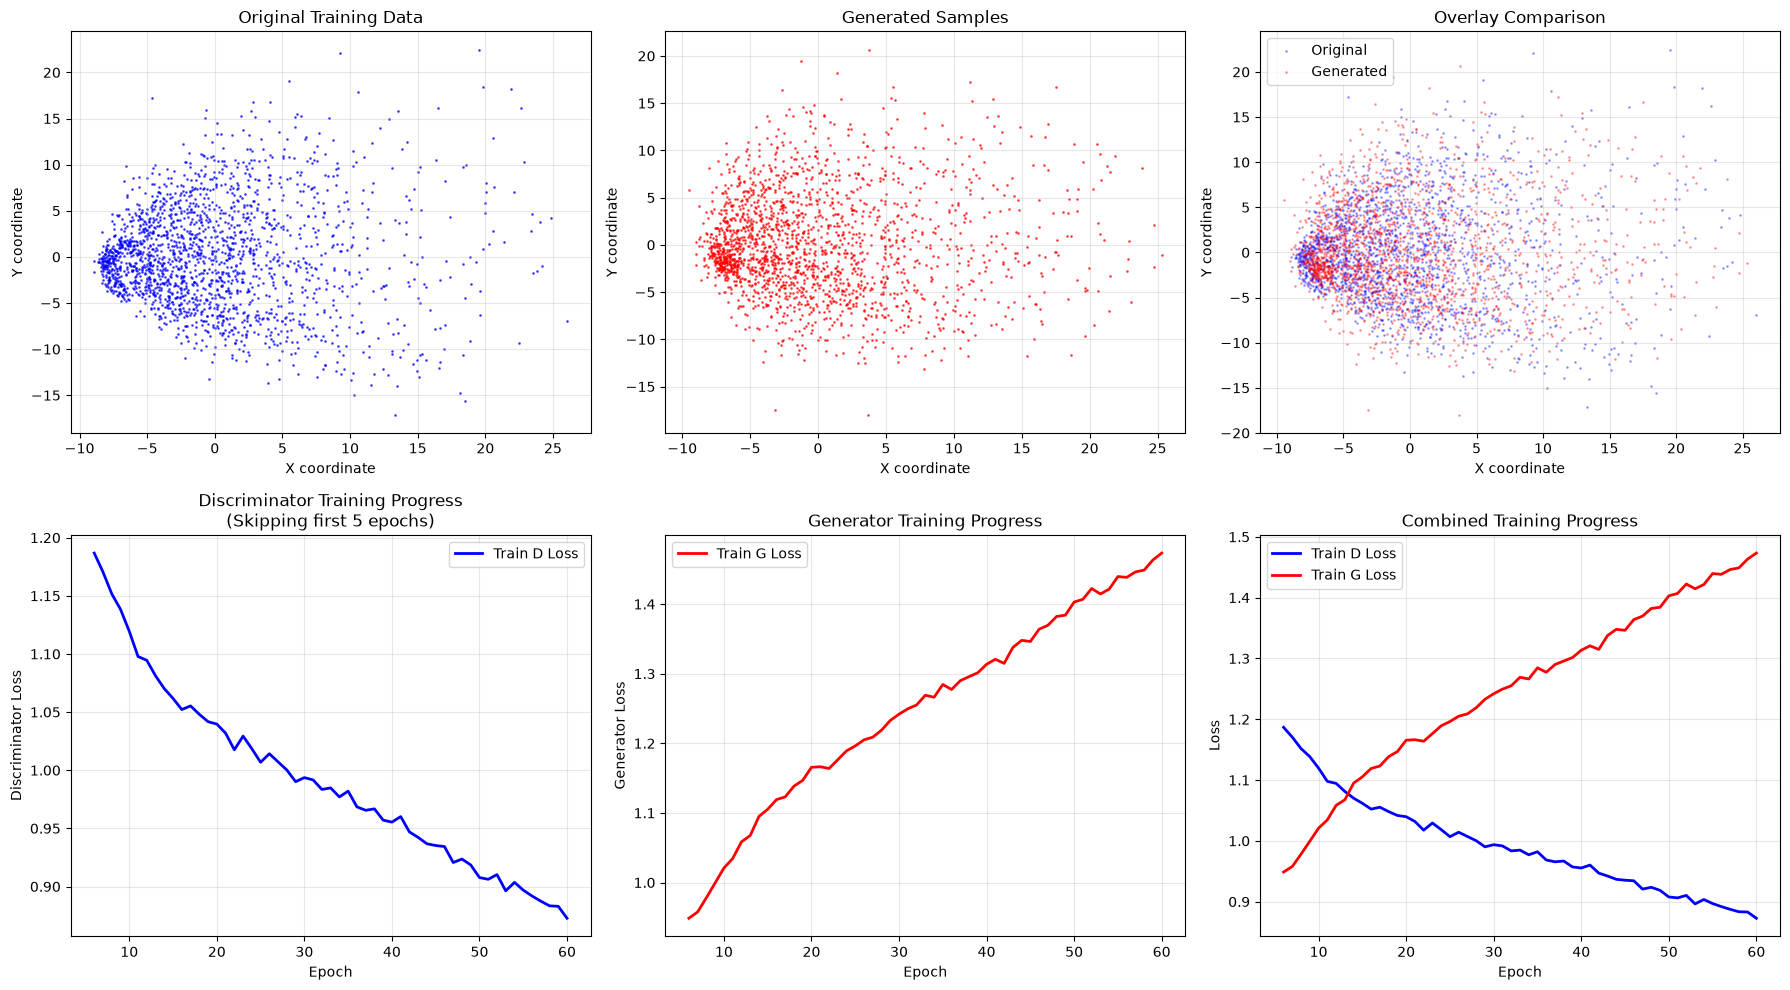

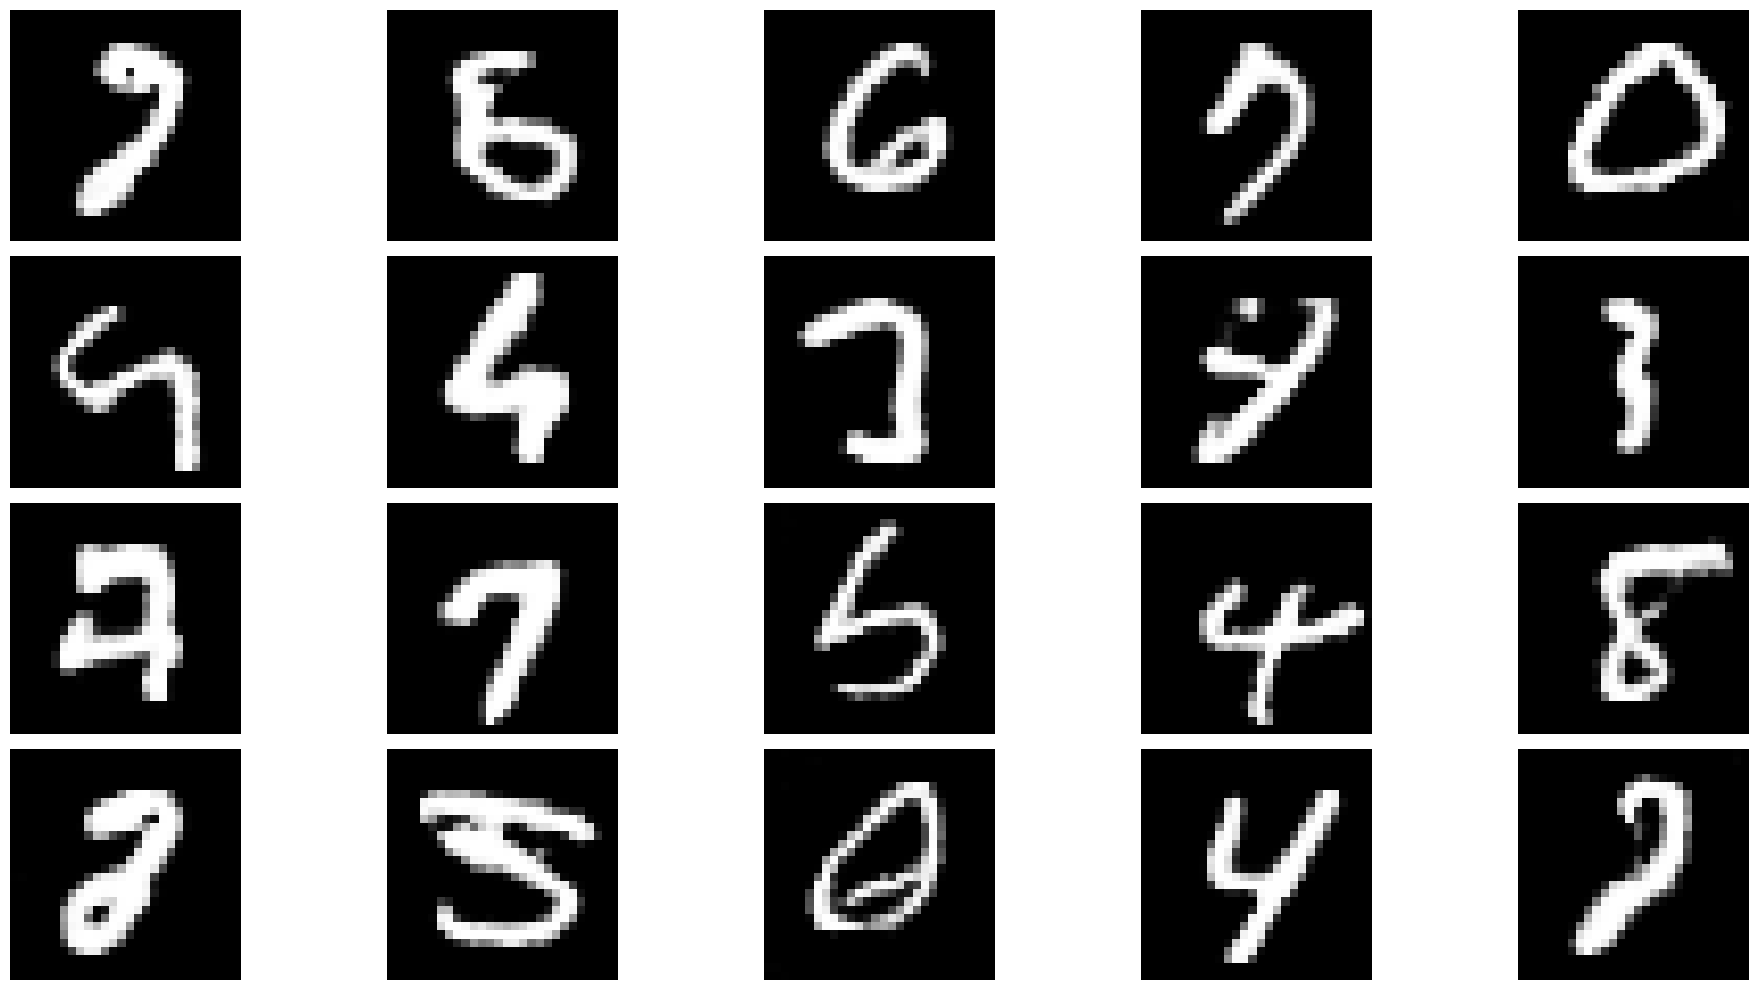

📈 Epoch 60 Summary:
   Train D Loss: 0.8727, Val D Loss: 1.1703
   Train G Loss: 1.4733, Val G Loss: 1.4330

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.882844	G_loss: 1.006126
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.908136	G_loss: 0.936432
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.794350	G_loss: 1.278724
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.855505	G_loss: 1.139007
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.861095	G_loss: 1.411794
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.827305	G_loss: 1.108652
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.814644	G_loss: 1.528704
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.920481	G_loss: 0.966418
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.919216	G_loss: 1.694172
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.739104	G_loss: 1.677086
====> Epoch: 61 Train D_loss: 0.8759, Train G_loss: 1.4765
====> Epoch: 61 Val D_loss: 1.1650, Val G_loss: 1.4389
📈 Epoch 61 Summary:
   Train D Loss: 0.8759, Val D Loss: 1.1650
   Train G Loss: 1.4765

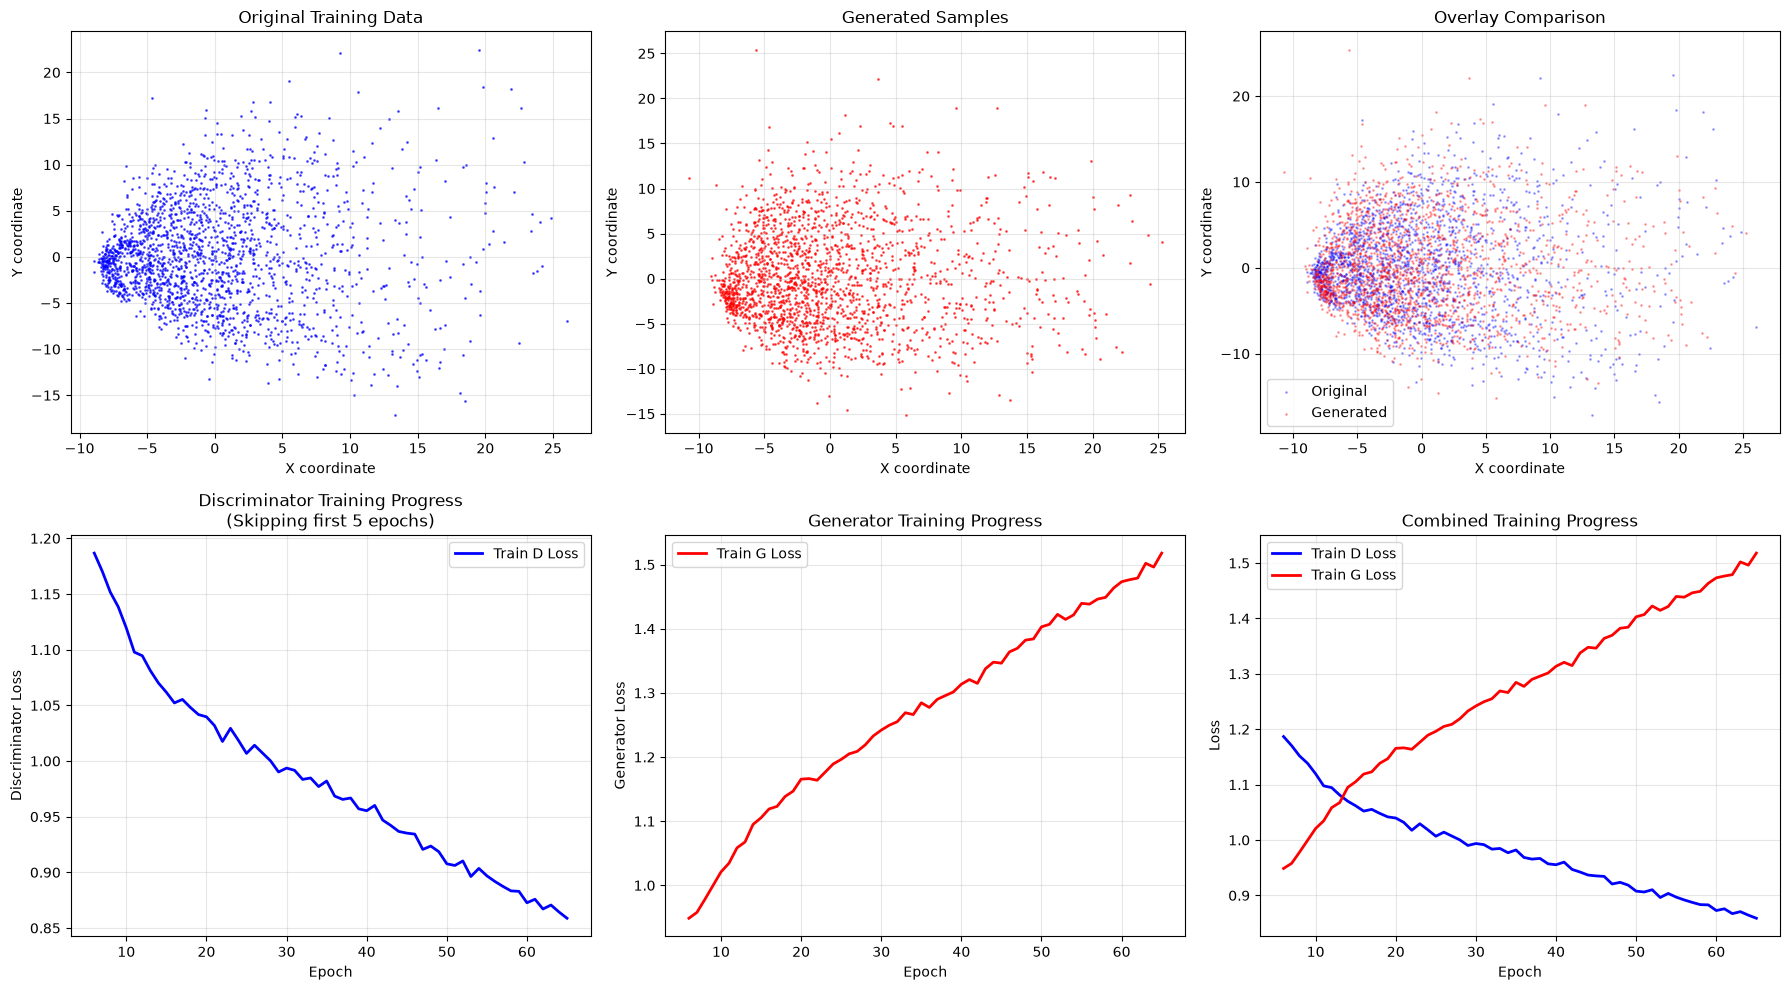

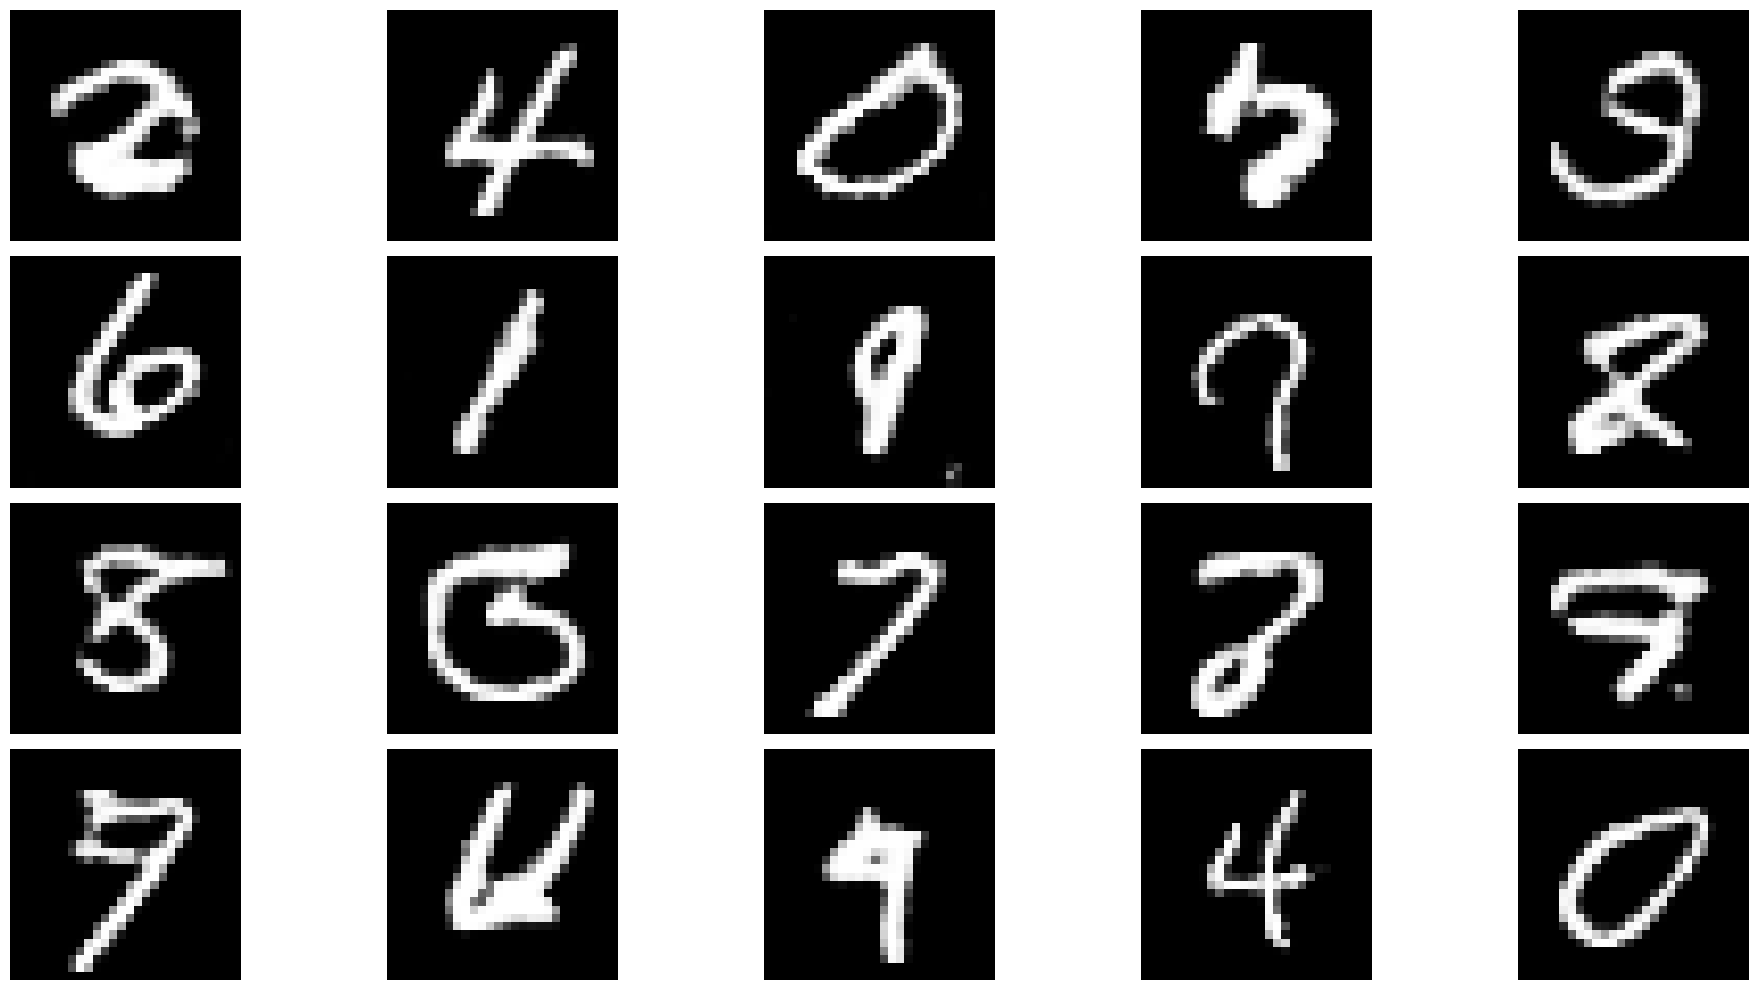

📈 Epoch 65 Summary:
   Train D Loss: 0.8588, Val D Loss: 1.1626
   Train G Loss: 1.5179, Val G Loss: 1.4948

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.774765	G_loss: 1.502825
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.906953	G_loss: 1.761332
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.721652	G_loss: 1.134887
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.871092	G_loss: 1.354267
Epoch: 66 [25600/60000 (43%)]	D_loss: 1.170424	G_loss: 2.256560
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.950714	G_loss: 2.097708
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.800515	G_loss: 1.447295
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.876113	G_loss: 1.987238
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.776050	G_loss: 1.262020
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.867165	G_loss: 1.525453
====> Epoch: 66 Train D_loss: 0.8598, Train G_loss: 1.5198
====> Epoch: 66 Val D_loss: 1.2120, Val G_loss: 1.5243
📈 Epoch 66 Summary:
   Train D Loss: 0.8598, Val D Loss: 1.2120
   Train G Loss: 1.5198

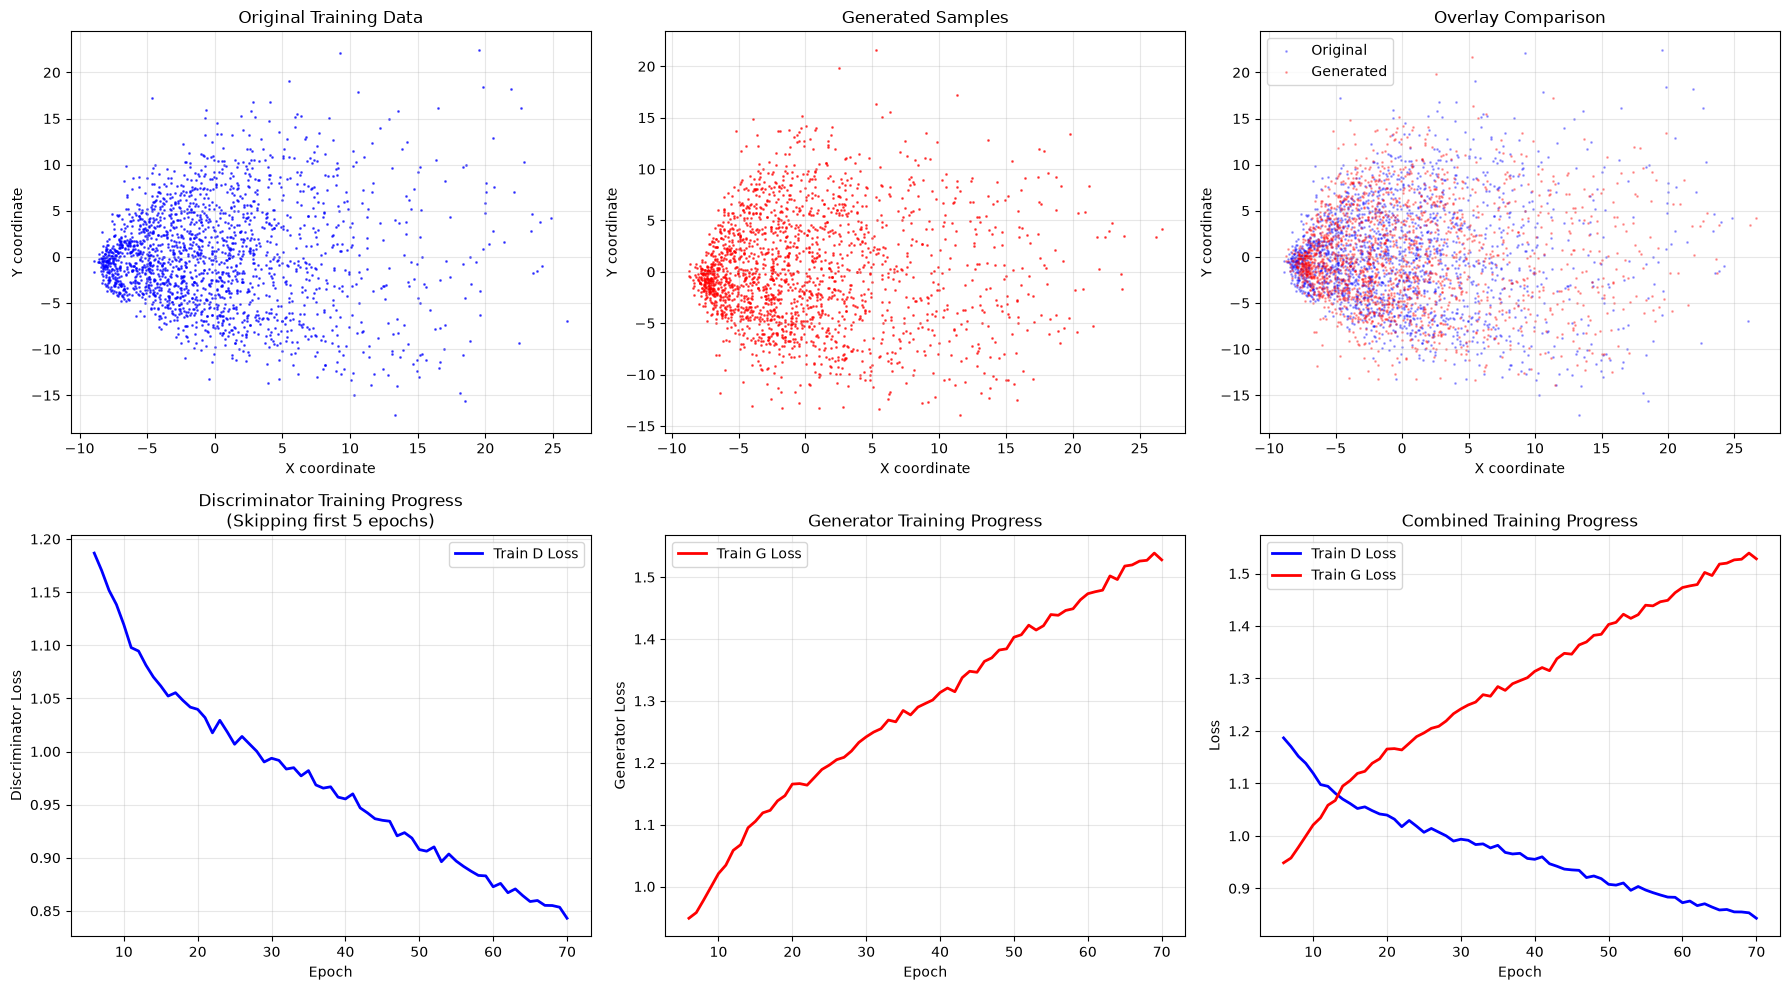

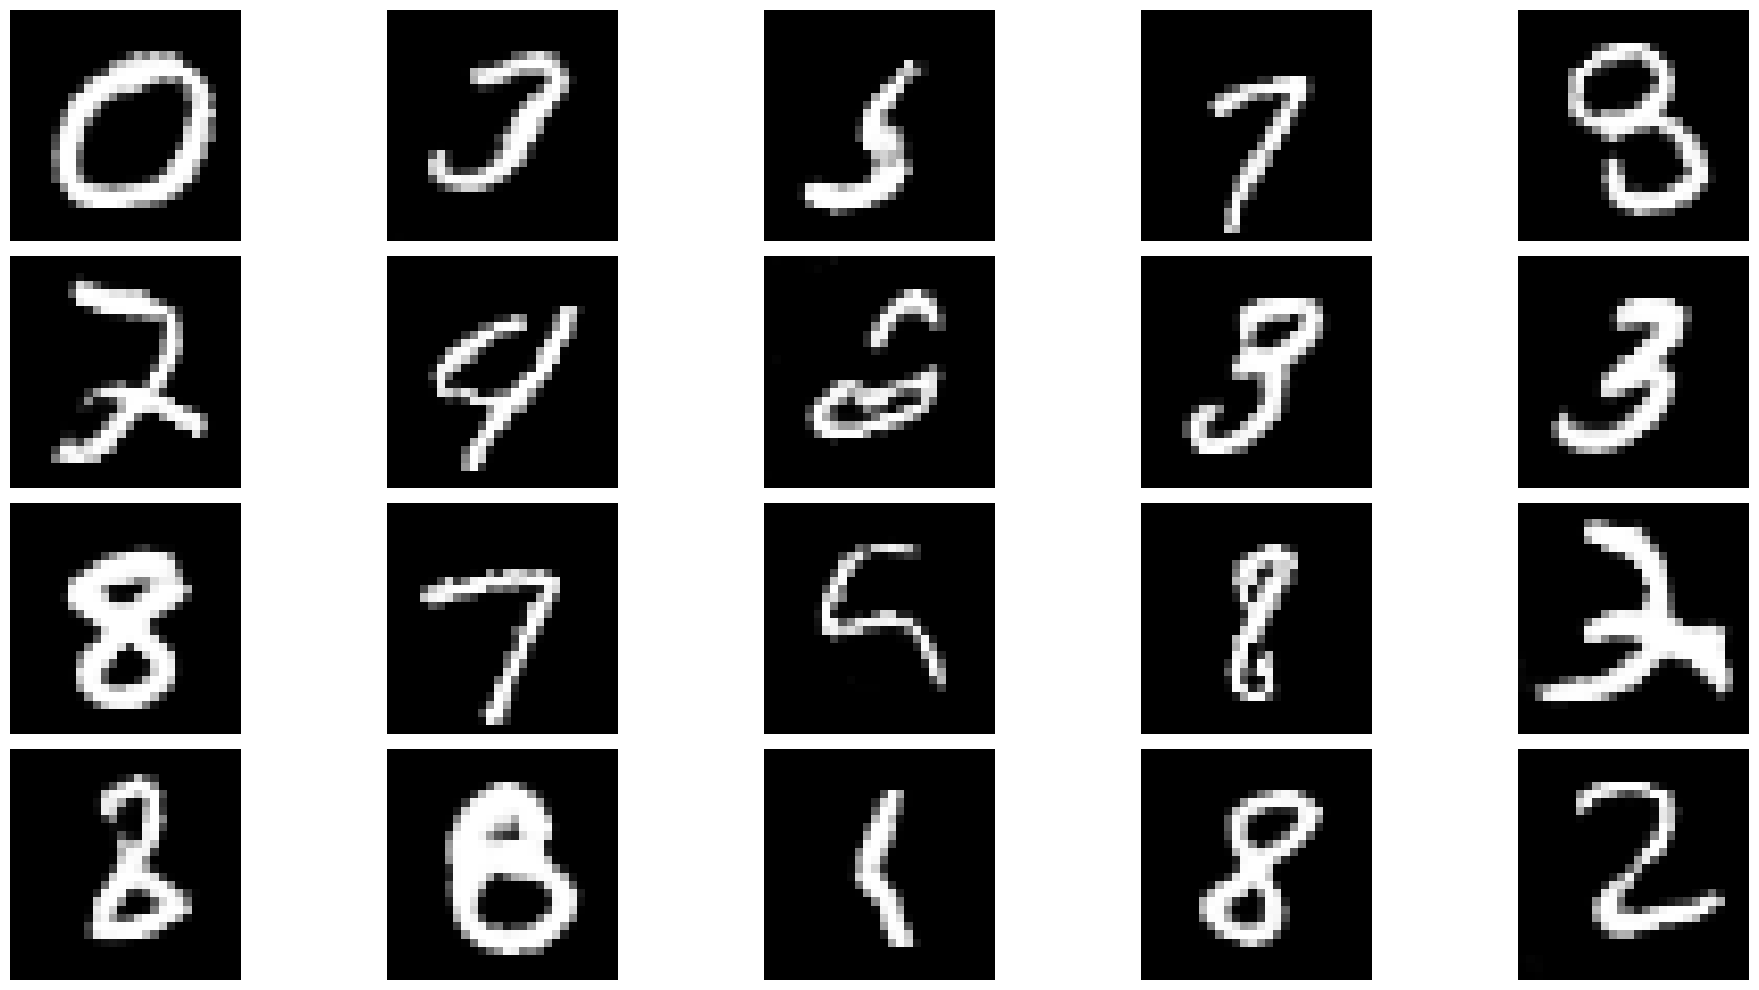

📈 Epoch 70 Summary:
   Train D Loss: 0.8431, Val D Loss: 1.1483
   Train G Loss: 1.5280, Val G Loss: 0.9255

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.679843	G_loss: 1.792511
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.234326	G_loss: 2.383118
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.780587	G_loss: 1.794861
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.968229	G_loss: 0.666432
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.338811	G_loss: 0.907091
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.769027	G_loss: 1.113815
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.685512	G_loss: 1.554798
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.816187	G_loss: 1.676181
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.791056	G_loss: 0.902058
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.837339	G_loss: 1.592441
====> Epoch: 71 Train D_loss: 0.8439, Train G_loss: 1.5566
====> Epoch: 71 Val D_loss: 1.2928, Val G_loss: 1.8823
📈 Epoch 71 Summary:
   Train D Loss: 0.8439, Val D Loss: 1.2928
   Train G Loss: 1.5566

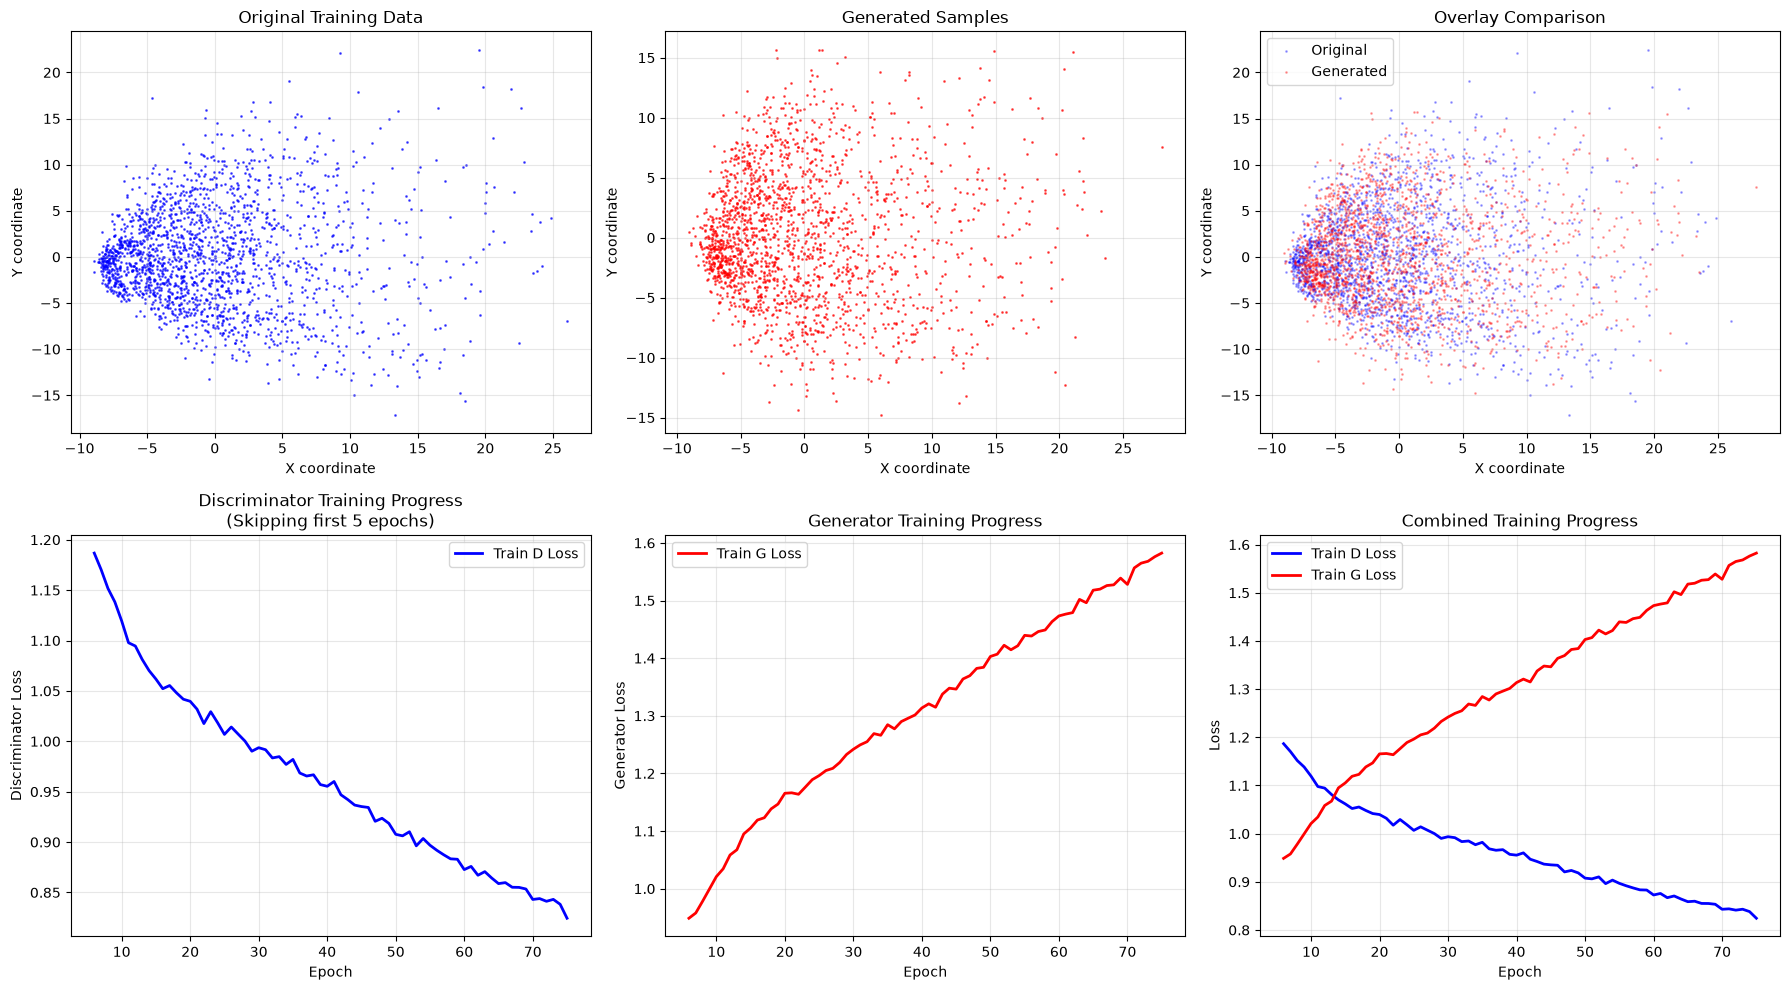

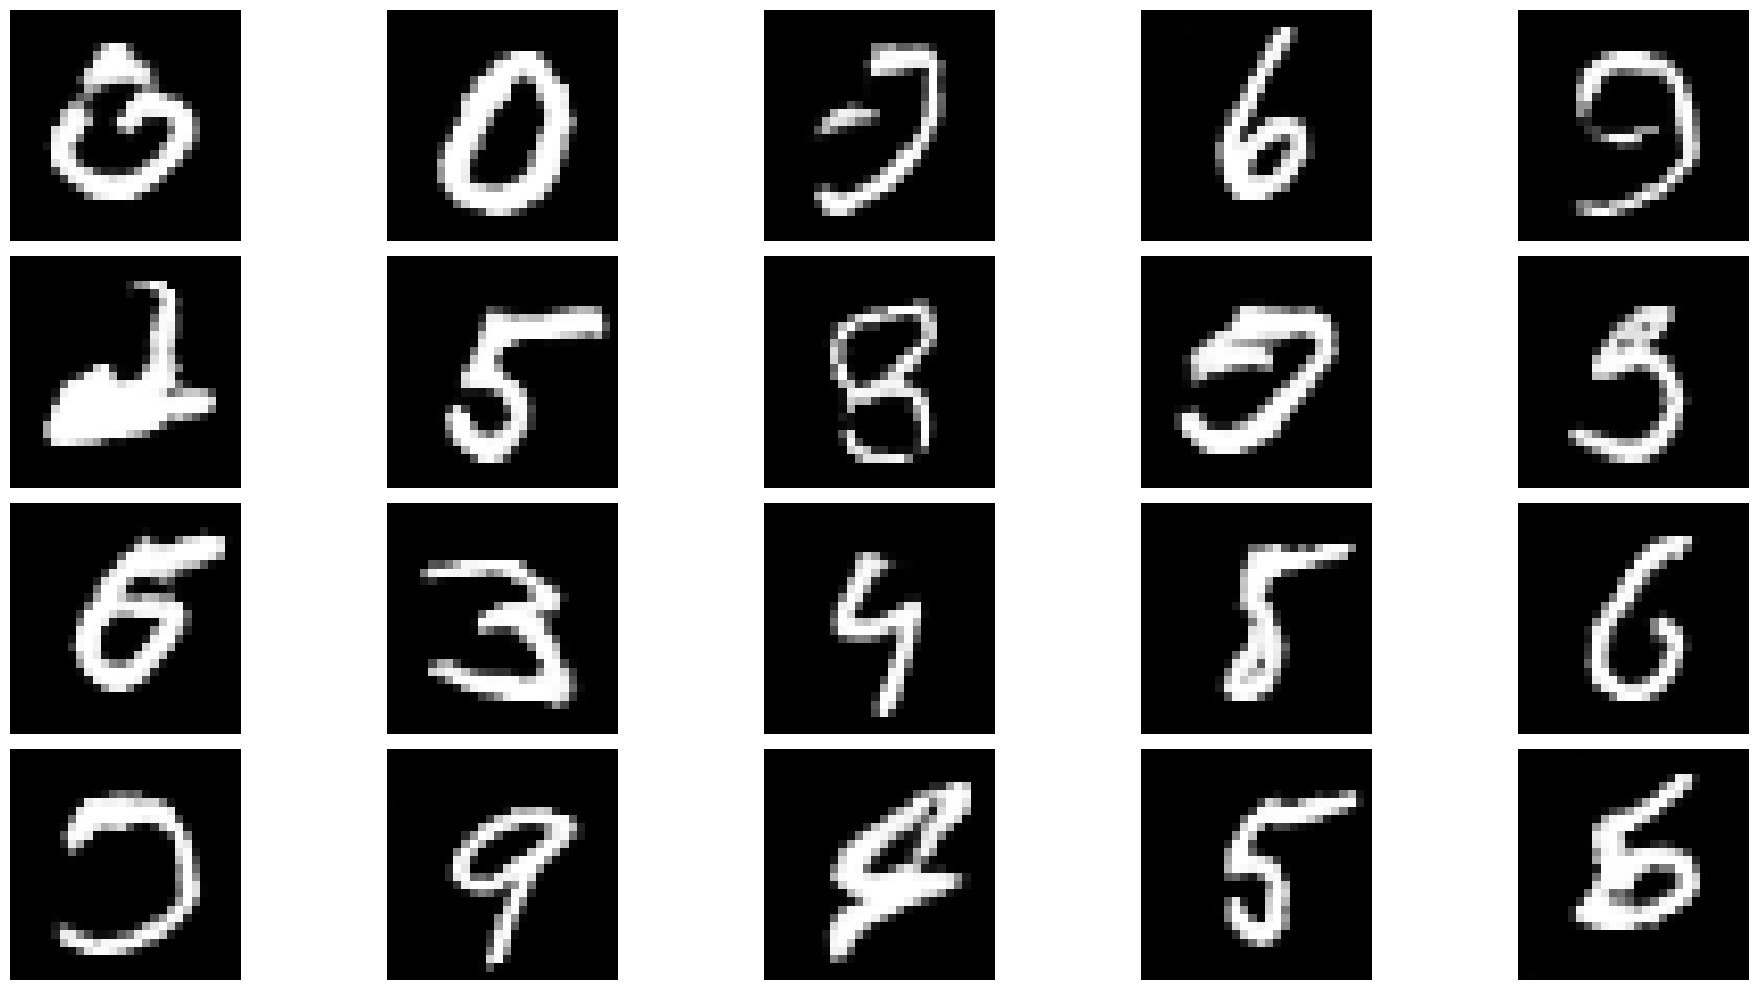

📈 Epoch 75 Summary:
   Train D Loss: 0.8244, Val D Loss: 1.1176
   Train G Loss: 1.5823, Val G Loss: 1.1973

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.758533	G_loss: 2.146588
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.758671	G_loss: 1.356765
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.757625	G_loss: 1.596194
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.836666	G_loss: 1.461976
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.990020	G_loss: 0.962920
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.930344	G_loss: 1.223270
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.716737	G_loss: 1.557759
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.990296	G_loss: 0.900058
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.702974	G_loss: 2.141869
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.662986	G_loss: 2.071214
====> Epoch: 76 Train D_loss: 0.8246, Train G_loss: 1.5923
====> Epoch: 76 Val D_loss: 1.3317, Val G_loss: 0.6090
📈 Epoch 76 Summary:
   Train D Loss: 0.8246, Val D Loss: 1.3317
   Train G Loss: 1.5923

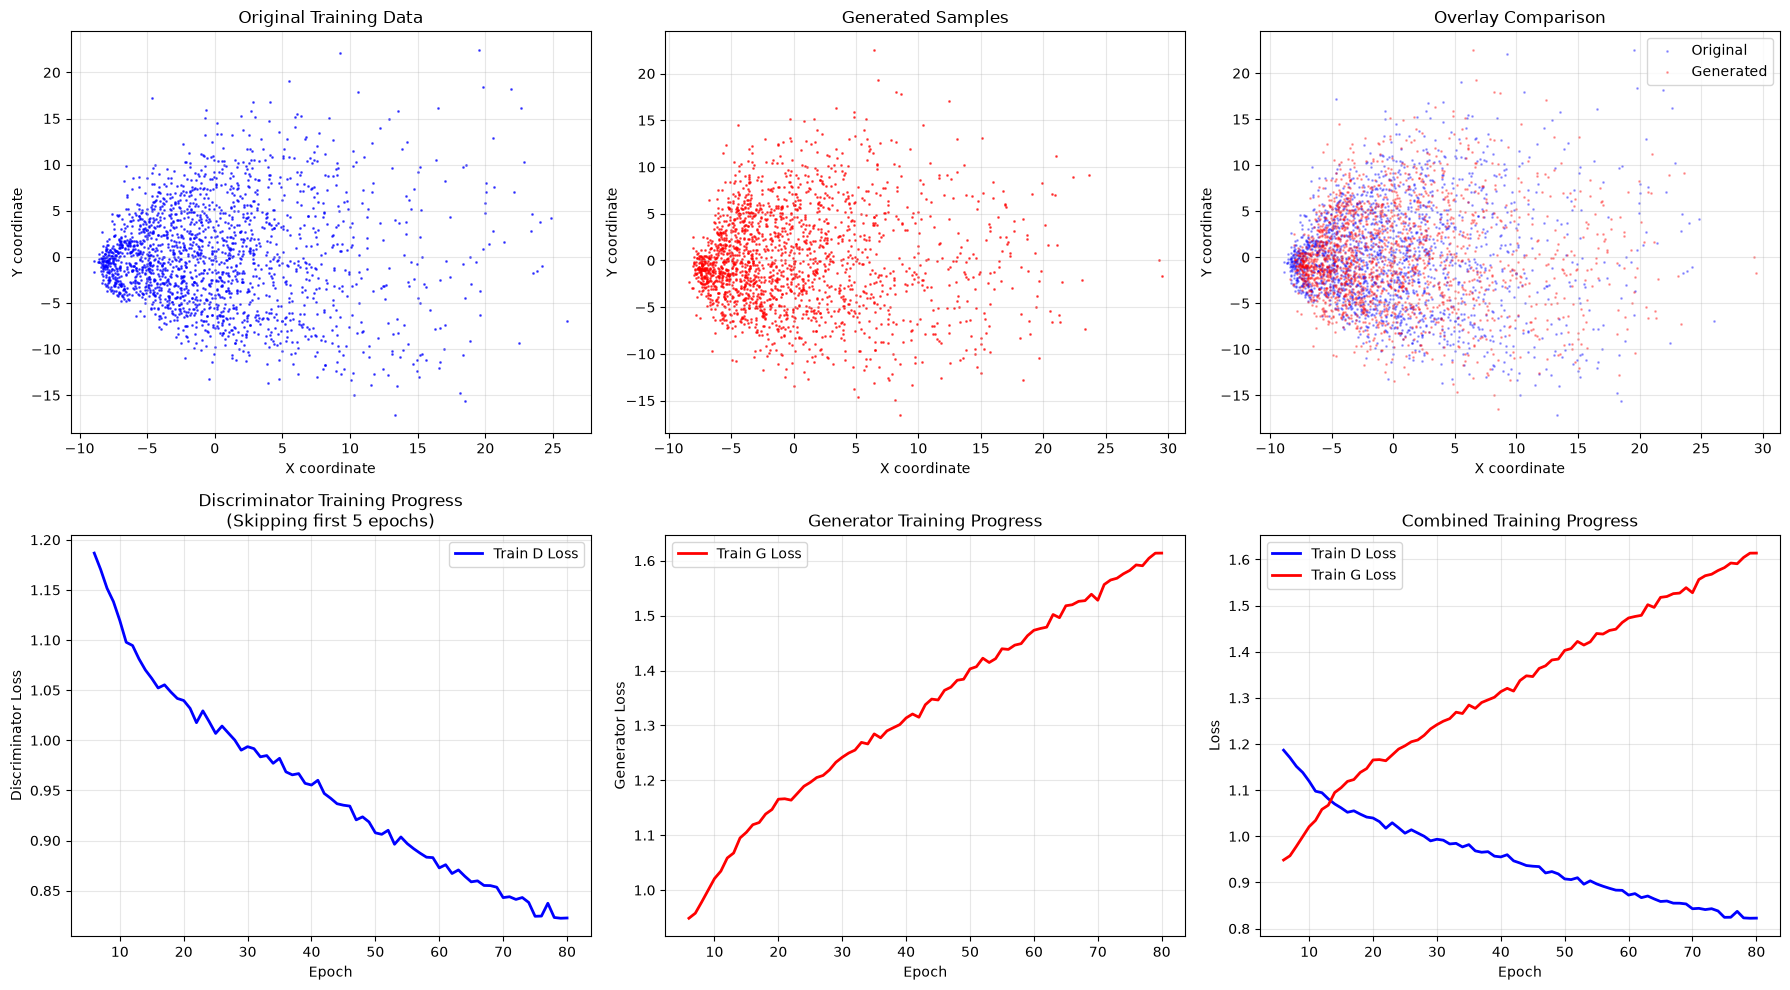

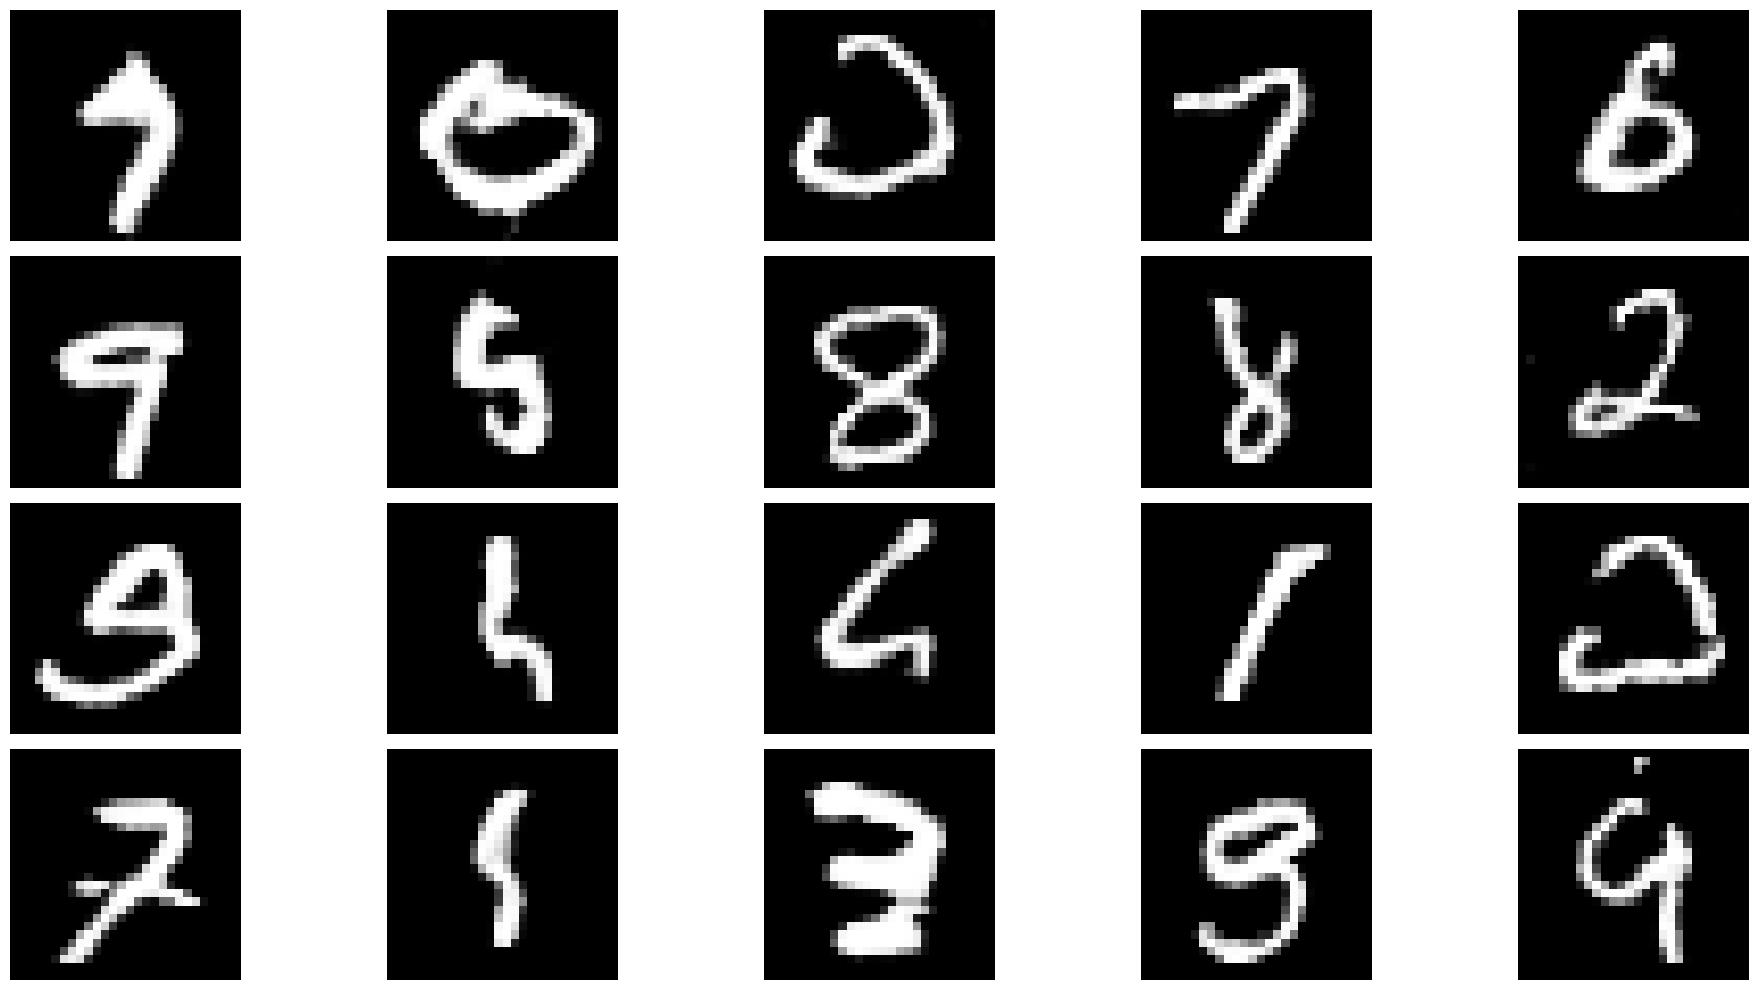

📈 Epoch 80 Summary:
   Train D Loss: 0.8227, Val D Loss: 1.2880
   Train G Loss: 1.6139, Val G Loss: 0.7066

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.839364	G_loss: 2.511479
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.627375	G_loss: 1.781955
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.910852	G_loss: 2.107686
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.835244	G_loss: 2.019344
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.635311	G_loss: 1.552959
Epoch: 81 [32000/60000 (53%)]	D_loss: 1.081163	G_loss: 0.917470
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.895290	G_loss: 1.927579
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.871127	G_loss: 0.673486
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.796468	G_loss: 1.868117
Epoch: 81 [57600/60000 (96%)]	D_loss: 1.177526	G_loss: 1.765146
====> Epoch: 81 Train D_loss: 0.8178, Train G_loss: 1.6241
====> Epoch: 81 Val D_loss: 1.2998, Val G_loss: 1.8151
📈 Epoch 81 Summary:
   Train D Loss: 0.8178, Val D Loss: 1.2998
   Train G Loss: 1.6241

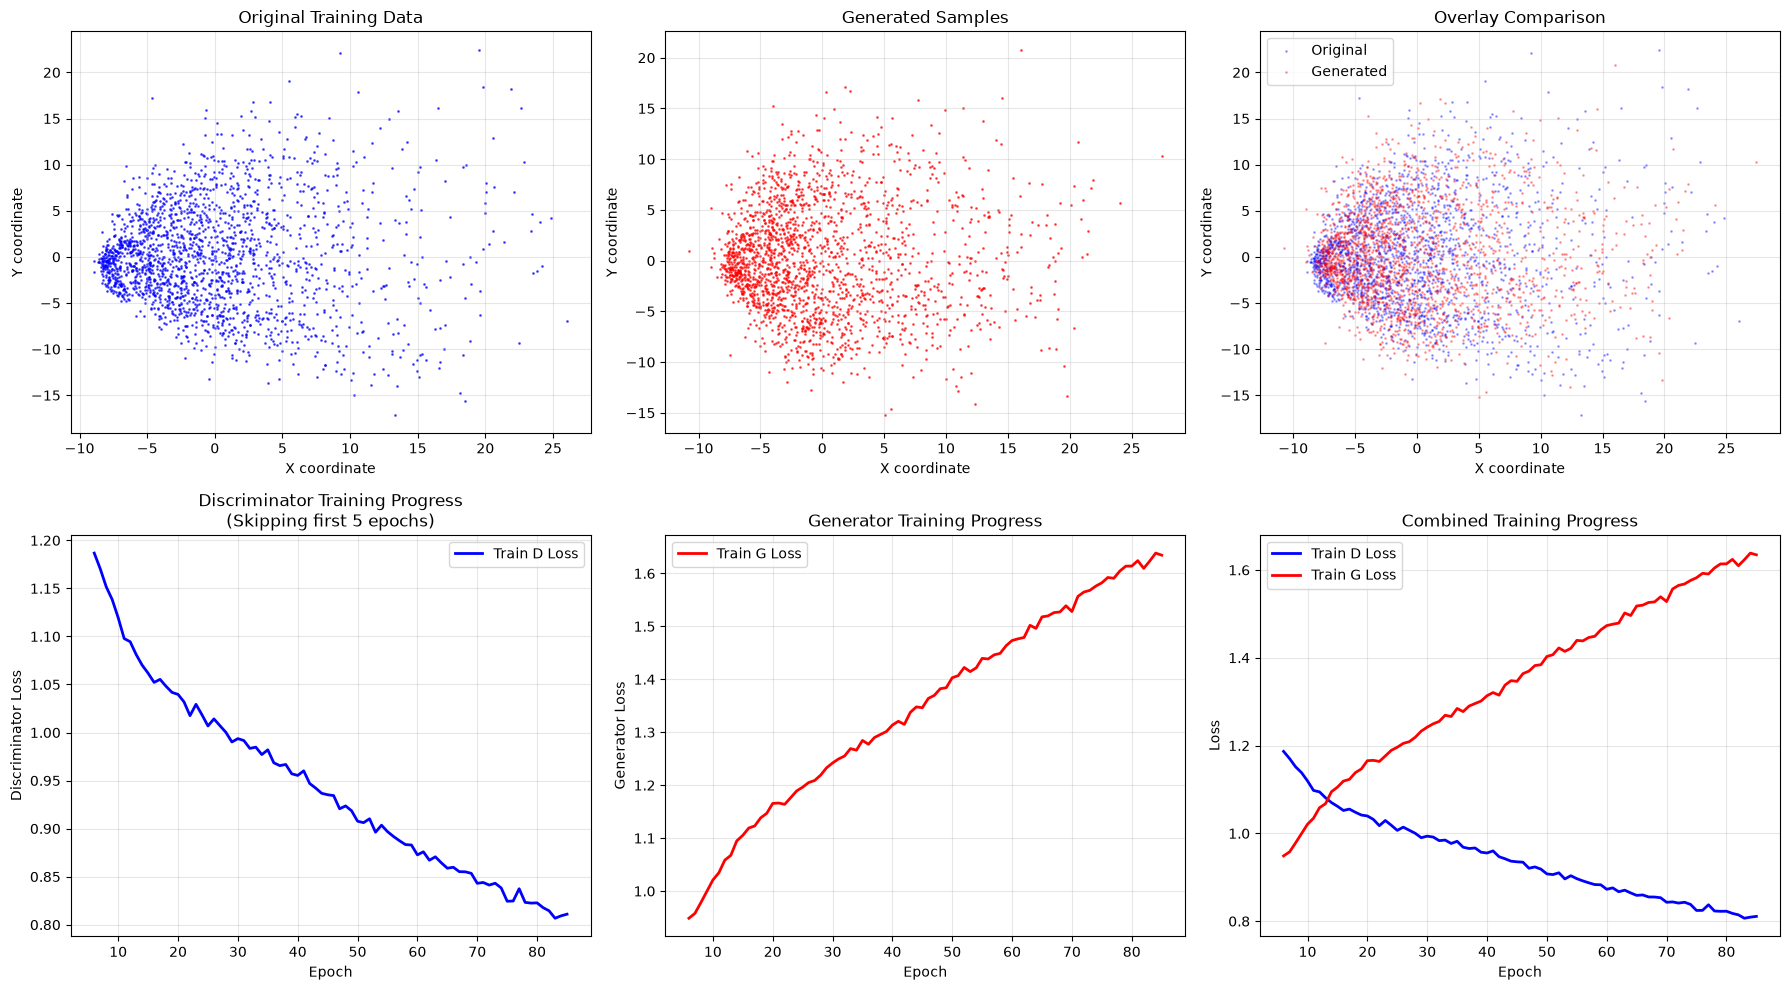

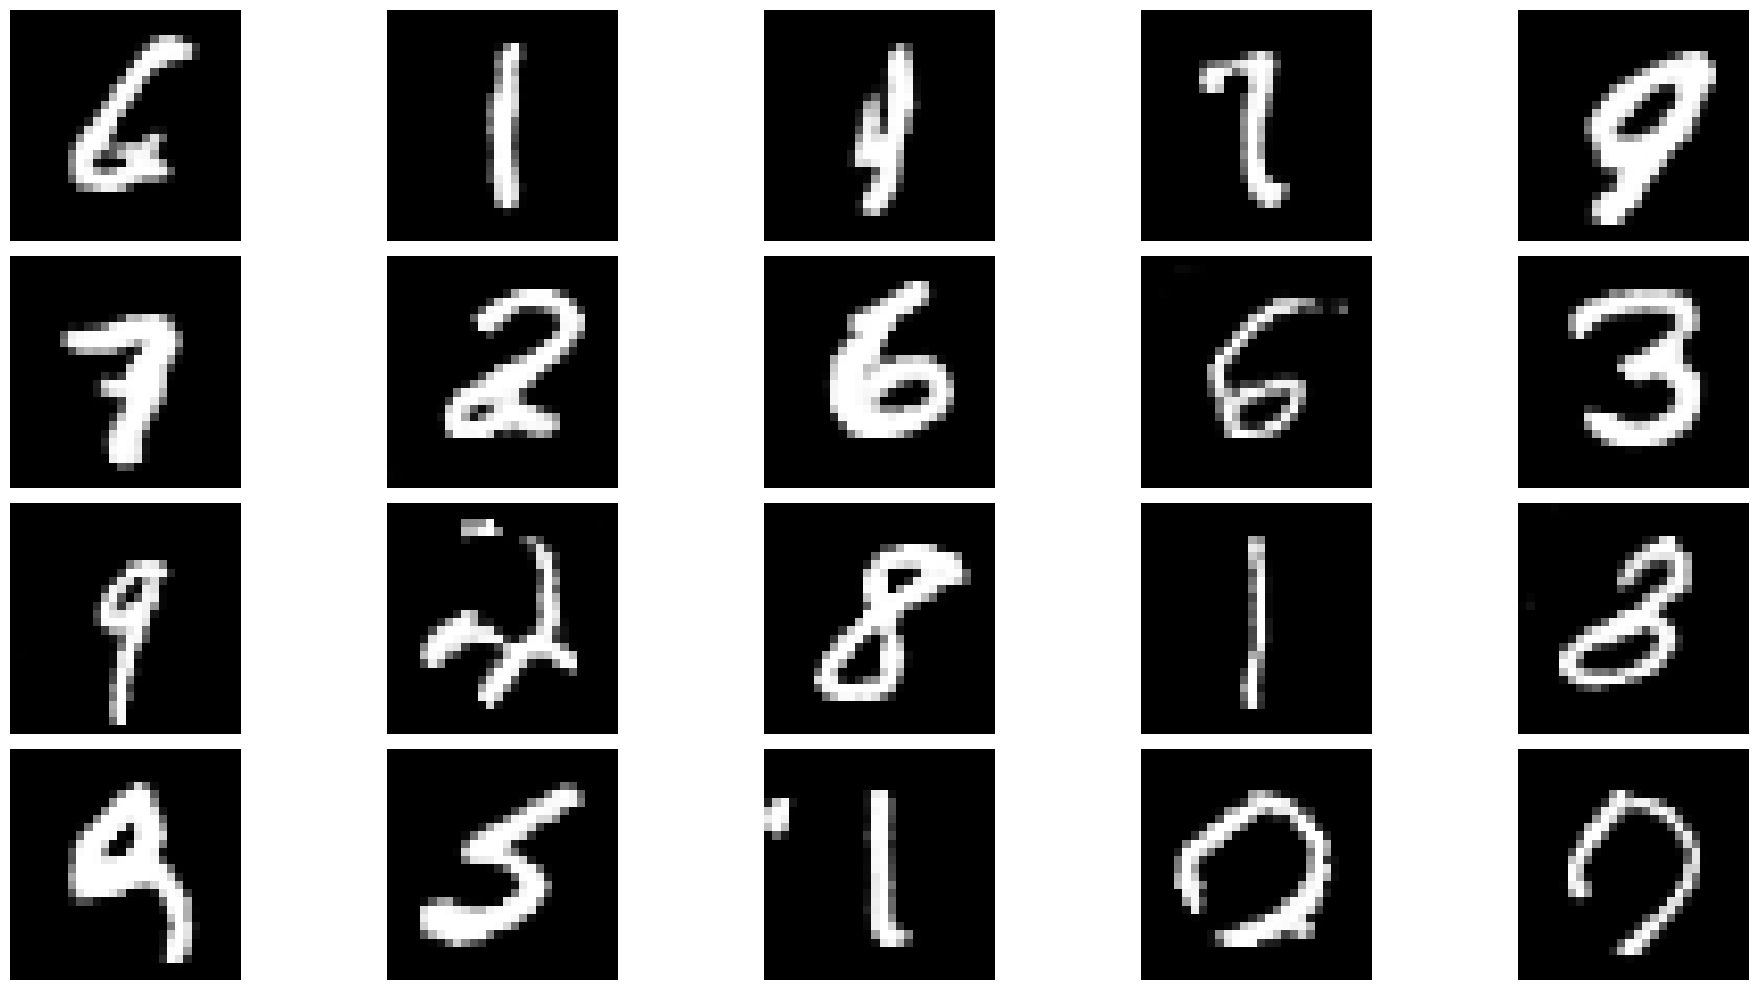

📈 Epoch 85 Summary:
   Train D Loss: 0.8109, Val D Loss: 1.1913
   Train G Loss: 1.6345, Val G Loss: 1.6302

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.670470	G_loss: 1.792264
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.791406	G_loss: 1.734794
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.796119	G_loss: 1.324042
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.907385	G_loss: 0.896600
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.800963	G_loss: 1.604149
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.796253	G_loss: 1.390675
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.807605	G_loss: 1.716252
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.748813	G_loss: 2.687909
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.853492	G_loss: 2.245714
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.942921	G_loss: 1.431122
====> Epoch: 86 Train D_loss: 0.7961, Train G_loss: 1.6515
====> Epoch: 86 Val D_loss: 1.1435, Val G_loss: 0.9927
📈 Epoch 86 Summary:
   Train D Loss: 0.7961, Val D Loss: 1.1435
   Train G Loss: 1.6515

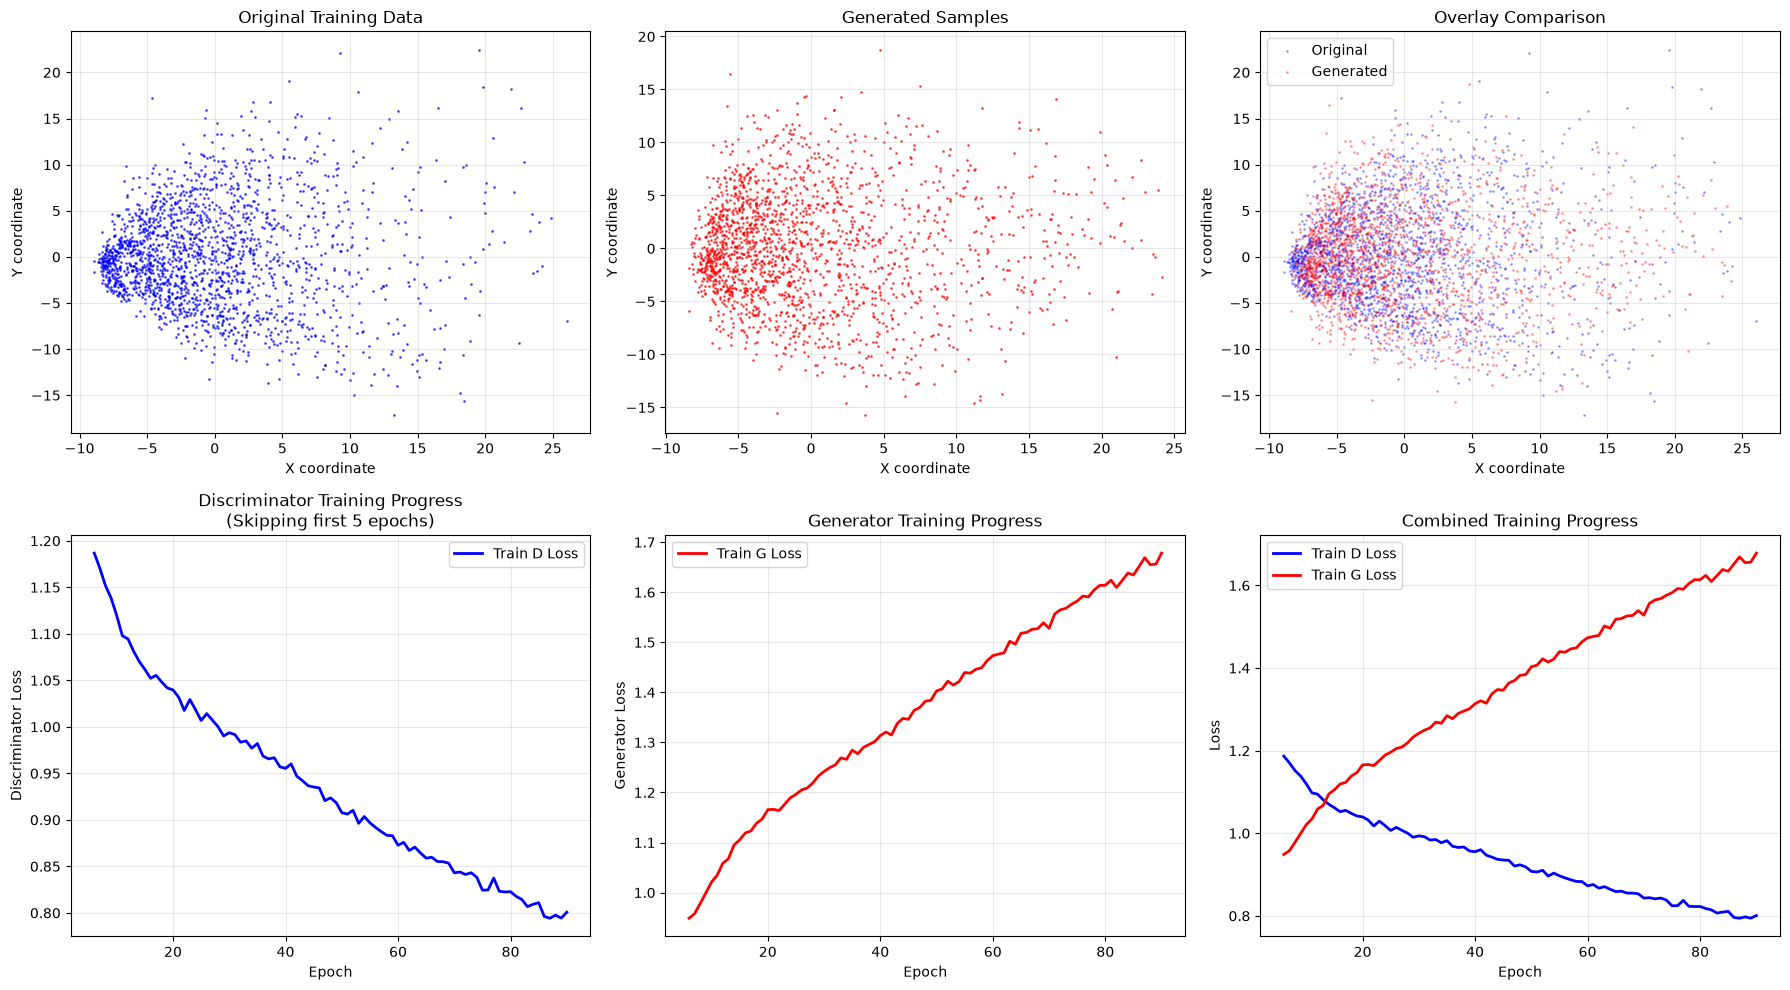

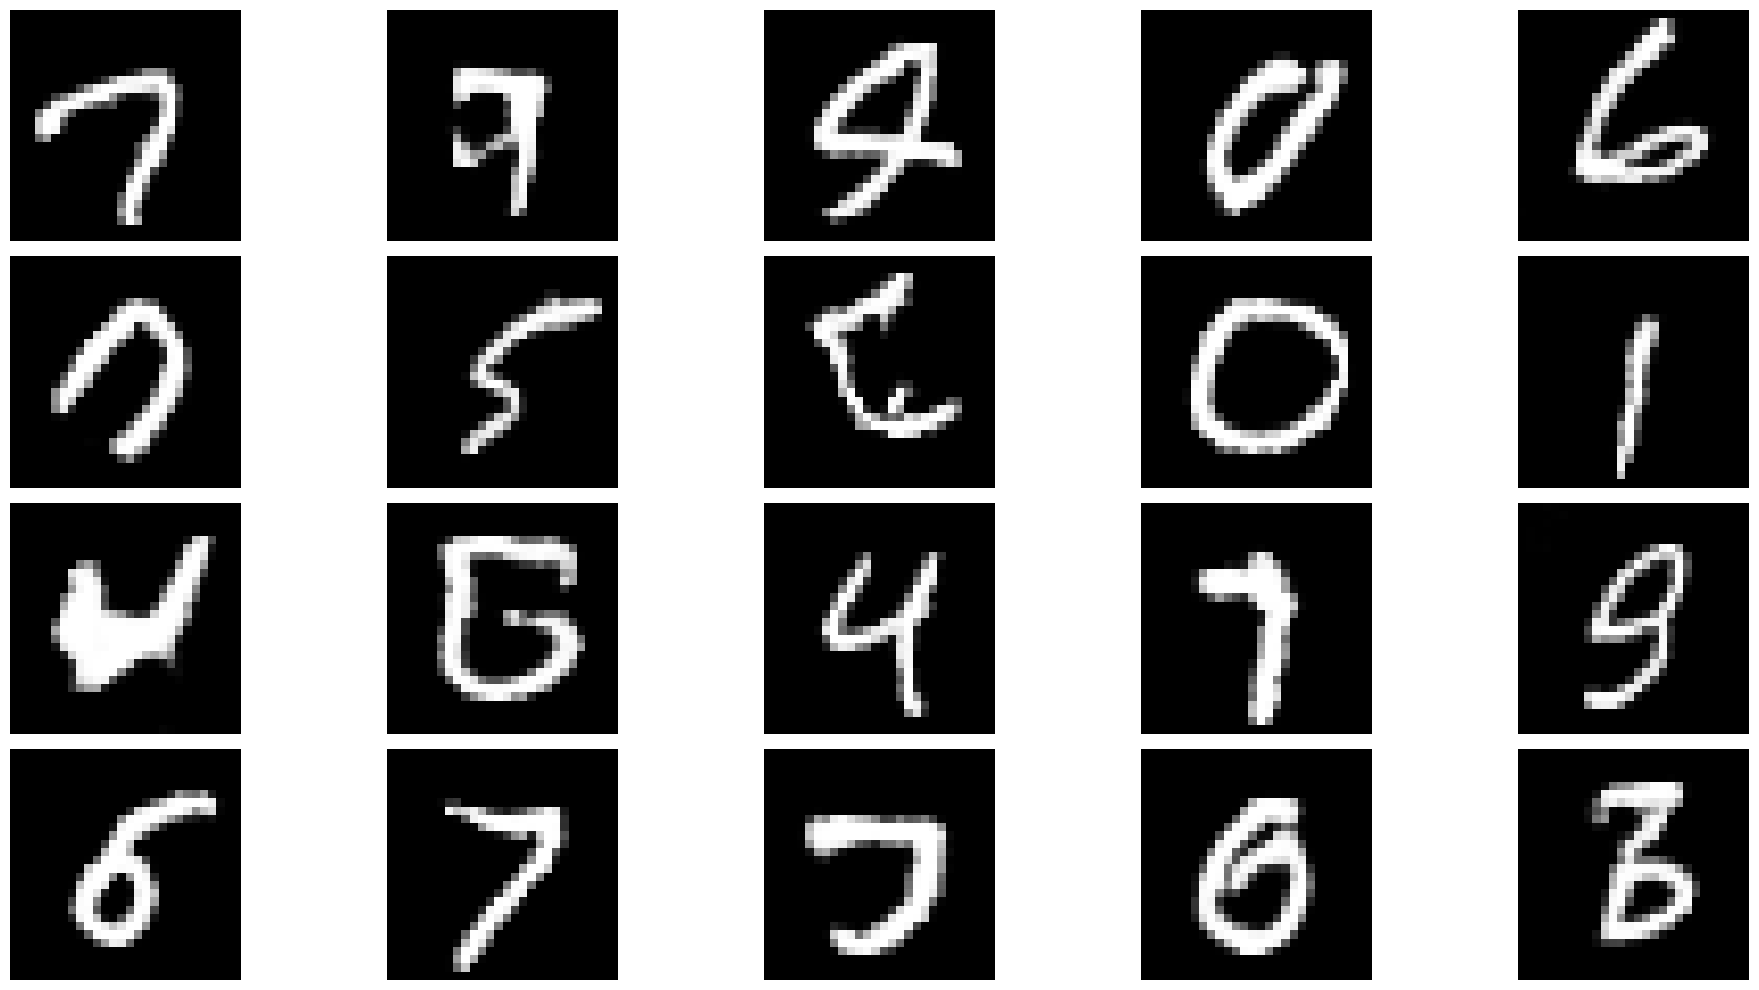

📈 Epoch 90 Summary:
   Train D Loss: 0.8007, Val D Loss: 1.1363
   Train G Loss: 1.6782, Val G Loss: 1.0146

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.601066	G_loss: 2.040838
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.706805	G_loss: 1.795888
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.793341	G_loss: 2.067567
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.637002	G_loss: 1.681792
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.703520	G_loss: 1.862007
Epoch: 91 [32000/60000 (53%)]	D_loss: 1.189905	G_loss: 0.911476
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.035737	G_loss: 0.582975
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.671698	G_loss: 2.089843
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.744122	G_loss: 2.518130
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.887639	G_loss: 2.647923
====> Epoch: 91 Train D_loss: 0.7968, Train G_loss: 1.6915
====> Epoch: 91 Val D_loss: 1.1941, Val G_loss: 1.6229
📈 Epoch 91 Summary:
   Train D Loss: 0.7968, Val D Loss: 1.1941
   Train G Loss: 1.6915

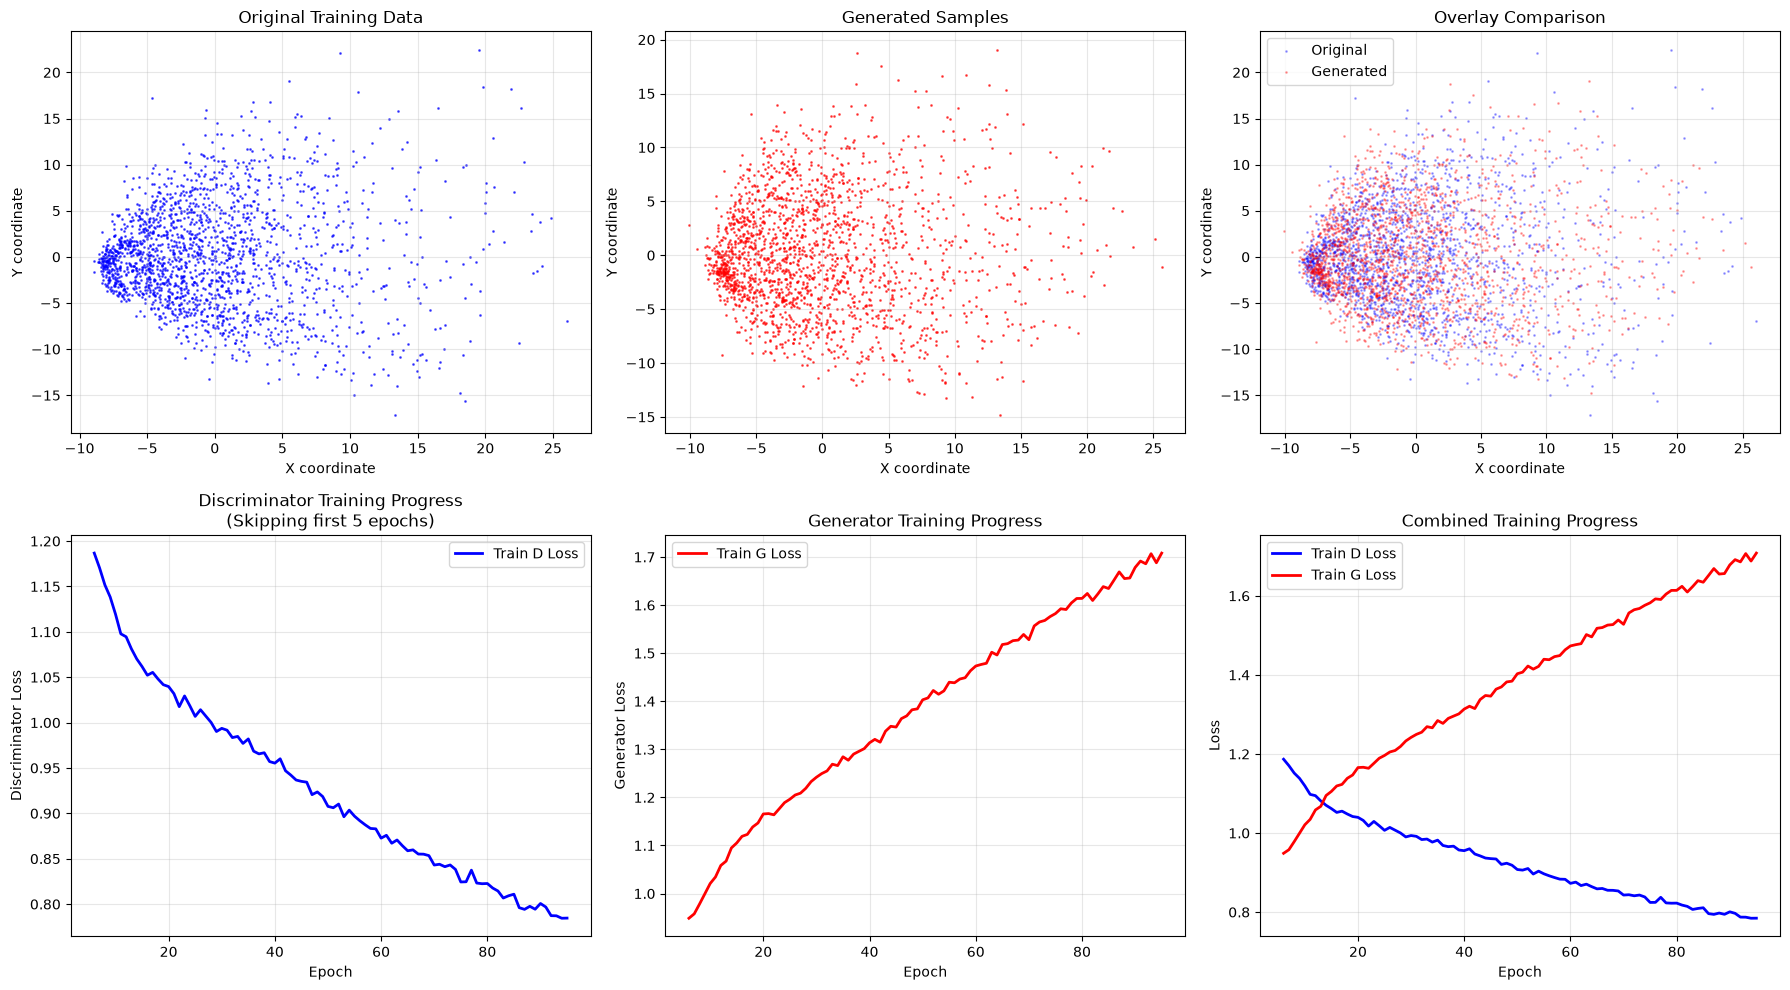

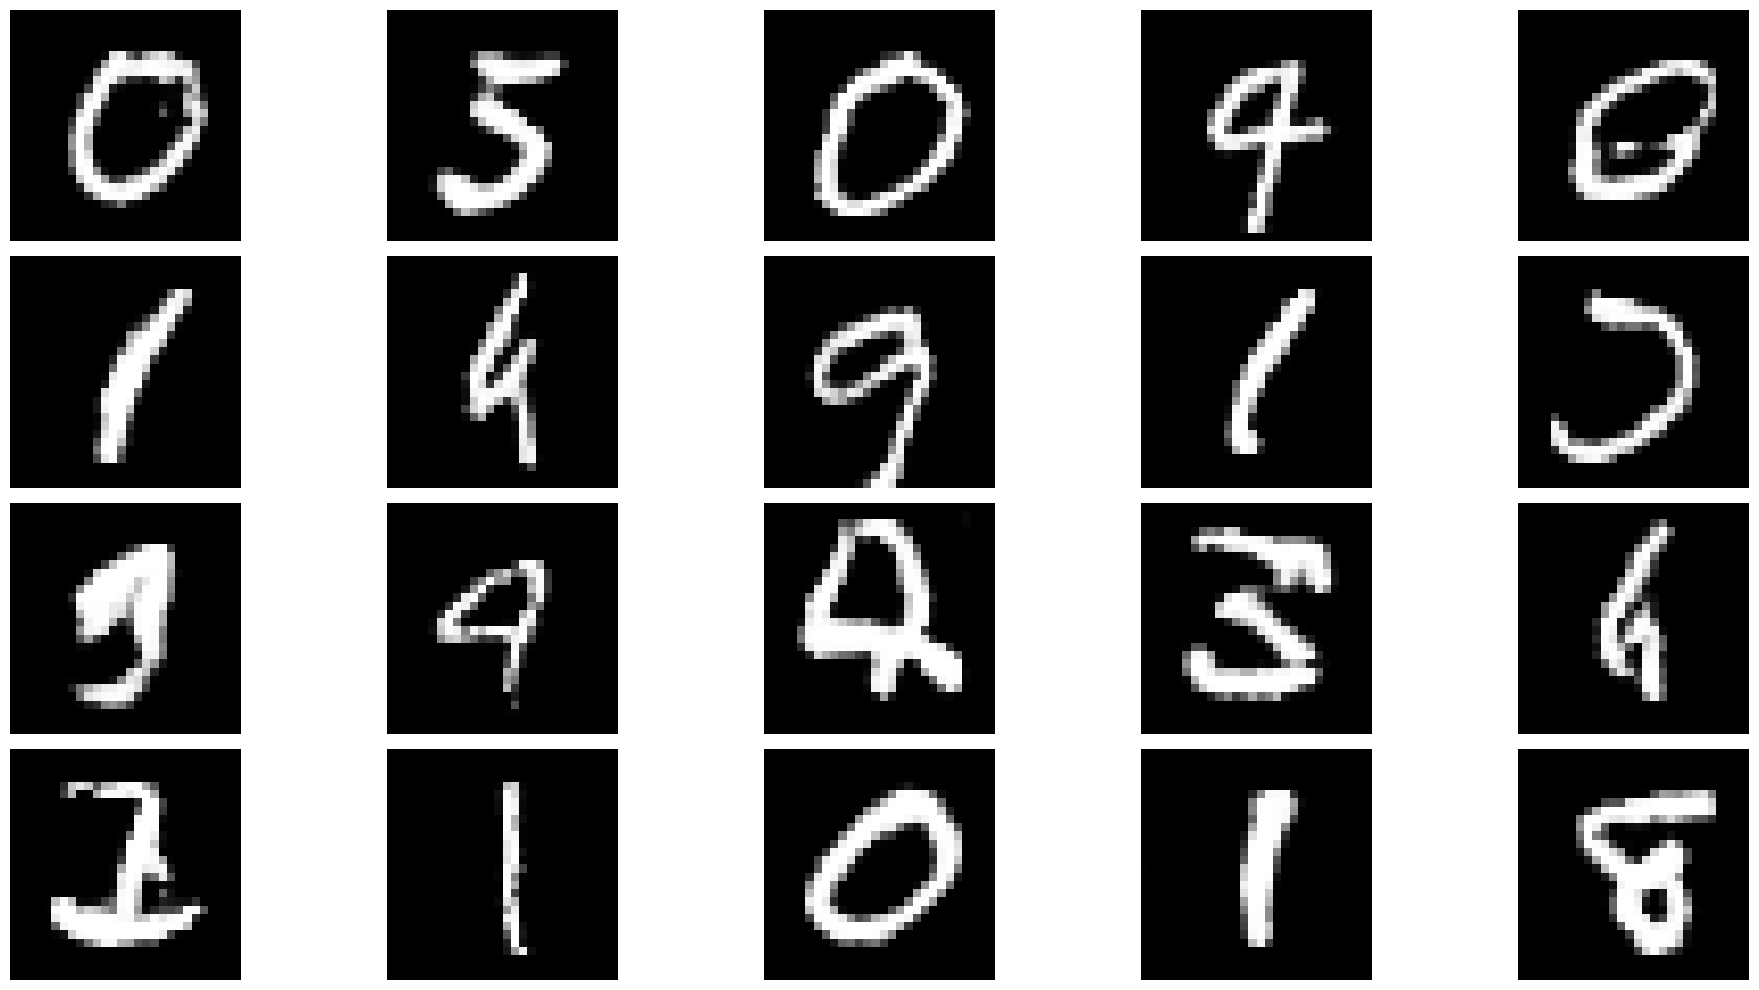

📈 Epoch 95 Summary:
   Train D Loss: 0.7846, Val D Loss: 1.1018
   Train G Loss: 1.7081, Val G Loss: 1.2690

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.684001	G_loss: 1.773085
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.701761	G_loss: 2.157304
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.862505	G_loss: 1.268589
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.887707	G_loss: 2.373285
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.682958	G_loss: 1.347470
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.649813	G_loss: 1.204592
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.620103	G_loss: 2.358679
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.780448	G_loss: 0.841191
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.702124	G_loss: 1.809151
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.704184	G_loss: 1.831937
====> Epoch: 96 Train D_loss: 0.7754, Train G_loss: 1.7108
====> Epoch: 96 Val D_loss: 1.2766, Val G_loss: 0.7391
📈 Epoch 96 Summary:
   Train D Loss: 0.7754, Val D Loss: 1.2766
   Train G Loss: 1.7108

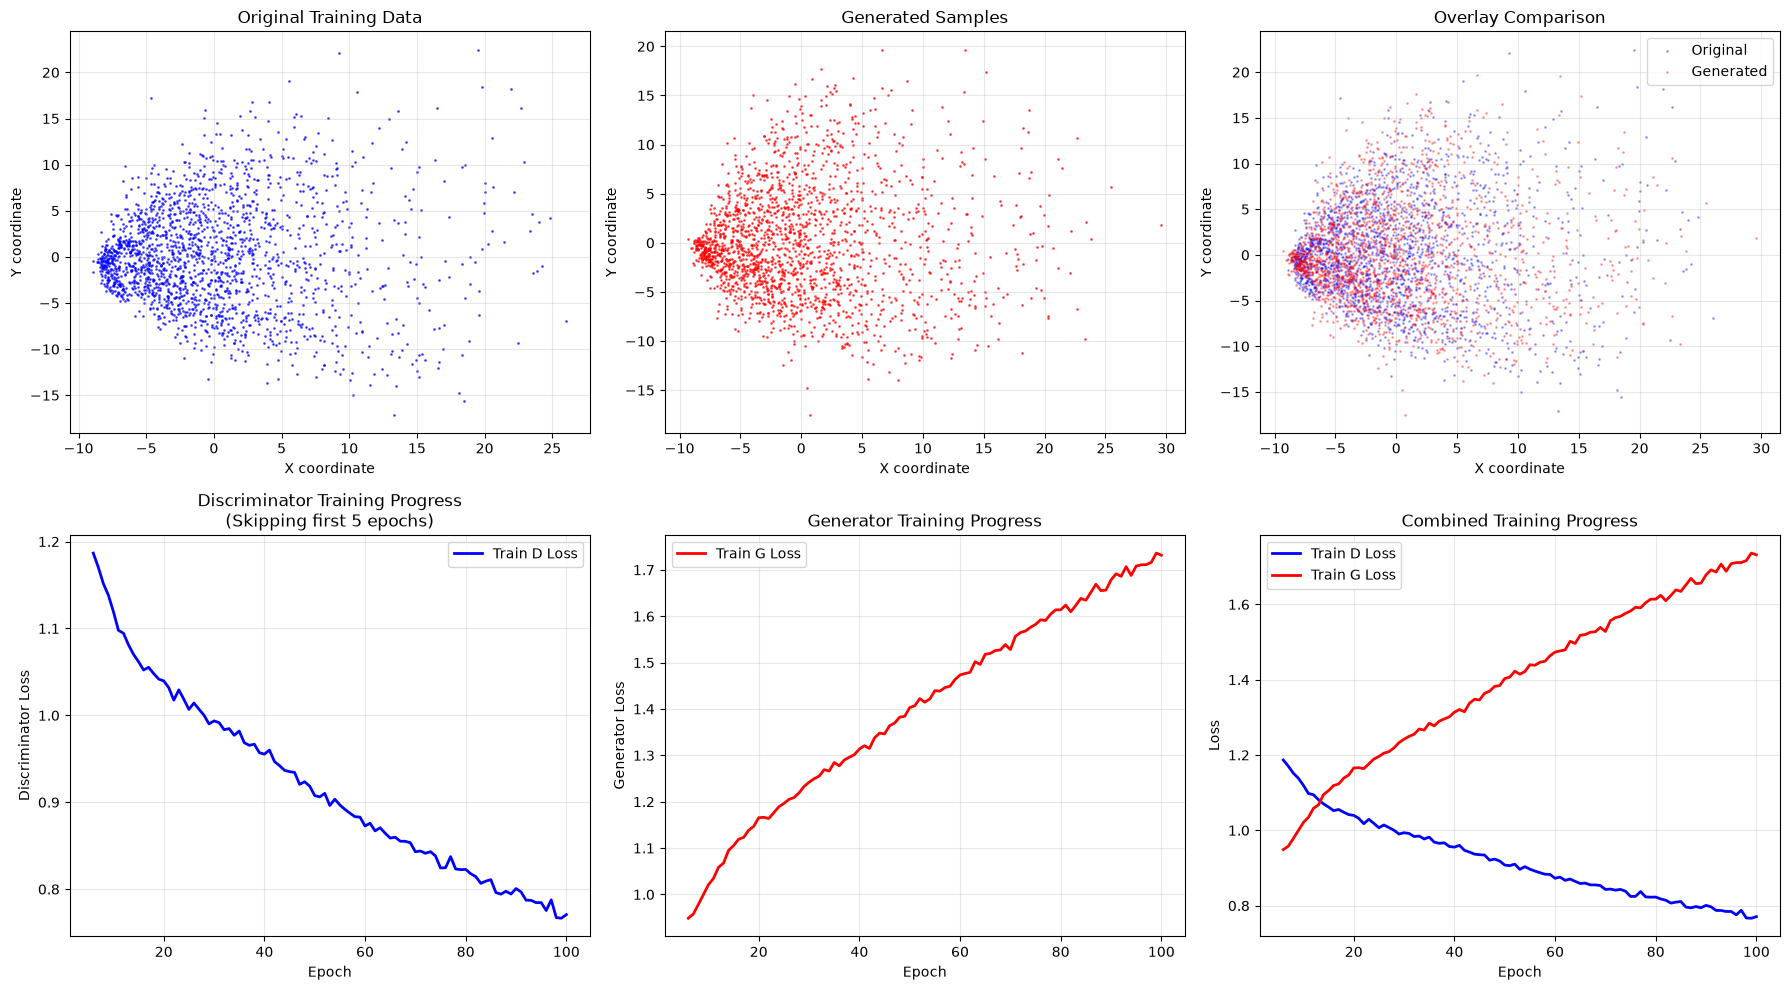

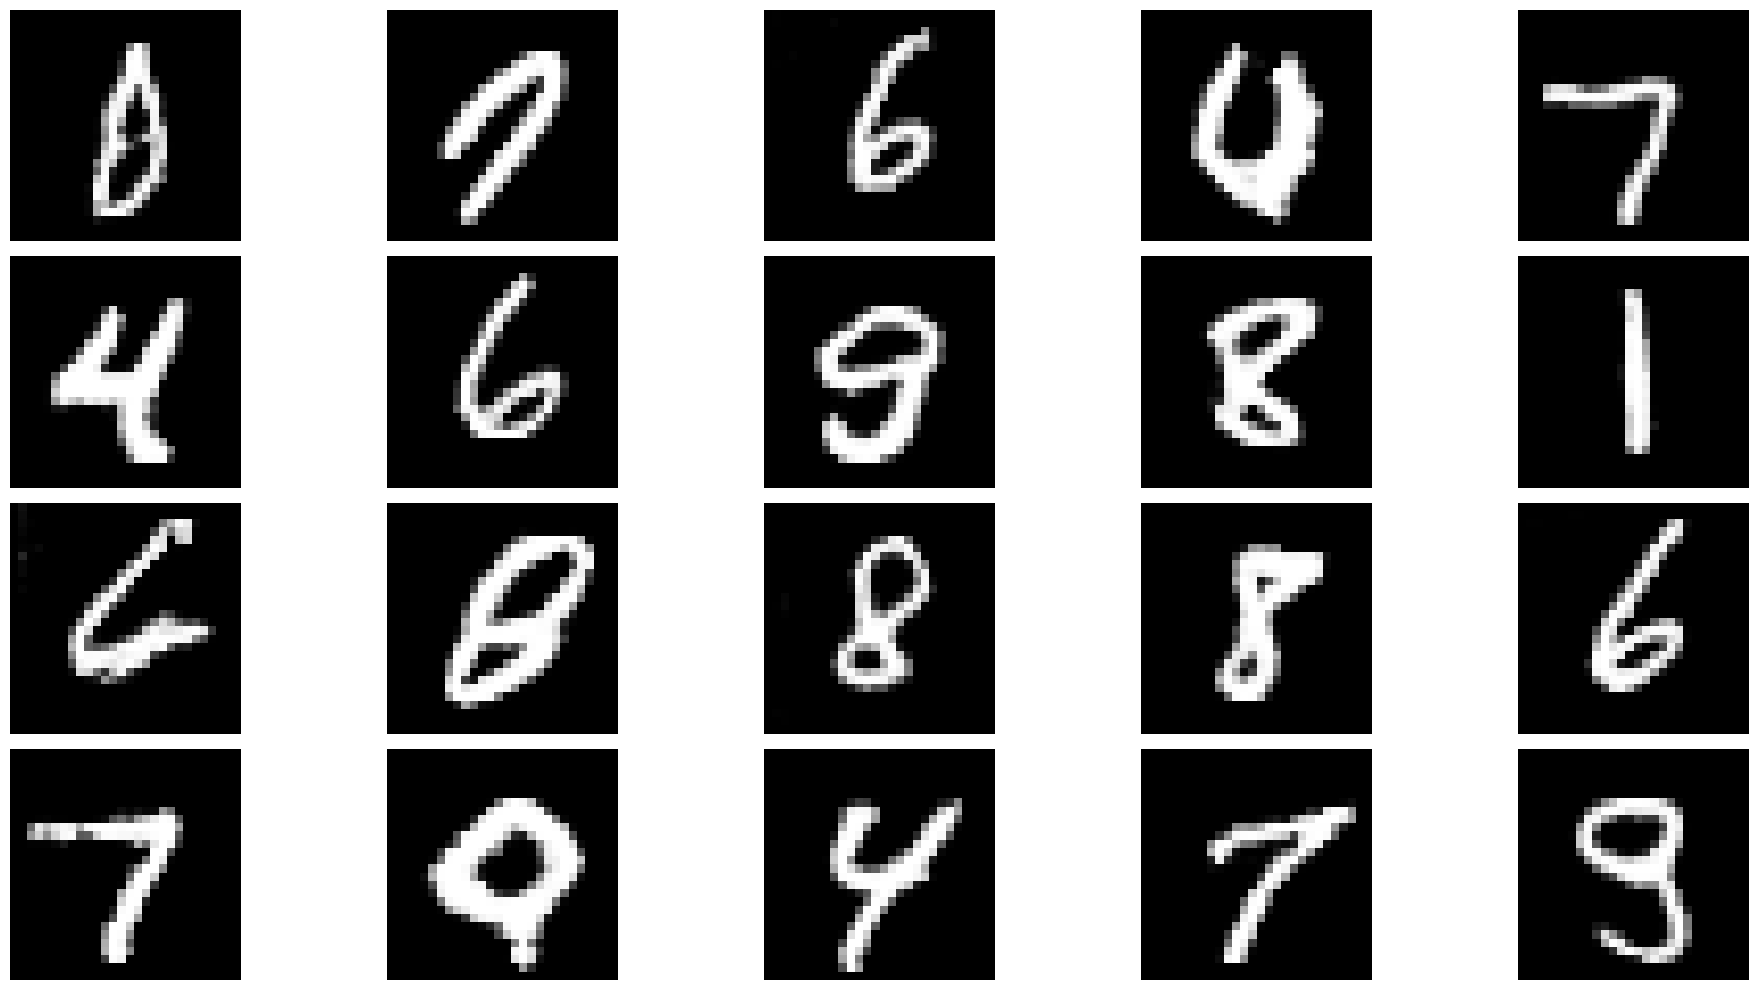

📈 Epoch 100 Summary:
   Train D Loss: 0.7707, Val D Loss: 1.0982
   Train G Loss: 1.7316, Val G Loss: 1.4740

🎉 Training completed!

🎨 Final comprehensive visualization:


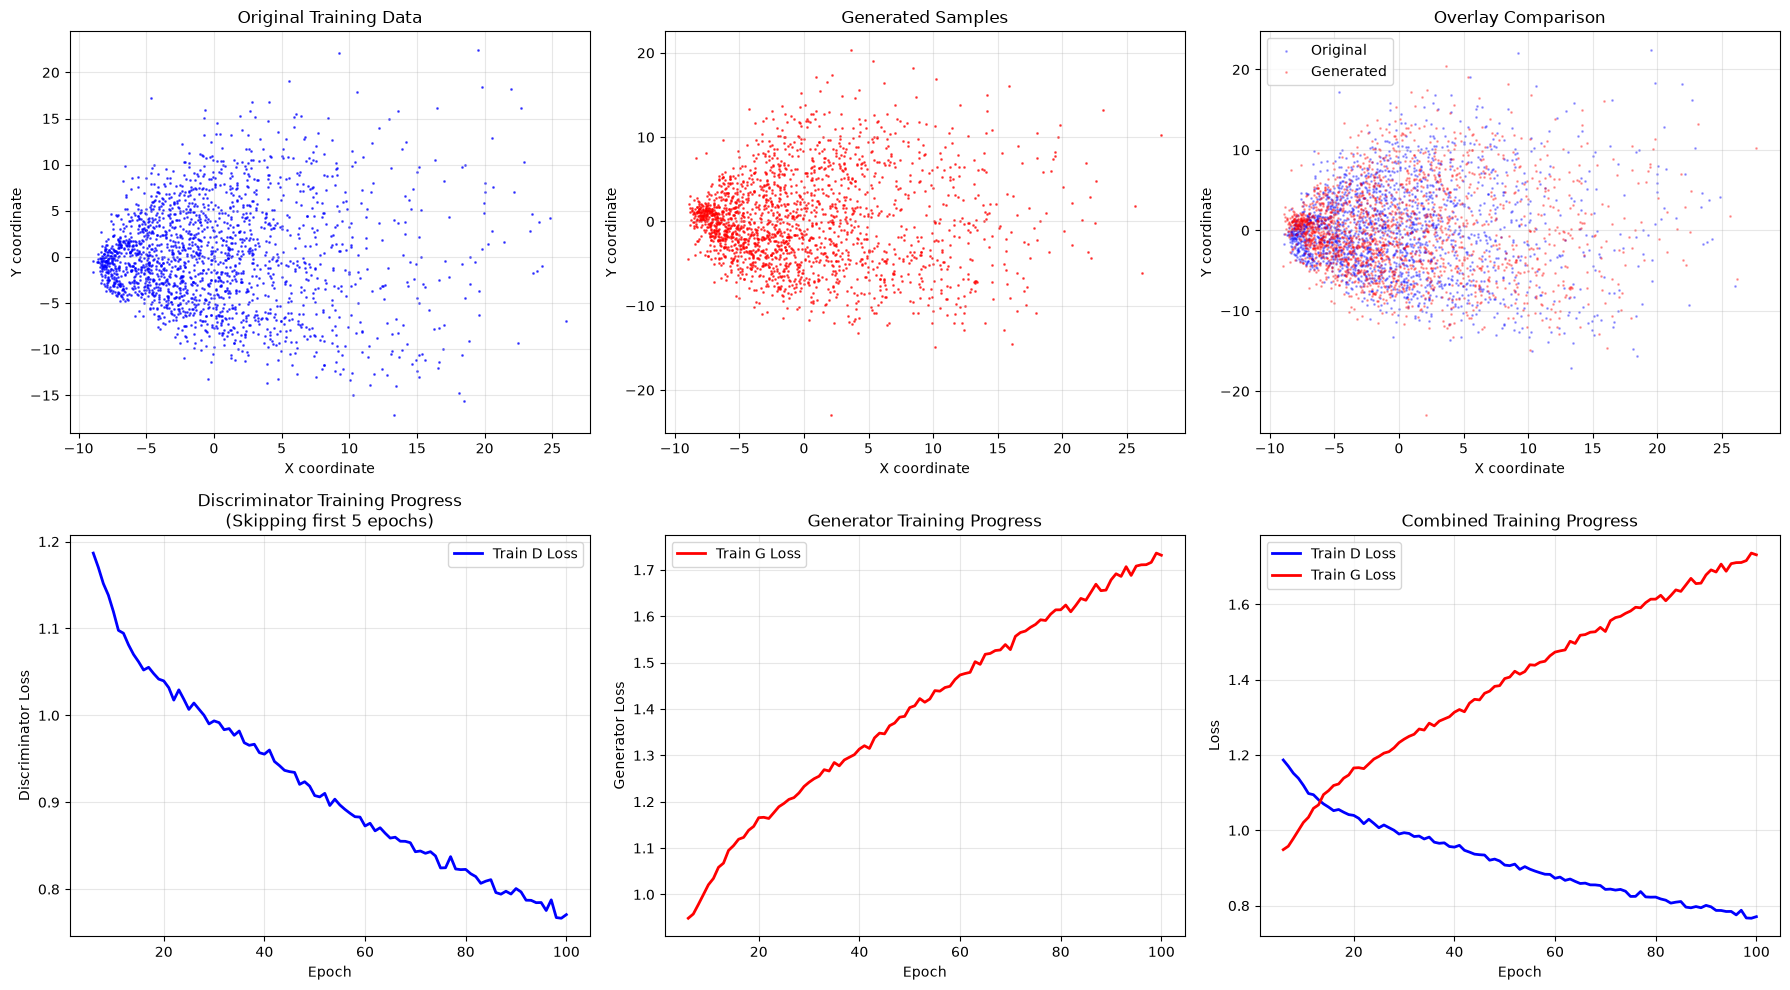

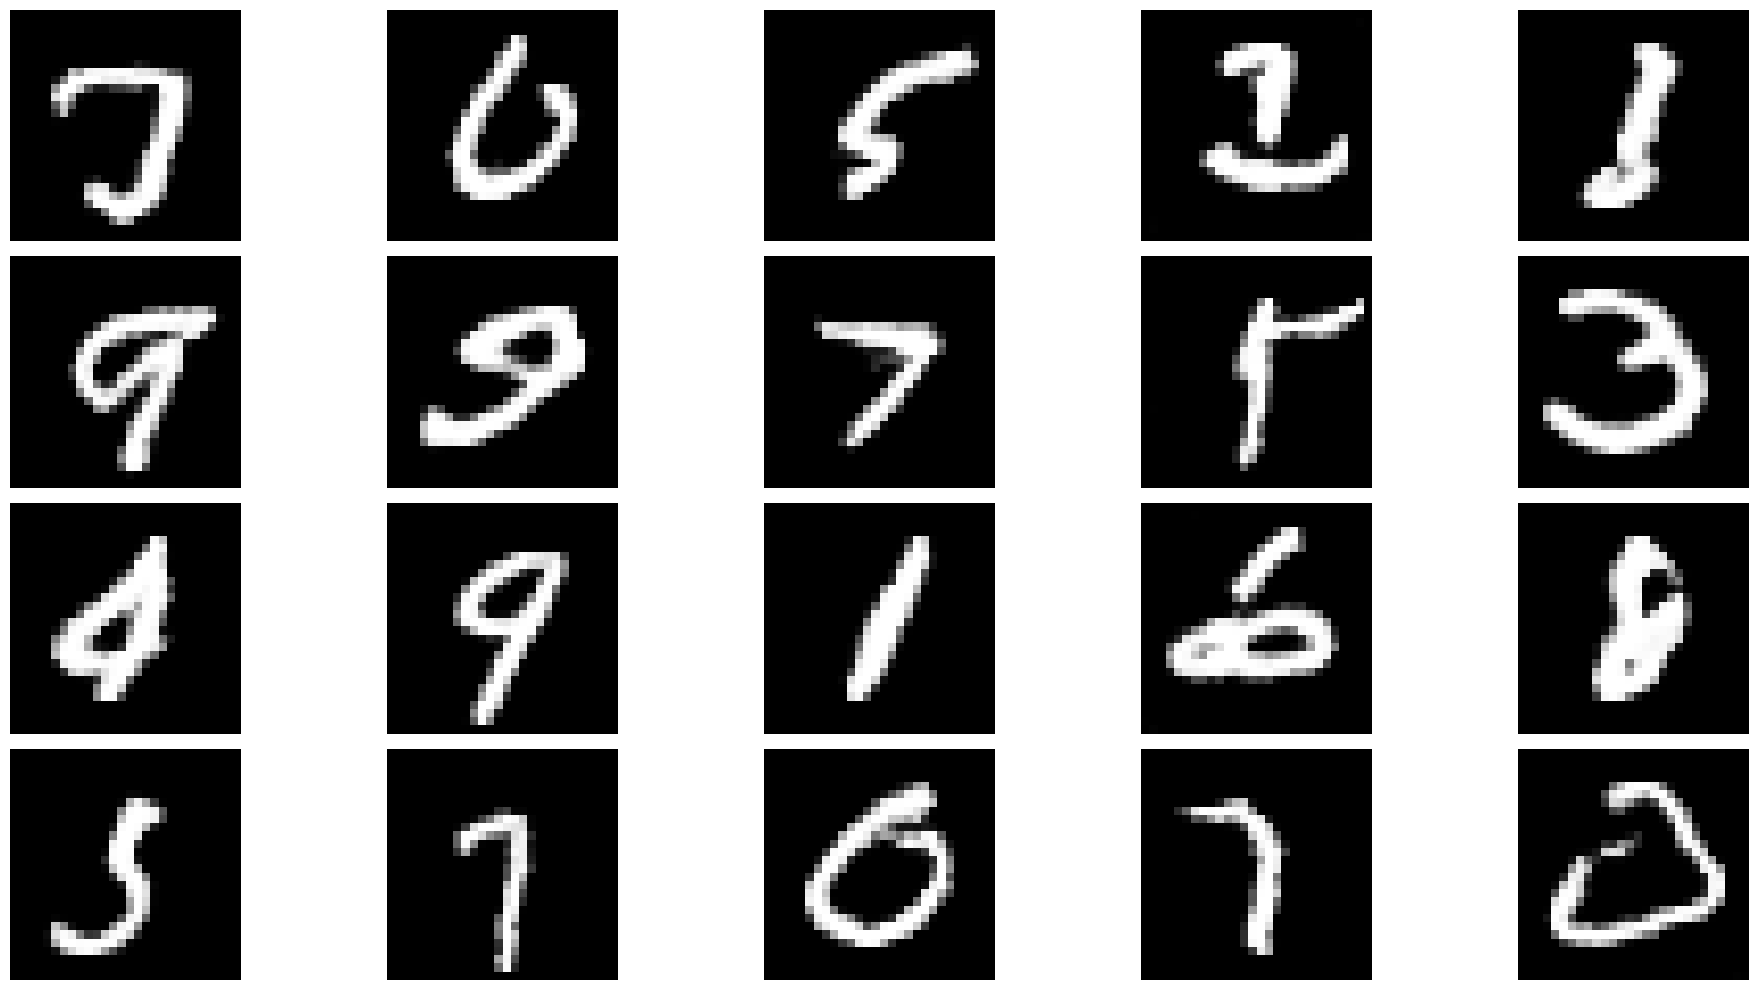

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


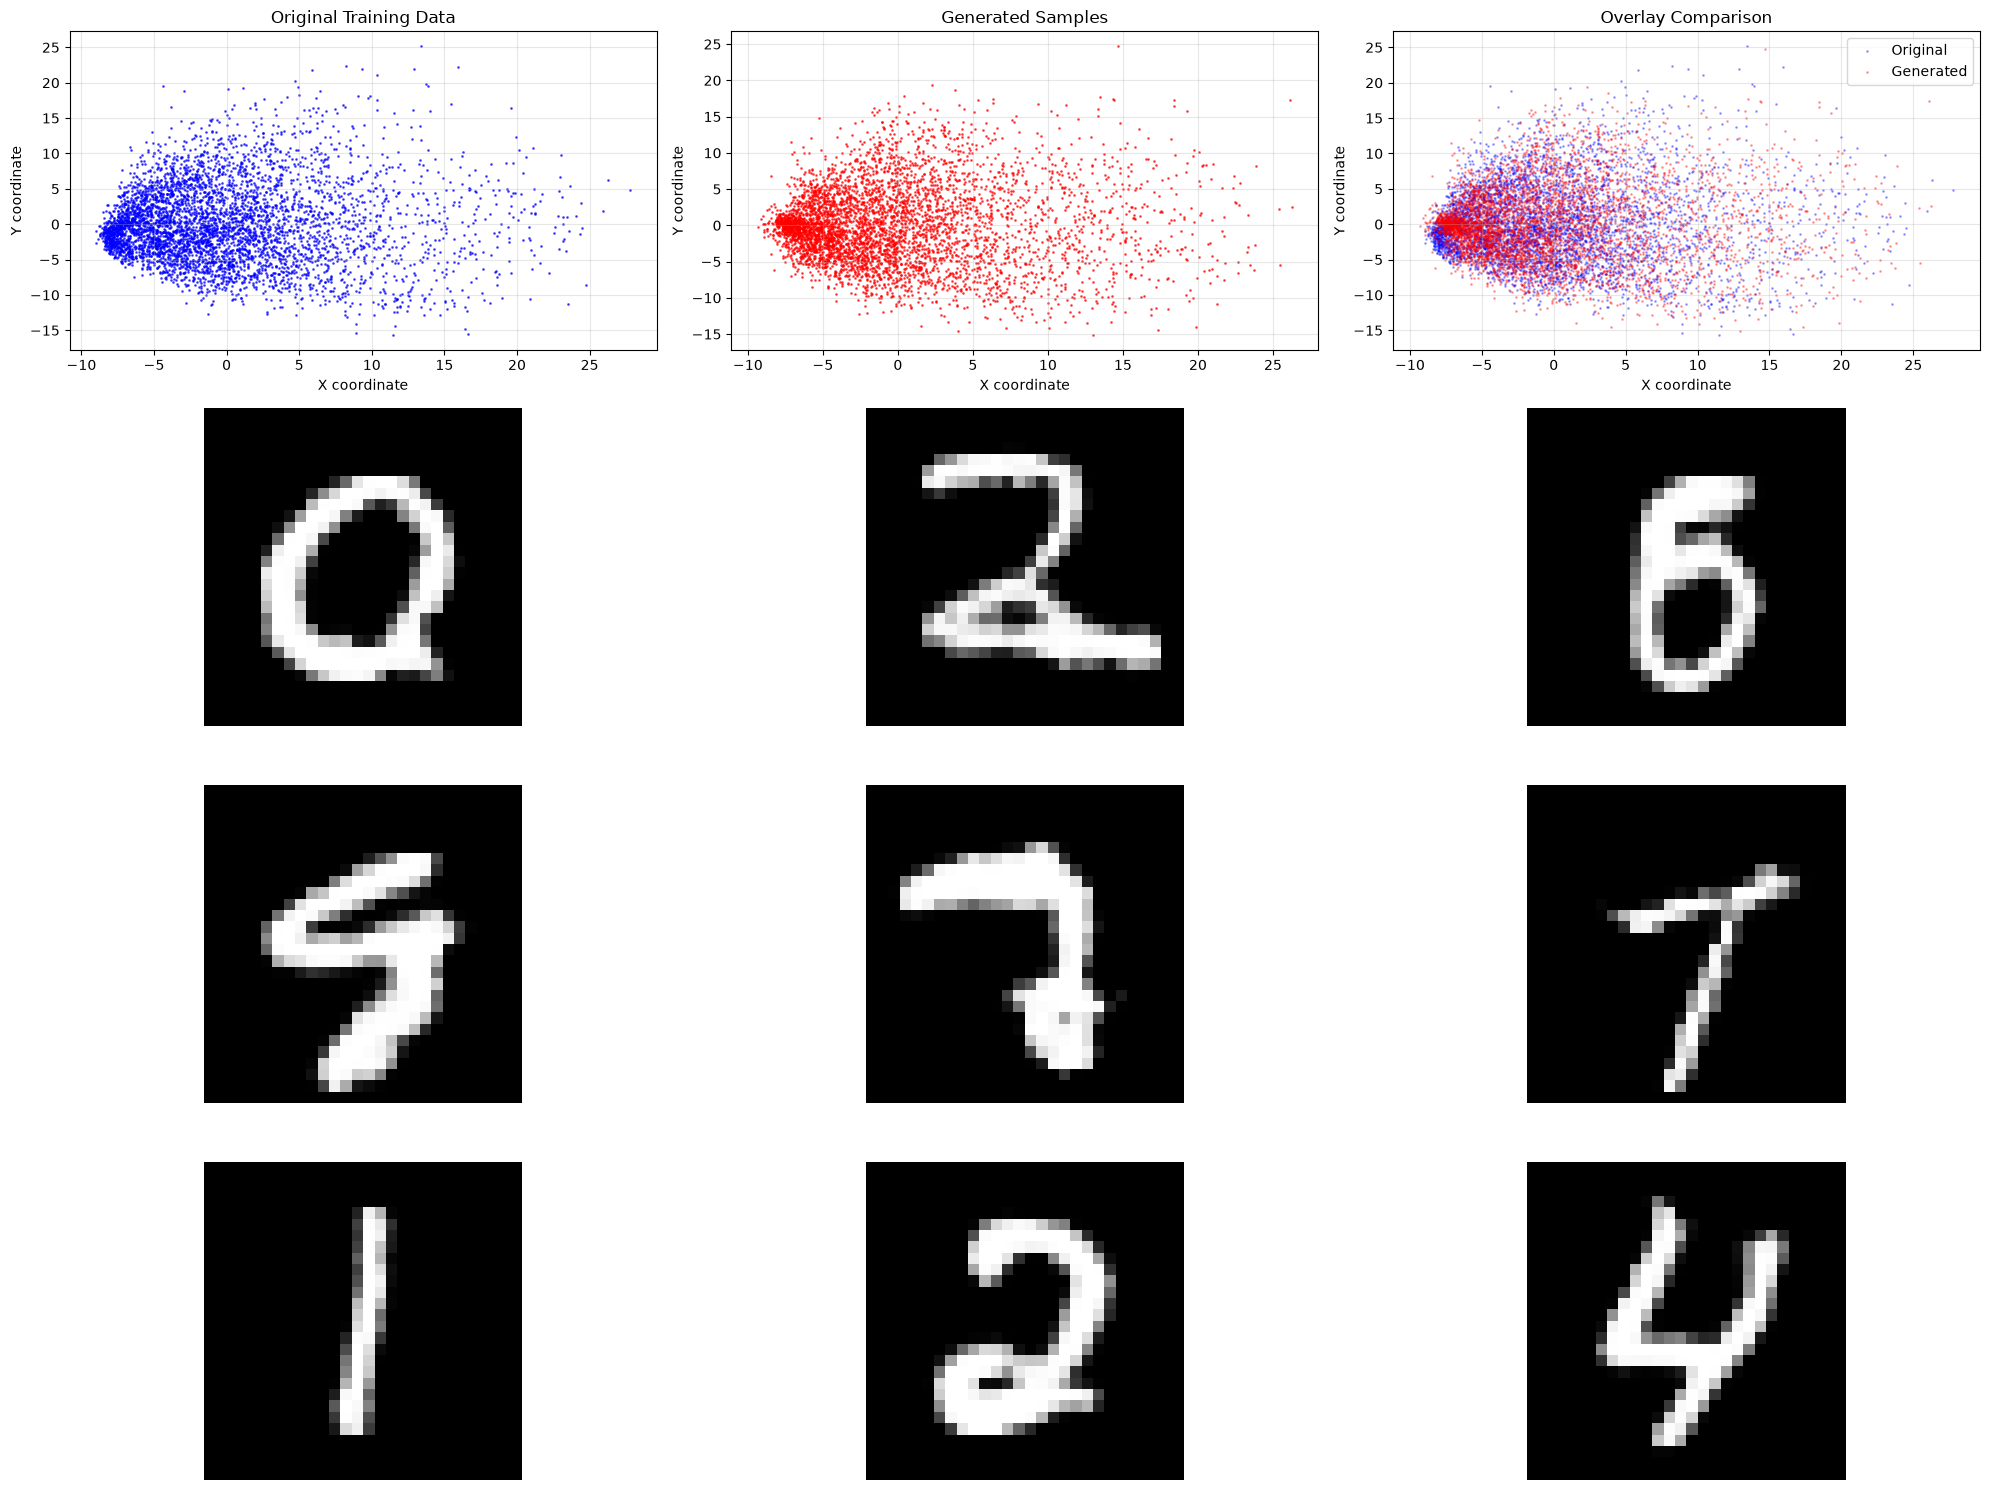

Real data confidence: 0.642
Fake data confidence: 0.288


In [18]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
